# Jev topic coverage, duration and associations

Uses the completed Jev labels on the **current native semantic segments**. No API calls, embeddings or topic-model fitting. Run all cells to show **both topic levels for combined, 2025 and 2026 views**. Use `RUN_LEVELS` and `RUN_YEARS` to limit views when desired. Counts use one primary topic per segment; parents are dictionary rollups.

Duration means **time attributed to a topic within a talk**, not the full runtime of a talk mentioning it. We report total observed time, mean per containing talk, and mean across all talks (including zeros). Unassigned content remains visible in coverage and duration tables and is excluded from associations by default.

The years refer to **festival programme dates**, not podcast publication dates: 114 talks are from 2025 and 105 from 2026. Detailed Jev topics remain the same original 236-topic vocabulary across years; no year-specific topic-model fitting or relabeling is performed. Topic tables and segment assignments are exported separately per year. Counts, all-talk means, observed-duration HDIs and topic associations use that scope's denominator. Organizer associations use only known-organizer talks within the same year (108/114 in 2025; 105/105 in 2026). This preserves meaningful comparisons while making coverage differences explicit.

In [1]:
from pathlib import Path
import sys, json, hashlib, re, html
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
from textwrap import fill
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import Image, Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
BASE = ROOT / "data/topic-analysis/results"
LEVEL = "high_level"  # initial load only
RUN_LEVELS = ("high_level", "detailed")
RUN_YEARS = (None, 2025, 2026)  # None = combined; programme year, not publication year
TOP_N = 30  # charts only; exported tables always contain all topics
MIN_SHARED_TALKS = 3
EXCLUDE_UNASSIGNED_FROM_ASSOCIATIONS = True
HDI_PROB = 0.95
SHOW_STATIC = True
BAR_COLOR = "#ADD8E6"  # light blue for every bar
SMOOTH_ALPHA = 0.5  # added to each cell of a 2x2 contingency table
DISCOUNT_K = 5.0  # support discount = shared / (shared + K), an exploratory heuristic
OUT = BASE / "jev-topic-analysis" / LEVEL
OUT.mkdir(parents=True, exist_ok=True)
assert LEVEL in {"detailed", "high_level"}


## Talks with no topic besides unassigned

A talk counts here when **every current native semantic segment has Jev topic `-1`**: it has zero assigned detailed topics and therefore no assigned high-level category. Talks with even one assigned segment are excluded. This uses saved Jev primary labels, not the original BERTopic outlier labels. Counts describe the transcribed semantic segments, not any untranscribed recording portions.

**Current result:** 2025 has **1 of 114 talks (0.88%)** with only unassigned Jev segments; 2026 has **0 of 105 (0%)**. Combined, that is **1 of 219 (0.46%)**. The talk is **“Milliseid lasteraamatuid tahame – lastega ja lastele”** (2025; episode `2258666735`).


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import display
coverage_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
coverage_out = coverage_root / "data/topic-analysis/results/jev-topic-analysis/year-comparison"
display(pd.read_csv(coverage_out / "talks-only-unassigned-summary.csv").round(2))
only_unassigned_talks = pd.read_csv(coverage_out / "talks-only-unassigned.csv")
if only_unassigned_talks.empty:
    print("No talks are entirely unassigned: every talk has at least one assigned Jev topic.")
else:
    display(only_unassigned_talks)


,programme_year,total_talks,only_unassigned_talks,percent_only_unassigned
0,2025,114,1,0.88
1,2026,105,0,0.00
2,Combined,219,1,0.46


,episode_id,title,programme_year,segments,assigned_segments,unassigned_segments,only_unassigned
0,2258666735,Milliseid lasteraamatuid tahame – lastega ja l...,2025,1,0,1,True


In [3]:
source = BASE / "segment-dataset/all-segments.parquet"
labels_path = BASE / "jev-semantic-all/assignments.parquet"
manifest = json.loads((BASE / "jev-semantic-all/manifest.json").read_text(encoding="utf-8"))
sha256 = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
assert sha256(source) == manifest["source_sha256"], "Source changed: regenerate matching Jev exports"
segments = pd.read_parquet(source).query("segmentation == 'semantic'").copy()
labels = pd.read_parquet(labels_path)
assert segments.segment_key.is_unique and labels.segment_key.is_unique
assert set(segments.segment_key) == set(labels.segment_key)
data = segments.merge(labels, on="segment_key", validate="one_to_one")
metadata_path = BASE / "talk-metadata/talks.parquet"
talk_metadata = pd.read_parquet(metadata_path) if metadata_path.exists() else pd.DataFrame()
if not talk_metadata.empty:
    assert talk_metadata.episode_id.is_unique
    assert set(talk_metadata.episode_id) == set(segments.episode_id)
    enrichment = [c for c in talk_metadata if c.startswith("organizer") or c.startswith("programme")]
    data = data.merge(talk_metadata[["episode_id", *enrichment]], on="episode_id", validate="many_to_one")
id_col, name_col = (("jev_topic_id", "jev_topic_name") if LEVEL == "detailed" else
                    ("jev_high_level_id", "jev_high_level_name"))
data["analysis_topic"] = data[id_col].astype(str)
data["analysis_name"] = data[name_col]
data["minutes"] = (data.end_seconds - data.start_seconds) / 60
assert (data.minutes > 0).all()
# Current semantic intervals must not overlap; otherwise sum would double-count time.
ordered = data.sort_values(["episode_id", "start_seconds"])
previous_end = ordered.groupby("episode_id").end_seconds.shift()
assert (ordered.start_seconds >= previous_end.fillna(-np.inf) - 1e-6).all()
talk_ids = pd.Index(sorted(data.episode_id.unique()), name="episode_id")
N = len(talk_ids)
styles = json.loads((BASE / "high-level-topics/category-style.json").read_text(encoding="utf-8"))
print(f"{len(data):,} native semantic segments; {N} deduplicated talks; level={LEVEL}")

assert data.programme_year.notna().all(), "Every talk needs verified programme year"
all_data = data.copy()
all_talk_metadata = talk_metadata.copy()
display(all_talk_metadata.groupby("programme_year").agg(talks=("episode_id", "nunique"),
    organizers=("organizer", lambda s: s.ne("").sum())))


4,126 native semantic segments; 219 deduplicated talks; level=high_level


,talks,organizers
programme_year,,
2025,114,108
2026,105,105


## Segments and talks per topic
A talk is counted once for each topic it contains. Talk counts are nonadditive; a talk can contain several topics. All bars use light blue. Detailed-topic charts show the top `TOP_N`; full tables are exported.

## Mean topic time with 95% HDI of observed durations

Light-blue bars show mean topic time; black capped lines show **95% ArviZ HDIs of the observed durations across talks**. The conditional chart uses containing talks only. The all-talk chart includes zeros for talks without the topic, within the selected year or combined scope. No bootstrap or posterior sampling is used.

These intervals describe variation between talks, **not uncertainty in the mean**, which is exact for this corpus given its labels. [`arviz.hdi`](https://python.arviz.org/en/v0.23.4/api/generated/arviz.hdi.html) calculates a shortest contiguous interval containing approximately 95% of observations (`multimodal=False`). With small samples, discrete coverage is approximate; fewer than two containing talks get no conditional interval. Zero-heavy all-talk distributions can have an HDI of [0, 0]; a contiguous HDI can bridge modes and need not contain the mean. Total time has no interval. The table retains observed quartiles and median as additional descriptive measures.

**What the two means measure:**

- **Mean across all talks** = total minutes assigned to the topic ÷ **number of talks in the scope** (219 combined, 114 in 2025 or 105 in 2026). Talks without the topic contribute zero.
- **Mean per containing talk** = total minutes assigned to the topic ÷ **number of talks containing it** (at least one assigned segment).

For example, a topic occupying **100 minutes across 10 talks** has a mean of **0.46 minutes across all talks** (`100 / 219`) and **10 minutes per containing talk** (`100 / 10`). Both measure time spent on the topic, not the full runtime of those talks. Each talk contributes its summed topic duration once, rather than each segment being treated as a separate talk.


## Topic co-occurrence within talks

Presence means at least one segment assigned to that topic in the talk. This is talk-level association, not simultaneous discussion, adjacency or causation. Long and diverse talks have more opportunities to contain pairs. All talks within the scope remain in the denominator even when unassigned labels are excluded.

For `a` and `b`, let `c` be shared talks, `na`, `nb` their talk counts, and `N` eligible talks. **NPMI** = `log((c/N)/((na/N)*(nb/N))) / -log(c/N)`. Zero overlap has limit −1; all-universal pairs are undefined. Scores do not have a significance cutoff.

Compare four views:
- Raw NPMI, retaining negative association.
- Positive NPMI: `max(NPMI, 0)`; negative information is discarded.
- Smoothed NPMI: add `SMOOTH_ALPHA` to each of the four binary contingency cells, then recompute probabilities consistently. This gives finite estimates for unseen pairs and shrinks sparse extremes.
- Support-discounted NPMI: `NPMI * c/(c+DISCOUNT_K)`, an explicitly exploratory heuristic that reduces small-support scores, not a significance test.

Tables include joint counts, expected overlap under independence, lift and Jaccard. Heatmaps mask pairs below `MIN_SHARED_TALKS`; exports retain all pairs, including zero overlaps. Changing the threshold changes display/ranking, not the calculation.

References: [Bouma, normalized PMI](https://svn.spraakbanken.gu.se/repos/gerlof/pub/www/Docs/npmi-pfd.pdf); [Williams on sparse coincidences and PMI](https://direct.mit.edu/neco/article/34/10/2037/112572/On-Suspicious-Coincidences-and-Pointwise-Mutual); [Role and Nadif on significant co-occurrence](https://aclanthology.org/W13-3503/). The support-discount heuristic here is not presented as their proposed estimator.

## Topic–organizer associations from metadata

The podcast publisher/author is **not** the talk organizer. Organizer labels are cached from the [official 2026 programme](https://arvamusfestival.ee/kava2026/) and [2025 archive](https://arvamusfestival.ee/2025-arhiiv/), supplemented by explicit fields in saved RSS descriptions or a verified override table. No organizations are inferred from talk titles, speakers, or transcript mentions.

The cell searches saved RSS snapshots for labeled lines such as `Arutelu korraldaja: ...`, retaining the source text and file. `organizer-overrides.csv` accepts one row per `(episode_id, organizer)`, plus `source` and `evidence`; a talk may have multiple organizers. Unverified/missing rows are excluded. A template covers all canonical talks. Organization names are only whitespace/case normalized; aliases and ambiguous multi-organization strings require editorial review.

Topic–organizer NPMI uses **only talks with known organizers** as its denominator, with topic and organizer marginals calculated on that same subset. Missing metadata is not treated as an organization. Coverage is reported before any association plot; incomplete coverage can bias associations.

All **219 canonical talks** now match programme entries across 2025 and 2026. **213 have explicit organizer labels** (105 from 2026 and 108 from 2025); six matched 2025 entries have empty organizer fields. `programme-match-audit.csv` records normalized-title matches, reviewed title variants and programme event IDs. Publication must not precede the event; recurring titles use the latest eligible programme. Joint organizer labels stay intact.

The merged metadata is saved in `results/talk-metadata/talks.parquet` / `talks.csv`; `segments-with-metadata.parquet` attaches it to all native segment rows while preserving the original dataset. This notebook joins it by canonical episode ID. Organizers, moderators, panelists, stage curators and sponsor/support text are separate fields. The six missing organizers remain missing, with their available programme metadata displayed below. Repeated workshop sessions keep all possible event IDs when the organizer agrees; session times can remain unresolved.

Run `uv run --group topic-analysis python scripts/export_programme_organizers.py` from the repository root to refresh both programme caches and merged metadata. Ordinary notebook runs stay offline.

## Saved outputs and interpretation

All tables include every topic/pair, irrespective of chart truncation. Saved HTML charts are standalone and interactive. Every bar chart also has a static 180-dpi PNG and vector SVG; `SHOW_STATIC` controls inline static display without disabling export. Duration sums measure semantic-segment time, which may exclude transcript gaps and recording introductions. Primary labels omit secondary subjects; associations reflect this labeling policy. Co-occurrence scores are exploratory, without multiple-testing claims.

In [4]:
def run_analysis(year, level):
    LEVEL = level
    scope_label = f"{year if year is not None else 'All years'} / {level.replace('_', ' ')}"
    data = all_data.copy() if year is None else all_data.loc[all_data.programme_year.eq(year)].copy()
    assert len(data), f"No data for {year}"
    id_col, name_col = (("jev_topic_id", "jev_topic_name") if level == "detailed" else
                        ("jev_high_level_id", "jev_high_level_name"))
    data["analysis_topic"] = data[id_col].astype(str)
    data["analysis_name"] = data[name_col]
    talk_ids = pd.Index(sorted(data.episode_id.unique()), name="episode_id")
    N = len(talk_ids)
    talk_metadata = all_talk_metadata.loc[all_talk_metadata.episode_id.isin(talk_ids)].copy()
    OUT = BASE / "jev-topic-analysis" / level
    if year is not None:
        OUT = OUT / str(year)
    OUT.mkdir(parents=True, exist_ok=True)
    data.to_parquet(OUT / "topic-segments.parquet", index=False)
    display(Markdown(f"## {scope_label}\n{N} talks · {len(data):,} semantic segments. "
                     "Year-specific plots use only this scope's talks; labels share the original vocabulary."))
    display(Markdown("### Segments and talks per topic"))
    coverage = data.groupby("analysis_topic").agg(
        topic_name=("analysis_name", "first"), high_level_id=("jev_high_level_id", "first"),
        segments=("segment_key", "size"), talks=("episode_id", "nunique"),
        total_minutes=("minutes", "sum"))
    coverage["label"] = coverage.index + ": " + coverage.topic_name
    coverage["color"] = coverage.high_level_id.map(lambda k: styles[k]["color"])
    coverage.to_csv(OUT / "coverage.csv", index_label="topic_id")

    def bars(table, value, title, lower=None, upper=None):
        title = f"{scope_label} · {title}"
        t = table.nlargest(TOP_N, value).sort_values(value)
        fig = go.Figure(go.Bar(x=t[value], y=t.label, orientation="h", marker_color=BAR_COLOR,
                              customdata=t[["segments", "talks"]],
                              hovertemplate="%{y}<br>Value: %{x:.3f}<br>Segments: %{customdata[0]}"
                                            "<br>Talks: %{customdata[1]}<extra></extra>"))
        if lower:
            xs, ys = [], []
            for row in t.itertuples():
                lo, hi = getattr(row, lower), getattr(row, upper)
                if np.isfinite(lo) and np.isfinite(hi):
                    xs.extend([lo, hi, None]); ys.extend([row.label, row.label, None])
            fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines+markers",
                          line=dict(color="black", width=2),
                          marker=dict(symbol="line-ns", size=10),
                          name="95% observed-duration HDI", hoverinfo="x+y"))
        fig.update_layout(title=title, height=max(450, len(t)*27), margin=dict(l=20),
                          xaxis_title=value.replace("_", " "), showlegend=False)
        display(fig)
        fig.write_html(OUT / (value + ".html"), include_plotlyjs=True)

        static, ax = plt.subplots(figsize=(16, max(5, len(t)*0.43)))
        y = np.arange(len(t))
        ax.barh(y, t[value], color=BAR_COLOR, height=0.72)
        if lower:
            lo, hi = t[lower].to_numpy(float), t[upper].to_numpy(float)
            valid = np.isfinite(lo) & np.isfinite(hi)
            ax.hlines(y[valid], lo[valid], hi[valid], color="black", linewidth=2)
            ax.plot(lo[valid], y[valid], "|", color="black", markersize=10)
            ax.plot(hi[valid], y[valid], "|", color="black", markersize=10)
            ax.text(0, -0.09, "Light-blue bar: mean; black line: 95% HDI of observed talk durations",
                    transform=ax.transAxes, fontsize=9)
        ax.set_yticks(y, [fill(label, width=58) for label in t.label], fontsize=9)
        ax.set_xlabel(value.replace("_", " "))
        ax.set_title(title, loc="left", fontsize=12, pad=12)
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        static.tight_layout()
        static.savefig(OUT / (value + ".png"), dpi=180, bbox_inches="tight")
        static.savefig(OUT / (value + ".svg"), bbox_inches="tight")
        if SHOW_STATIC:
            display(Image(filename=str(OUT / (value + ".png"))))
        plt.close(static)

    bars(coverage, "segments", "Native segments per topic")
    bars(coverage, "talks", "Distinct talks containing each topic")
    display(coverage.sort_values("segments", ascending=False).drop(columns="color"))

    display(Markdown("### Topic duration: totals, means and observed 95% HDIs"))
    duration_by_talk = data.pivot_table(index="episode_id", columns="analysis_topic",
                                      values="minutes", aggfunc="sum", fill_value=0).reindex(talk_ids)
    duration_by_talk.to_csv(OUT / "talk-topic-minutes.csv")
    values = duration_by_talk.to_numpy(float)
    time_stats = coverage.reindex(duration_by_talk.columns).copy()
    time_stats["mean_all_talks_minutes"] = values.mean(axis=0)
    time_stats["mean_containing_talk_minutes"] = values.sum(axis=0) / (values > 0).sum(axis=0)
    for j, topic in enumerate(duration_by_talk.columns):
        observed = values[:, j][values[:, j] > 0]
        time_stats.loc[topic, ["all_hdi_low", "all_hdi_high"]] = az.hdi(
            values[:, j], hdi_prob=HDI_PROB, multimodal=False)
        if len(observed) >= 2:
            time_stats.loc[topic, ["containing_hdi_low", "containing_hdi_high"]] = az.hdi(
                observed, hdi_prob=HDI_PROB, multimodal=False)
        time_stats.loc[topic, ["min_containing_minutes", "p25_containing_minutes",
                              "median_containing_minutes", "p75_containing_minutes",
                              "max_containing_minutes"]] = np.quantile(observed, [0, .25, .5, .75, 1])
    time_stats.to_csv(OUT / "duration-summary.csv", index_label="topic_id")
    bars(time_stats, "total_minutes", "Total observed topic time (minutes)")
    bars(time_stats, "mean_containing_talk_minutes", "Mean topic time per containing talk + 95% observed-duration HDI",
         "containing_hdi_low", "containing_hdi_high")
    bars(time_stats, "mean_all_talks_minutes", "Mean topic time across all talks + 95% observed-duration HDI",
         "all_hdi_low", "all_hdi_high")
    display(time_stats.drop(columns="color"))

    display(Markdown("### Topic co-occurrence tables"))
    presence = duration_by_talk.gt(0).astype(np.int64)
    if EXCLUDE_UNASSIGNED_FROM_ASSOCIATIONS:
        presence = presence.drop(columns=[c for c in ["-1", "unassigned"] if c in presence])

    def pair_table(left, right=None, alpha=SMOOTH_ALPHA, k=DISCOUNT_K):
        symmetric = right is None
        right = left if symmetric else right
        assert left.index.equals(right.index)
        assert len(left) > 0 and alpha > 0 and k > 0
        n = len(left)
        a, b = left.to_numpy(np.int64), right.to_numpy(np.int64)
        joint = a.T @ b
        na, nb = a.sum(0), b.sum(0)
        rows = []
        for i, ka in enumerate(left.columns):
            for j, kb in enumerate(right.columns):
                if symmetric and j <= i: continue
                c, ca, cb = int(joint[i,j]), int(na[i]), int(nb[j])
                expected = ca*cb/n
                if c == 0: raw = -1.0 if ca and cb else np.nan
                elif c == n: raw = np.nan
                else: raw = np.log(c*n/(ca*cb)) / -np.log(c/n)
                den = n + 4*alpha
                p11 = (c+alpha)/den
                pa, pb = (ca+2*alpha)/den, (cb+2*alpha)/den
                smooth = np.log(p11/(pa*pb)) / -np.log(p11)
                rows.append(dict(topic_a=str(ka), topic_b=str(kb), shared_talks=c,
                    a_talks=ca, b_talks=cb, eligible_talks=n, expected_shared=expected,
                    lift=c/expected if expected else np.nan,
                    jaccard=c/(ca+cb-c) if ca+cb-c else np.nan,
                    npmi=raw, positive_npmi=max(raw,0) if np.isfinite(raw) else np.nan,
                    smoothed_npmi=smooth, discounted_npmi=raw*c/(c+k)))
        return pd.DataFrame(rows)

    pairs = pair_table(presence)
    names = coverage.topic_name.to_dict()
    pairs["name_a"] = pairs.topic_a.map(names)
    pairs["name_b"] = pairs.topic_b.map(names)
    pairs.to_csv(OUT / "topic-cooccurrence.csv", index=False)
    supported = pairs.query("shared_talks >= @MIN_SHARED_TALKS")
    display(supported.sort_values("discounted_npmi", ascending=False).head(30))

    display(Markdown("### Topic co-occurrence heatmap"))
    metrics = ["npmi", "positive_npmi", "smoothed_npmi", "discounted_npmi"]
    show_topics = presence.sum().nlargest(TOP_N).index.tolist()
    matrices, hover = [], np.full((len(show_topics), len(show_topics)), np.nan)
    for metric in metrics:
        m = pd.DataFrame(np.nan, index=show_topics, columns=show_topics)
        for row in supported.itertuples():
            if row.topic_a in m.index and row.topic_b in m.columns:
                m.loc[row.topic_a,row.topic_b] = m.loc[row.topic_b,row.topic_a] = getattr(row,metric)
        matrices.append(m.to_numpy())
    for row in pairs.itertuples():
        if row.topic_a in show_topics and row.topic_b in show_topics:
            i,j = show_topics.index(row.topic_a), show_topics.index(row.topic_b)
            hover[i,j] = hover[j,i] = row.shared_talks
    axis_labels = [f"{t}: {names[t]}" for t in show_topics]
    fig = go.Figure(go.Heatmap(z=matrices[0], x=axis_labels, y=axis_labels,
        customdata=hover, colorscale="RdBu", reversescale=True, zmin=-1, zmax=1,
        hovertemplate="%{y}<br>%{x}<br>Score: %{z:.3f}<br>Shared talks: %{customdata}<extra></extra>"))
    fig.update_layout(title=f"{scope_label} · Talk-level topic association (support ≥ {MIN_SHARED_TALKS})",
        height=850, updatemenus=[dict(buttons=[dict(label=m, method="restyle", args=[{"z":[z]}])
                                            for m,z in zip(metrics,matrices)])])
    display(fig)
    fig.write_html(OUT / "topic-cooccurrence.html", include_plotlyjs=True)

    display(Markdown("### Topic–organizer associations and metadata coverage"))
    metadata_out = BASE / "jev-topic-analysis"
    metadata_out.mkdir(exist_ok=True)
    records = []
    organizer_pattern = re.compile(r"^\s*(?:arutelu\s+)?(?:korraldaja(?:d)?|organizer(?:s)?)\s*:\s*(.+)$", re.I)
    for rss in sorted((ROOT / "data/catalog").glob("*.xml")):
        for item in ET.parse(rss).findall("./channel/item"):
            episode = (item.findtext("guid") or "").rsplit("/",1)[-1]
            if episode not in talk_ids: continue
            description = html.unescape(item.findtext("description") or "")
            description = re.sub(r"<br\s*/?>|</p>|</div>", "\n", description, flags=re.I)
            description = re.sub(r"<[^>]+>", "", description)
            for line in description.splitlines():
                match = organizer_pattern.match(line)
                if match:
                    records.append(dict(episode_id=episode, organizer=match.group(1).strip(),
                                        source=str(rss.relative_to(ROOT)), evidence=line.strip()))
    organizers = pd.DataFrame(records, columns=["episode_id","organizer","source","evidence"])
    organizers.to_csv(metadata_out / "organizers-extracted.csv", index=False)
    programme_path = metadata_out / "programme-organizers.csv"
    if programme_path.exists():
        programme = pd.read_csv(programme_path, dtype=str).fillna("")
        assert set(programme.episode_id) <= set(all_data.episode_id)
        programme = programme.loc[programme.episode_id.isin(talk_ids)]
        organizers = pd.concat([organizers, programme], ignore_index=True)
    override_path = metadata_out / "organizer-overrides.csv"
    if override_path.exists():
        overrides = pd.read_csv(override_path, dtype=str).fillna("")
        assert {"episode_id","organizer","source","evidence"} <= set(overrides.columns)
        verified = overrides.query("organizer != '' and source != '' and evidence != ''")
        assert set(verified.episode_id) <= set(all_data.episode_id), "Override references unknown canonical talks"
        verified = verified.loc[verified.episode_id.isin(talk_ids)]
        organizers = pd.concat([organizers, verified], ignore_index=True)
    template = all_data[["episode_id","title"]].drop_duplicates().sort_values("title")
    for col in ["organizer","source","evidence"]: template[col] = ""
    template.to_csv(metadata_out / "organizer-template.csv", index=False)
    organizers = organizers.dropna(subset=["organizer"])
    organizers["organizer_key"] = organizers.organizer.map(lambda s: " ".join(s.split()).casefold())
    organizers = organizers.loc[organizers.organizer_key.ne("")].drop_duplicates(["episode_id","organizer_key"])
    organizers.to_csv(OUT / "organizer-metadata.csv", index=False)
    known = pd.Index(sorted(organizers.episode_id.unique()), name="episode_id")
    print(f"Verified organizer metadata: {len(known)}/{N} talks ({100*len(known)/N:.1f}%).")
    print(f"Template: {metadata_out / 'organizer-template.csv'}")
    if not talk_metadata.empty:
        display(talk_metadata[["episode_id", "title", "programme_year", "organizer",
                               "organizer_match_status", "programme_stage", "programme_moderator"]])
        missing_organizers = talk_metadata.loc[talk_metadata.organizer.eq(""),
            ["episode_id", "title", "programme_stage", "programme_curator", "programme_support_text"]]
        print("Programme entries with missing organizer fields (other roles are retained separately):")
        display(missing_organizers)
    if len(known):
        org_presence = pd.crosstab(organizers.episode_id, organizers.organizer_key).gt(0).astype(np.int64).reindex(known)
        topic_org = pair_table(presence.reindex(known), org_presence)
        topic_org["topic_name"] = topic_org.topic_a.map(names)
        topic_org.to_csv(OUT / "topic-organizer-cooccurrence.csv", index=False)
        eligible = topic_org.query("shared_talks >= @MIN_SHARED_TALKS")
        display(eligible.sort_values("discounted_npmi", ascending=False).head(30))
        if len(eligible):
            org_matrix = eligible.pivot(index="topic_a", columns="topic_b", values="discounted_npmi")
            org_matrix = org_matrix.reindex(presence.reindex(known).sum().nlargest(TOP_N).index).dropna(how="all")
            org_matrix.index = [f"{t}: {names[t]}" for t in org_matrix.index]
            org_fig = px.imshow(org_matrix, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                                title=f"{scope_label} · Topic–organizer support-discounted NPMI (known-metadata talks only)", aspect="auto")
            display(org_fig)
            org_fig.write_html(OUT / "topic-organizer.html", include_plotlyjs=True)
    else:
        print("No explicit organizers found for this corpus. No organizer associations computed.")
        print("Fill verified rows in organizer-template.csv, save as organizer-overrides.csv, then rerun.")

    display(Markdown("### Export manifest"))
    run_manifest = dict(level=LEVEL, programme_year=year, source_sha256=sha256(source), assignments_sha256=sha256(labels_path),
        jev_model=manifest["model"], fitted_model_key=manifest["fitted_model_key"],
        segments=len(data), talks=N,
        min_shared_talks=MIN_SHARED_TALKS, smooth_alpha=SMOOTH_ALPHA, discount_k=DISCOUNT_K,
        exclude_unassigned=EXCLUDE_UNASSIGNED_FROM_ASSOCIATIONS,
        organizer_known_talks=len(known),
        talk_metadata_sha256=sha256(metadata_path) if metadata_path.exists() else None,
        programme_metadata_sha256=sha256(programme_path) if programme_path.exists() else None, organizer_override_sha256=sha256(override_path) if override_path.exists() else None,
        interval="95% ArviZ HDI of observed talk-topic durations, not an interval for the mean",
        hdi_probability=HDI_PROB, arviz_version=az.__version__,
        static_formats=["png", "svg"])
    (OUT / "manifest.json").write_text(json.dumps(run_manifest, ensure_ascii=False, indent=2)+"\n")
    print(f"Saved analysis to {OUT}")



## Combined: high level charts

## All years / high level
219 talks · 4,126 semantic segments. Year-specific plots use only this scope's talks; labels share the original vocabulary.

### Segments and talks per topic

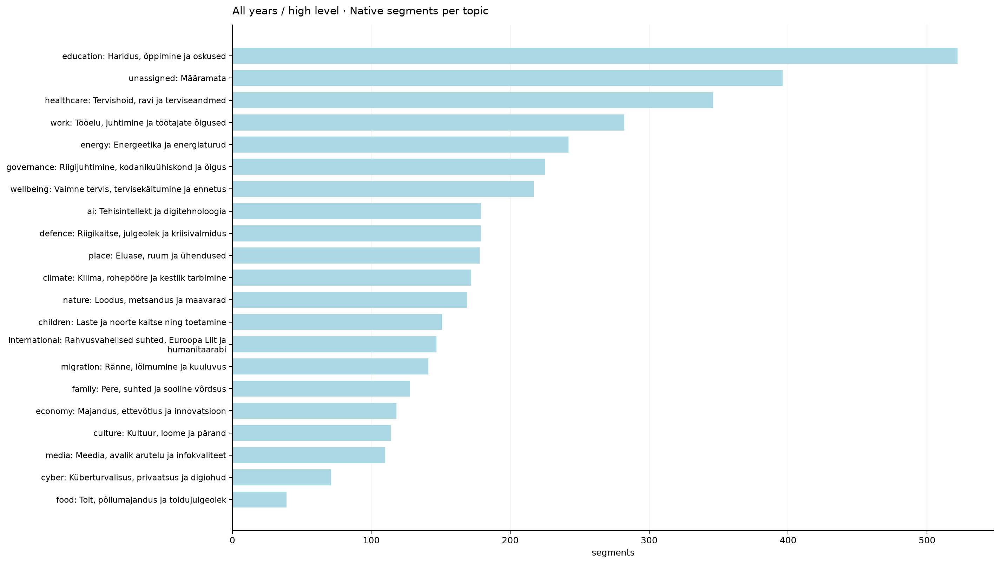

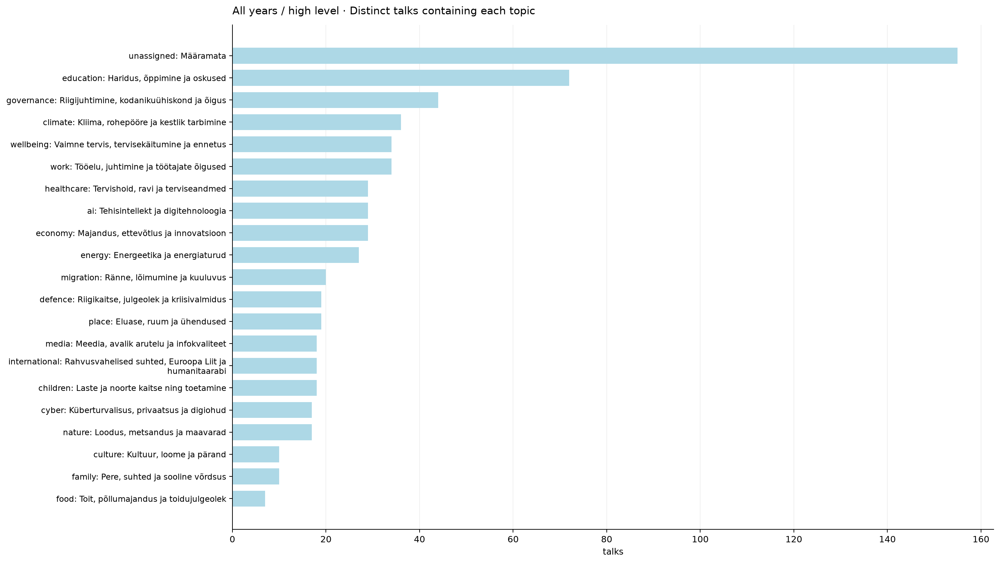

,topic_name,high_level_id,segments,talks,total_minutes,label
analysis_topic,,,,,,
education,"Haridus, õppimine ja oskused",education,522,72,2507.773117,"education: Haridus, õppimine ja oskused"
unassigned,Määramata,unassigned,396,155,1208.356633,unassigned: Määramata
healthcare,"Tervishoid, ravi ja terviseandmed",healthcare,346,29,1660.049317,"healthcare: Tervishoid, ravi ja terviseandmed"
work,"Tööelu, juhtimine ja töötajate õigused",work,282,34,1384.490800,"work: Tööelu, juhtimine ja töötajate õigused"
energy,Energeetika ja energiaturud,energy,242,27,1155.709167,energy: Energeetika ja energiaturud
governance,"Riigijuhtimine, kodanikuühiskond ja õigus",governance,225,44,1094.700367,"governance: Riigijuhtimine, kodanikuühiskond j..."
wellbeing,"Vaimne tervis, tervisekäitumine ja ennetus",wellbeing,217,34,993.027700,"wellbeing: Vaimne tervis, tervisekäitumine ja ..."
ai,Tehisintellekt ja digitehnoloogia,ai,179,29,817.393000,ai: Tehisintellekt ja digitehnoloogia
defence,"Riigikaitse, julgeolek ja kriisivalmidus",defence,179,19,881.833383,"defence: Riigikaitse, julgeolek ja kriisivalmidus"


### Topic duration: totals, means and observed 95% HDIs

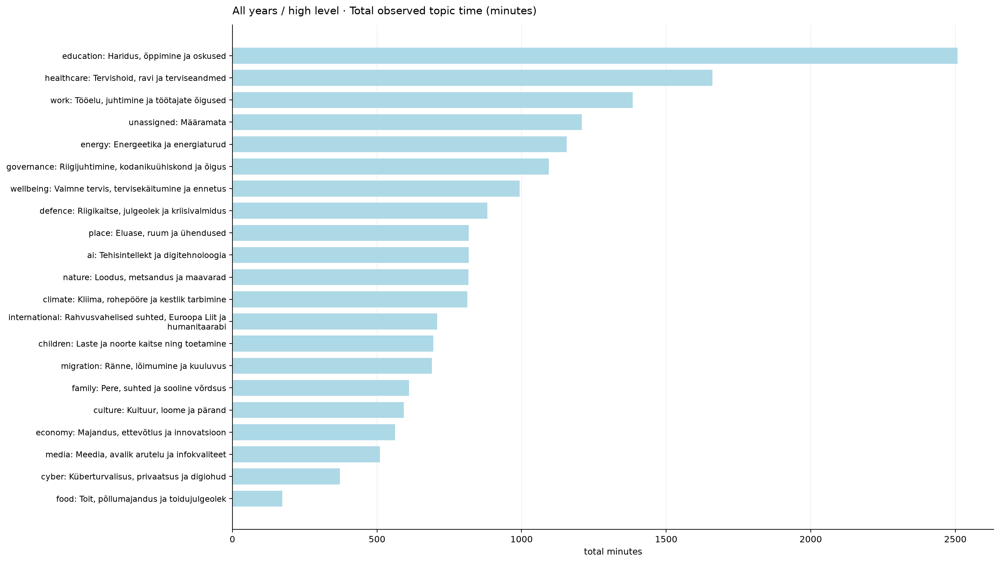

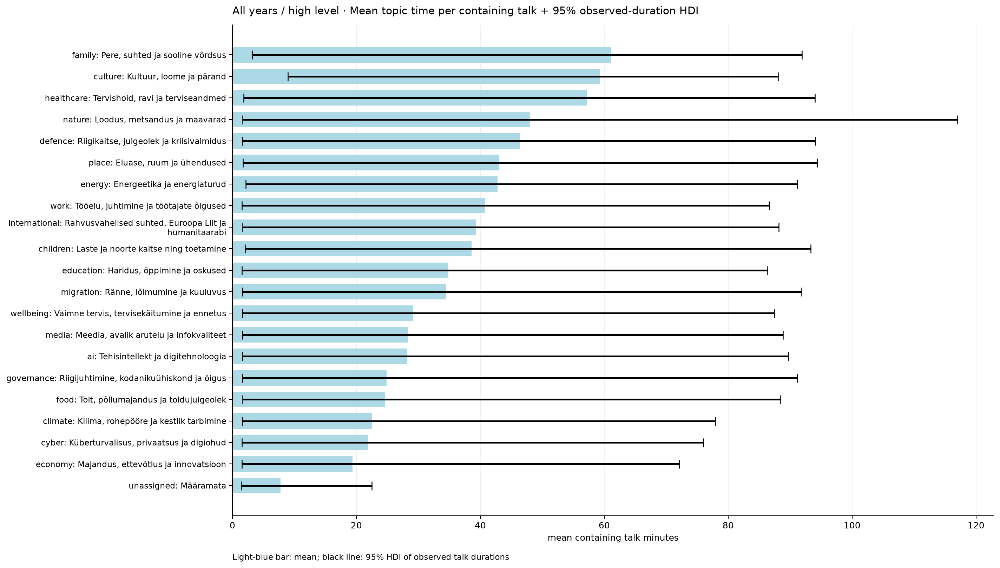

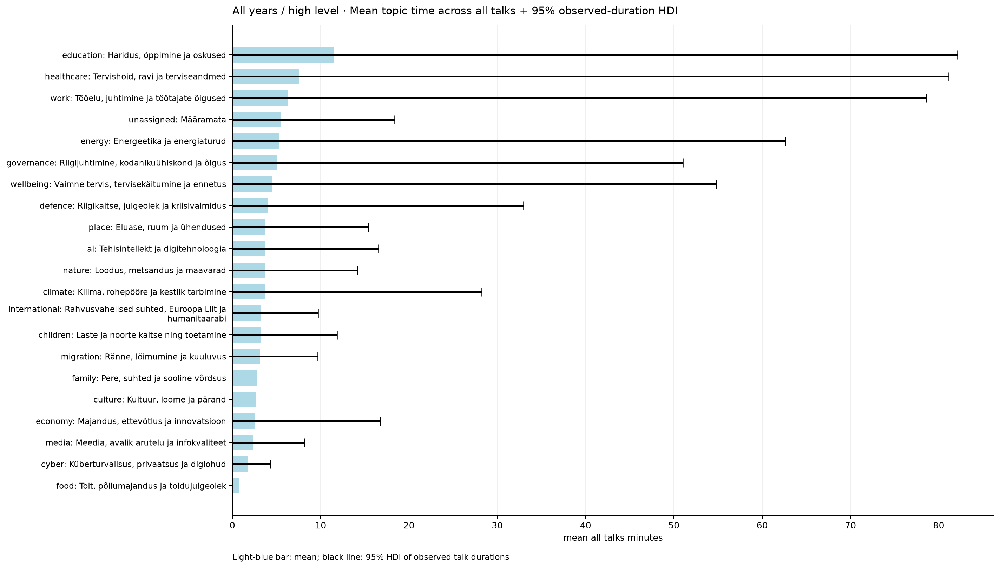

,topic_name,high_level_id,segments,talks,total_minutes,label,mean_all_talks_minutes,mean_containing_talk_minutes,all_hdi_low,all_hdi_high,containing_hdi_low,containing_hdi_high,min_containing_minutes,p25_containing_minutes,median_containing_minutes,p75_containing_minutes,max_containing_minutes
analysis_topic,,,,,,,,,,,,,,,,,
ai,Tehisintellekt ja digitehnoloogia,ai,179,29,817.393000,ai: Tehisintellekt ja digitehnoloogia,3.732388,28.185966,0.0,16.553333,1.613333,89.690133,1.613333,3.854000,8.648667,56.023750,93.206700
children,Laste ja noorte kaitse ning toetamine,children,151,18,695.050267,children: Laste ja noorte kaitse ning toetamine,3.173746,38.613904,0.0,11.838250,2.074000,93.306233,2.074000,5.085500,23.269783,74.139725,93.306233
climate,"Kliima, rohepööre ja kestlik tarbimine",climate,172,36,812.696533,"climate: Kliima, rohepööre ja kestlik tarbimine",3.710943,22.574904,0.0,28.223333,1.621333,77.936500,1.621333,5.785667,10.659000,29.942867,78.464000
culture,"Kultuur, loome ja pärand",culture,114,10,592.547150,"culture: Kultuur, loome ja pärand",2.705695,59.254715,0.0,0.000000,8.970667,88.078450,8.970667,45.478333,63.892942,79.507275,88.078450
cyber,"Küberturvalisus, privaatsus ja digiohud",cyber,71,17,372.342617,"cyber: Küberturvalisus, privaatsus ja digiohud",1.700195,21.902507,0.0,4.288667,1.562667,75.982717,1.562667,3.190000,5.252000,45.214817,75.982717
defence,"Riigikaitse, julgeolek ja kriisivalmidus",defence,179,19,881.833383,"defence: Riigikaitse, julgeolek ja kriisivalmidus",4.026636,46.412283,0.0,32.957333,1.570667,94.053000,1.570667,4.797333,64.392417,82.329825,94.053000
economy,"Majandus, ettevõtlus ja innovatsioon",economy,118,29,562.214400,"economy: Majandus, ettevõtlus ja innovatsioon",2.567189,19.386703,0.0,16.756667,1.562000,72.124667,1.562000,2.169333,6.870667,31.042667,74.583000
education,"Haridus, õppimine ja oskused",education,522,72,2507.773117,"education: Haridus, õppimine ja oskused",11.451019,34.830182,0.0,82.131433,1.560000,86.342517,1.560000,5.007000,15.461942,70.324804,95.653567
energy,Energeetika ja energiaturud,energy,242,27,1155.709167,energy: Energeetika ja energiaturud,5.277211,42.804043,0.0,62.651333,2.157333,91.198733,2.157333,9.387667,32.161317,75.802758,92.689633


### Topic co-occurrence tables

,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,name_a,name_b
42,climate,energy,20,36,27,219,4.438356,4.506173,0.465116,0.629016,0.629016,0.620533,0.503213,"Kliima, rohepööre ja kestlik tarbimine",Energeetika ja energiaturud
50,climate,nature,10,36,17,219,2.794521,3.578431,0.232558,0.413067,0.413067,0.409693,0.275378,"Kliima, rohepööre ja kestlik tarbimine","Loodus, metsandus ja maavarad"
3,ai,cyber,8,29,17,219,2.251142,3.553753,0.210526,0.383126,0.383126,0.382634,0.235770,Tehisintellekt ja digitehnoloogia,"Küberturvalisus, privaatsus ja digiohud"
40,climate,economy,12,36,29,219,4.767123,2.517241,0.226415,0.317876,0.317876,0.317423,0.224383,"Kliima, rohepööre ja kestlik tarbimine","Majandus, ettevõtlus ja innovatsioon"
44,climate,food,5,36,7,219,1.150685,4.345238,0.131579,0.388683,0.388683,0.382451,0.194342,"Kliima, rohepööre ja kestlik tarbimine","Toit, põllumajandus ja toidujulgeolek"
167,healthcare,wellbeing,10,29,34,219,4.502283,2.221095,0.188679,0.258547,0.258547,0.260272,0.172364,"Tervishoid, ravi ja terviseandmed","Vaimne tervis, tervisekäitumine ja ennetus"
131,energy,nature,6,27,17,219,2.095890,2.862745,0.157895,0.292380,0.292380,0.297017,0.159480,Energeetika ja energiaturud,"Loodus, metsandus ja maavarad"
35,children,wellbeing,7,18,34,219,2.794521,2.504902,0.155556,0.266688,0.266688,0.269940,0.155568,Laste ja noorte kaitse ning toetamine,"Vaimne tervis, tervisekäitumine ja ennetus"
92,defence,international,5,19,18,219,1.561644,3.201754,0.156250,0.307887,0.307887,0.314814,0.153943,"Riigikaitse, julgeolek ja kriisivalmidus","Rahvusvahelised suhted, Euroopa Liit ja humani..."
150,food,nature,3,7,17,219,0.543379,5.521008,0.142857,0.398223,0.398223,0.405537,0.149334,"Toit, põllumajandus ja toidujulgeolek","Loodus, metsandus ja maavarad"


### Topic co-occurrence heatmap

### Topic–organizer associations and metadata coverage

...

Programme entries with missing organizer fields (other roles are retained separately):


,episode_id,title,programme_stage,programme_curator,programme_support_text
82,2310594914,Õpetaja ajamasinas. Õpetaja missioon ja rollid...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
83,2310594917,Milline koolivõrk suudab kasvatada korraga tar...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
84,2310594920,Mul jäi isegi Tiigrihüpe tegemata.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
85,2310594923,Koolijuht on tippjuht,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
86,2310594926,Mis on Eesti hariduse eesmärk.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
92,2314163825,"Kriise rohkem, raha vähem",19 Välispoliitika,,Välispoliitika aruteluala toetab Eesti Välismi...


,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,topic_name
12,ai,eesti e-residentsuse programm,8,28,8,213,1.051643,7.607143,0.285714,0.618275,0.618275,0.602427,0.380477,Tehisintellekt ja digitehnoloogia
2579,work,eesti personalijuhtimise ühing pare,9,34,9,213,1.436620,6.264706,0.264706,0.579928,0.579928,0.565502,0.372811,"Tööelu, juhtimine ja töötajate õigused"
1872,international,välisministeerium,5,17,6,213,0.478873,10.441176,0.277778,0.625226,0.625226,0.610794,0.312613,"Rahvusvahelised suhted, Euroopa Liit ja humani..."
1159,energy,mtü eesti taastuvenergia koda,6,27,7,213,0.887324,6.761905,0.214286,0.535450,0.535450,0.523258,0.292063,Energeetika ja energiaturud
2580,work,eesti personalijuhtimise ühing pare ja tööinsp...,7,34,9,213,1.436620,4.872549,0.194444,0.463672,0.463672,0.455223,0.270475,"Tööelu, juhtimine ja töötajate õigused"
1652,healthcare,eesti vähitõrje võrgustik (estcan),5,29,5,213,0.680751,7.344828,0.172414,0.531470,0.531470,0.513499,0.265735,"Tervishoid, ravi ja terviseandmed"
550,cyber,eesti interneti sa,3,17,3,213,0.239437,12.529412,0.176471,0.593073,0.593073,0.569890,0.222402,"Küberturvalisus, privaatsus ja digiohud"
355,climate,mtü eesti taastuvenergia koda,5,36,7,213,1.183099,4.226190,0.131579,0.384157,0.384157,0.377815,0.192078,"Kliima, rohepööre ja kestlik tarbimine"
1240,family,eesti personalijuhtimise ühing pare ja tööinsp...,3,10,9,213,0.422535,7.100000,0.187500,0.459827,0.459827,0.466969,0.172435,"Pere, suhted ja sooline võrdsus"
328,climate,fridays for future eesti (mtü loodusvõlu),3,36,3,213,0.507042,5.916667,0.083333,0.417055,0.417055,0.394910,0.156396,"Kliima, rohepööre ja kestlik tarbimine"


### Export manifest

Saved analysis to C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-topic-analysis\high_level


In [5]:
if "high_level" in RUN_LEVELS and None in RUN_YEARS:
    run_analysis(None, "high_level")

## 2025: high level charts

## 2025 / high level
114 talks · 2,152 semantic segments. Year-specific plots use only this scope's talks; labels share the original vocabulary.

### Segments and talks per topic

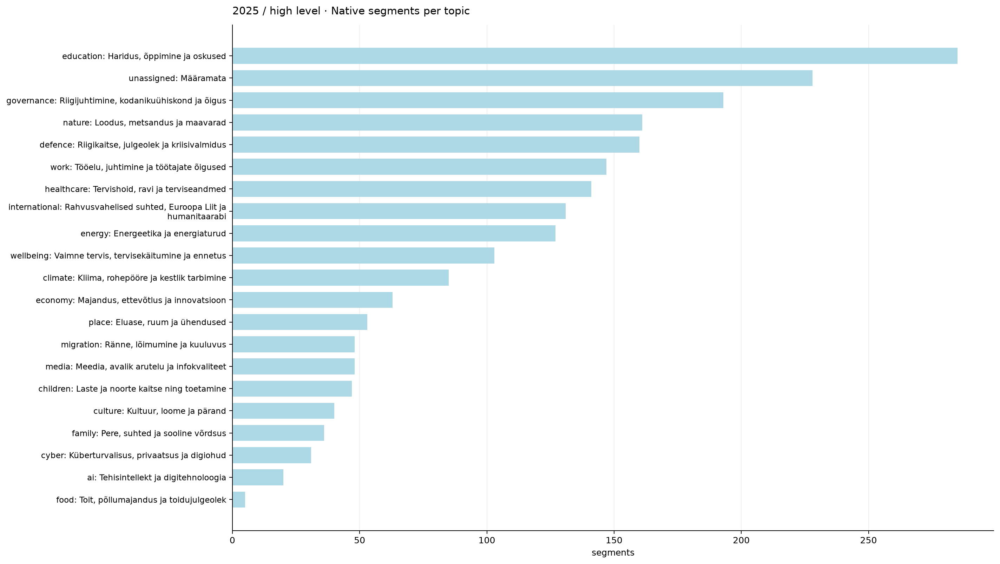

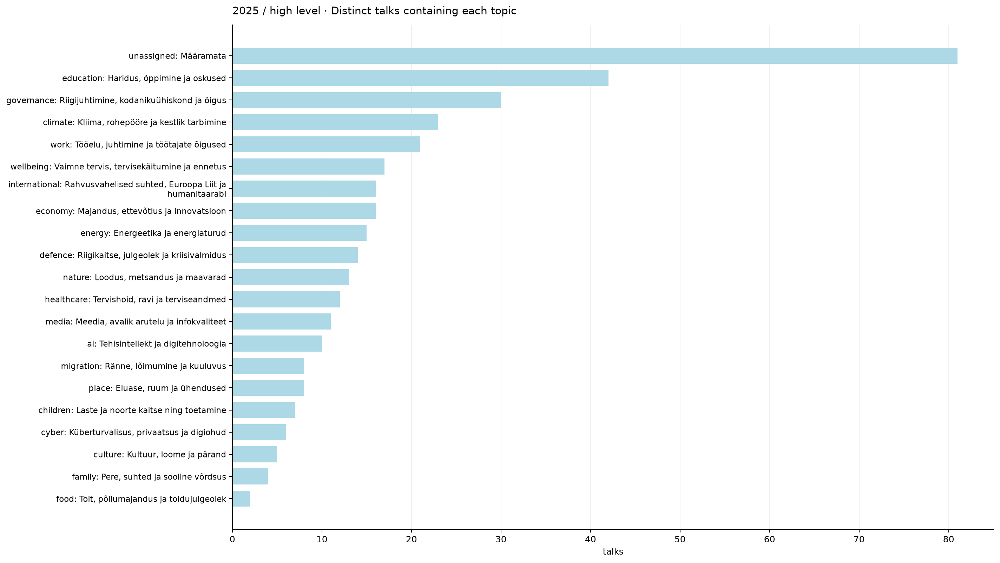

,topic_name,high_level_id,segments,talks,total_minutes,label
analysis_topic,,,,,,
education,"Haridus, õppimine ja oskused",education,285,42,1349.975683,"education: Haridus, õppimine ja oskused"
unassigned,Määramata,unassigned,228,81,706.944483,unassigned: Määramata
governance,"Riigijuhtimine, kodanikuühiskond ja õigus",governance,193,30,932.159700,"governance: Riigijuhtimine, kodanikuühiskond j..."
nature,"Loodus, metsandus ja maavarad",nature,161,13,781.788250,"nature: Loodus, metsandus ja maavarad"
defence,"Riigikaitse, julgeolek ja kriisivalmidus",defence,160,14,797.918000,"defence: Riigikaitse, julgeolek ja kriisivalmidus"
work,"Tööelu, juhtimine ja töötajate õigused",work,147,21,747.567433,"work: Tööelu, juhtimine ja töötajate õigused"
healthcare,"Tervishoid, ravi ja terviseandmed",healthcare,141,12,678.311650,"healthcare: Tervishoid, ravi ja terviseandmed"
international,"Rahvusvahelised suhted, Euroopa Liit ja humani...",international,131,16,624.010733,"international: Rahvusvahelised suhted, Euroopa..."
energy,Energeetika ja energiaturud,energy,127,15,584.623833,energy: Energeetika ja energiaturud


### Topic duration: totals, means and observed 95% HDIs

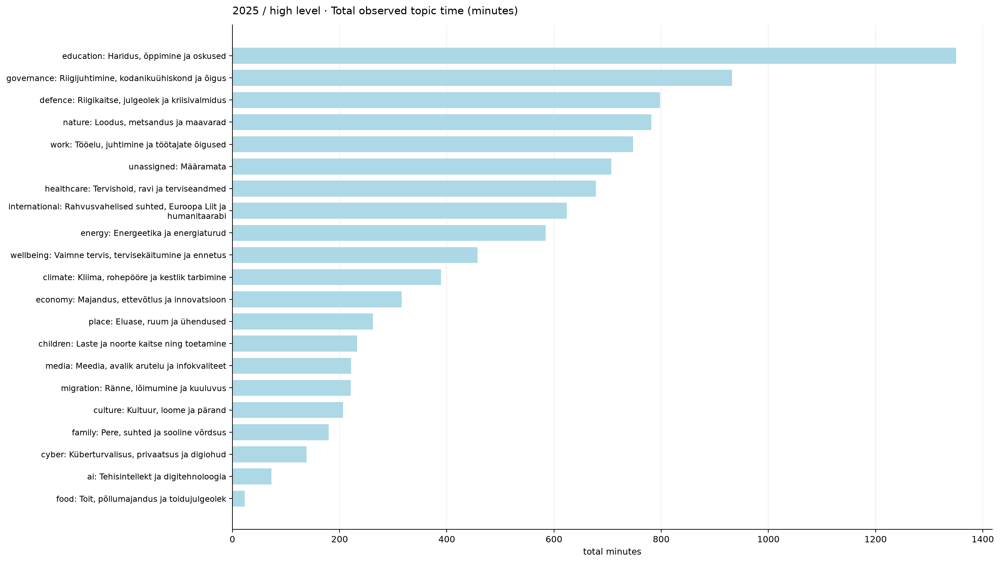

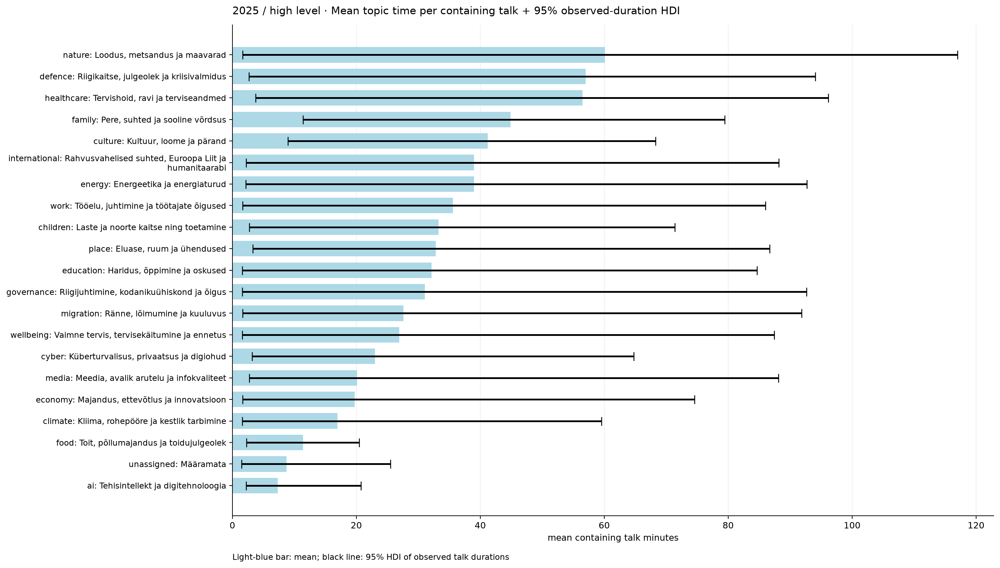

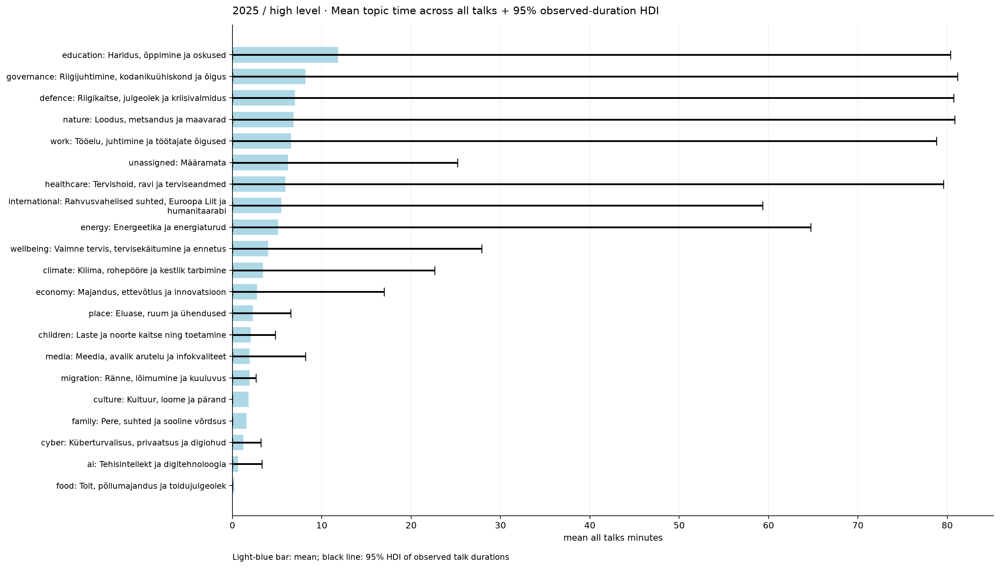

,topic_name,high_level_id,segments,talks,total_minutes,label,mean_all_talks_minutes,mean_containing_talk_minutes,all_hdi_low,all_hdi_high,containing_hdi_low,containing_hdi_high,min_containing_minutes,p25_containing_minutes,median_containing_minutes,p75_containing_minutes,max_containing_minutes
analysis_topic,,,,,,,,,,,,,,,,,
ai,Tehisintellekt ja digitehnoloogia,ai,20,10,72.914000,ai: Tehisintellekt ja digitehnoloogia,0.639596,7.291400,0.0,3.289333,2.211333,20.723333,2.211333,3.177833,4.972000,8.378500,20.723333
children,Laste ja noorte kaitse ning toetamine,children,47,7,232.820967,children: Laste ja noorte kaitse ning toetamine,2.042289,33.260138,0.0,4.800667,2.732000,71.408550,2.732000,8.319458,22.707500,59.667000,71.408550
climate,"Kliima, rohepööre ja kestlik tarbimine",climate,85,23,389.281250,"climate: Kliima, rohepööre ja kestlik tarbimine",3.414748,16.925272,0.0,22.653333,1.624000,59.533367,1.624000,5.440000,7.582000,22.639667,76.858883
culture,"Kultuur, loome ja pärand",culture,40,5,206.143883,"culture: Kultuur, loome ja pärand",1.808280,41.228777,0.0,0.000000,8.970667,68.295550,8.970667,28.234000,41.153333,59.490333,68.295550
cyber,"Küberturvalisus, privaatsus ja digiohud",cyber,31,6,138.109583,"cyber: Küberturvalisus, privaatsus ja digiohud",1.211488,23.018264,0.0,3.190000,3.190000,64.748250,3.190000,4.459667,5.200000,42.968833,64.748250
defence,"Riigikaitse, julgeolek ja kriisivalmidus",defence,160,14,797.918000,"defence: Riigikaitse, julgeolek ja kriisivalmidus",6.999281,56.994143,0.0,80.702500,2.694667,94.053000,2.694667,20.611896,71.920217,85.892488,94.053000
economy,"Majandus, ettevõtlus ja innovatsioon",economy,63,16,315.639917,"economy: Majandus, ettevõtlus ja innovatsioon",2.768771,19.727495,0.0,16.984667,1.630667,74.583000,1.630667,3.229333,10.855333,24.660167,74.583000
education,"Haridus, õppimine ja oskused",education,285,42,1349.975683,"education: Haridus, õppimine ja oskused",11.841892,32.142278,0.0,80.348600,1.570000,84.660617,1.570000,4.142000,15.461942,67.204525,86.147900
energy,Energeetika ja energiaturud,energy,127,15,584.623833,energy: Energeetika ja energiaturud,5.128279,38.974922,0.0,64.735517,2.157333,92.689633,2.157333,9.387667,19.520667,72.528550,92.689633


### Topic co-occurrence tables

,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,name_a,name_b
42,climate,energy,12,23,15,114,3.026316,3.965217,0.461538,0.611898,0.611898,0.596391,0.431928,"Kliima, rohepööre ja kestlik tarbimine",Energeetika ja energiaturud
35,children,wellbeing,5,7,17,114,1.043860,4.789916,0.263158,0.501002,0.501002,0.488226,0.250501,Laste ja noorte kaitse ning toetamine,"Vaimne tervis, tervisekäitumine ja ennetus"
40,climate,economy,8,23,16,114,3.228070,2.478261,0.258065,0.341603,0.341603,0.337624,0.210217,"Kliima, rohepööre ja kestlik tarbimine","Majandus, ettevõtlus ja innovatsioon"
50,climate,nature,7,23,13,114,2.622807,2.668896,0.241379,0.351815,0.351815,0.347386,0.205225,"Kliima, rohepööre ja kestlik tarbimine","Loodus, metsandus ja maavarad"
119,education,migration,7,42,8,114,2.947368,2.375000,0.162791,0.310003,0.310003,0.295787,0.180835,"Haridus, õppimine ja oskused","Ränne, lõimumine ja kuuluvus"
92,defence,international,5,14,16,114,1.964912,2.544643,0.200000,0.298709,0.298709,0.300794,0.149354,"Riigikaitse, julgeolek ja kriisivalmidus","Rahvusvahelised suhted, Euroopa Liit ja humani..."
156,governance,media,6,30,11,114,2.894737,2.072727,0.171429,0.247540,0.247540,0.245160,0.135022,"Riigijuhtimine, kodanikuühiskond ja õigus","Meedia, avalik arutelu ja infokvaliteet"
6,ai,education,7,10,42,114,3.684211,1.900000,0.155556,0.230031,0.230031,0.222515,0.134185,Tehisintellekt ja digitehnoloogia,"Haridus, õppimine ja oskused"
105,economy,international,5,16,16,114,2.245614,2.226562,0.185185,0.256003,0.256003,0.259742,0.128001,"Majandus, ettevõtlus ja innovatsioon","Rahvusvahelised suhted, Euroopa Liit ja humani..."
83,cyber,wellbeing,3,6,17,114,0.894737,3.352941,0.150000,0.332594,0.332594,0.334227,0.124723,"Küberturvalisus, privaatsus ja digiohud","Vaimne tervis, tervisekäitumine ja ennetus"


### Topic co-occurrence heatmap

### Topic–organizer associations and metadata coverage

...

Programme entries with missing organizer fields (other roles are retained separately):


,episode_id,title,programme_stage,programme_curator,programme_support_text
82,2310594914,Õpetaja ajamasinas. Õpetaja missioon ja rollid...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
83,2310594917,Milline koolivõrk suudab kasvatada korraga tar...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
84,2310594920,Mul jäi isegi Tiigrihüpe tegemata.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
85,2310594923,Koolijuht on tippjuht,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
86,2310594926,Mis on Eesti hariduse eesmärk.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
92,2314163825,"Kriise rohkem, raha vähem",19 Välispoliitika,,Välispoliitika aruteluala toetab Eesti Välismi...


,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,topic_name
1424,work,eesti personalijuhtimise ühing pare,9,21,9,108,1.750000,5.142857,0.428571,0.659022,0.659022,0.636188,0.423657,"Tööelu, juhtimine ja töötajate õigused"
1034,international,välisministeerium,5,15,6,108,0.833333,6.000000,0.312500,0.583123,0.583123,0.563044,0.291562,"Rahvusvahelised suhted, Euroopa Liit ja humani..."
640,energy,mtü eesti taastuvenergia koda,3,15,3,108,0.416667,7.200000,0.200000,0.550878,0.550878,0.520449,0.206579,Energeetika ja energiaturud
584,education,telia,5,37,5,108,1.712963,2.918919,0.135135,0.348624,0.348624,0.325758,0.174312,"Haridus, õppimine ja oskused"
180,climate,fridays for future eesti (mtü loodusvõlu),3,23,3,108,0.638889,4.695652,0.130435,0.431597,0.431597,0.402845,0.161849,"Kliima, rohepööre ja kestlik tarbimine"
1398,wellbeing,telia,3,17,5,108,0.787037,3.811765,0.157895,0.373402,0.373402,0.368682,0.140026,"Vaimne tervis, tervisekäitumine ja ennetus"
860,governance,mtü arvamusfestival,3,29,4,108,1.074074,2.793103,0.100000,0.286633,0.286633,0.273401,0.107487,"Riigijuhtimine, kodanikuühiskond ja õigus"
536,education,eesti personalijuhtimise ühing pare,4,37,9,108,3.083333,1.297297,0.095238,0.078973,0.078973,0.082714,0.035099,"Haridus, õppimine ja oskused"


### Export manifest

Saved analysis to C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-topic-analysis\high_level\2025


In [6]:
if "high_level" in RUN_LEVELS and 2025 in RUN_YEARS:
    run_analysis(2025, "high_level")

## 2026: high level charts

## 2026 / high level
105 talks · 1,974 semantic segments. Year-specific plots use only this scope's talks; labels share the original vocabulary.

### Segments and talks per topic

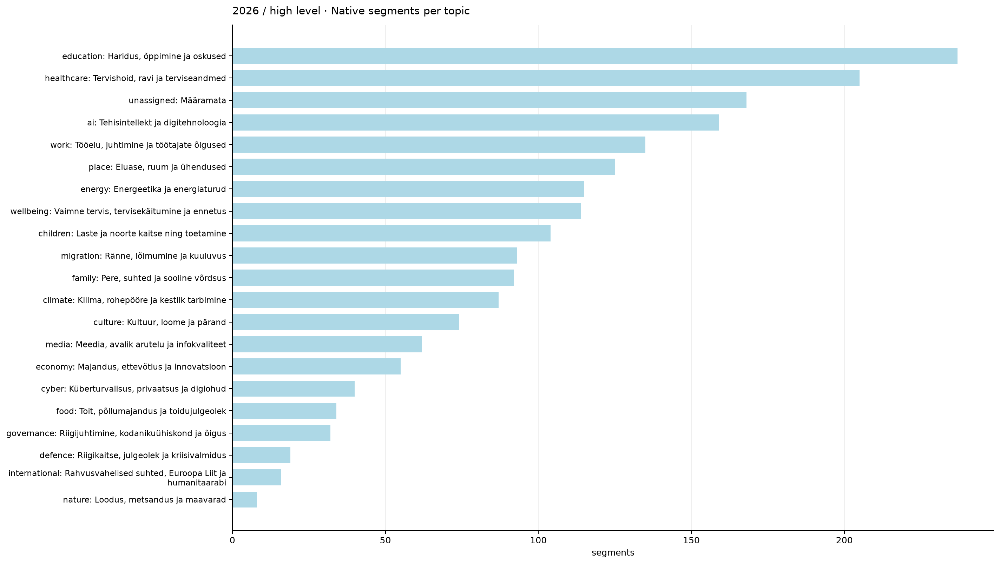

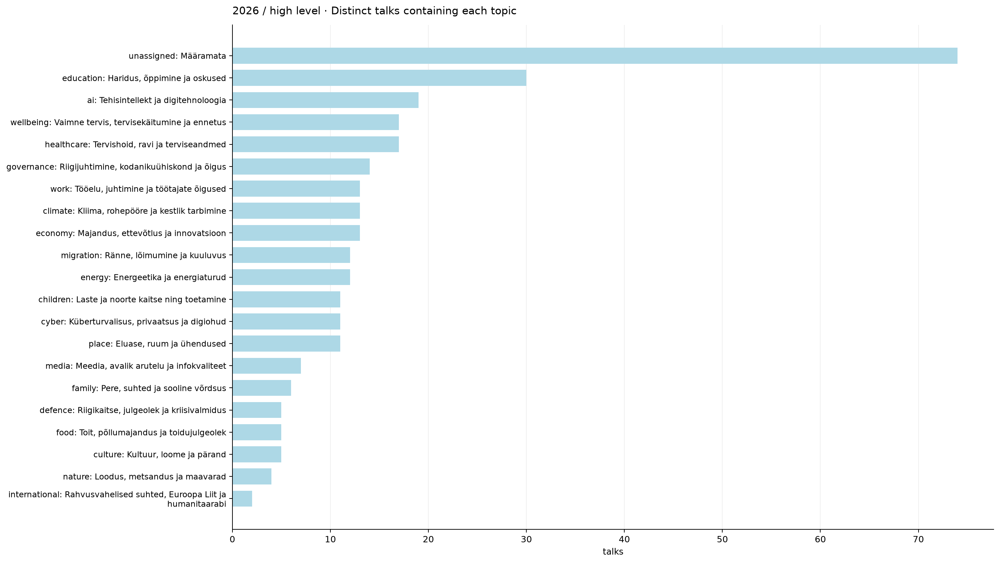

,topic_name,high_level_id,segments,talks,total_minutes,label
analysis_topic,,,,,,
education,"Haridus, õppimine ja oskused",education,237,30,1157.797433,"education: Haridus, õppimine ja oskused"
healthcare,"Tervishoid, ravi ja terviseandmed",healthcare,205,17,981.737667,"healthcare: Tervishoid, ravi ja terviseandmed"
unassigned,Määramata,unassigned,168,74,501.412150,unassigned: Määramata
ai,Tehisintellekt ja digitehnoloogia,ai,159,19,744.479000,ai: Tehisintellekt ja digitehnoloogia
work,"Tööelu, juhtimine ja töötajate õigused",work,135,13,636.923367,"work: Tööelu, juhtimine ja töötajate õigused"
place,"Eluase, ruum ja ühendused",place,125,11,555.433783,"place: Eluase, ruum ja ühendused"
energy,Energeetika ja energiaturud,energy,115,12,571.085333,energy: Energeetika ja energiaturud
wellbeing,"Vaimne tervis, tervisekäitumine ja ennetus",wellbeing,114,17,535.647600,"wellbeing: Vaimne tervis, tervisekäitumine ja ..."
children,Laste ja noorte kaitse ning toetamine,children,104,11,462.229300,children: Laste ja noorte kaitse ning toetamine


### Topic duration: totals, means and observed 95% HDIs

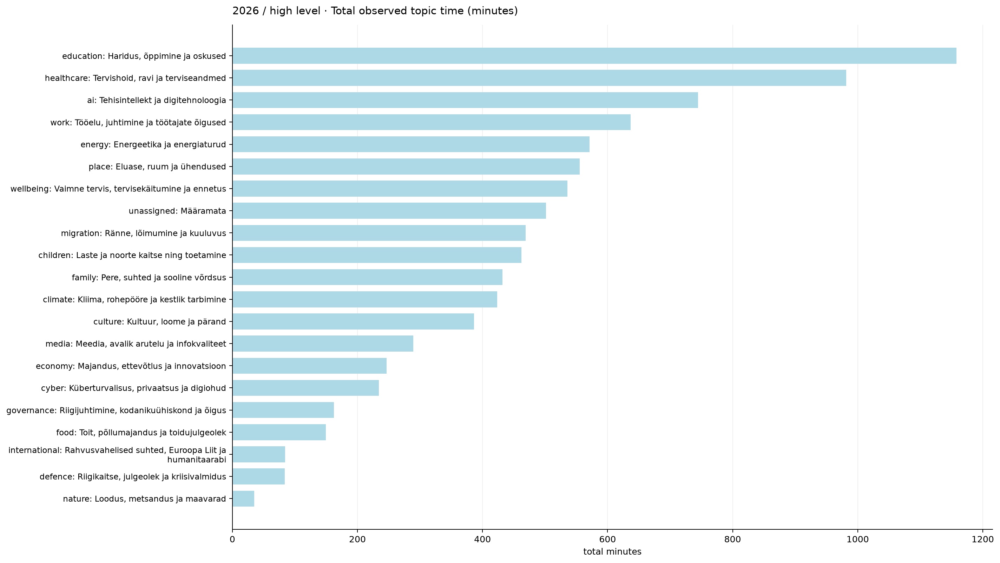

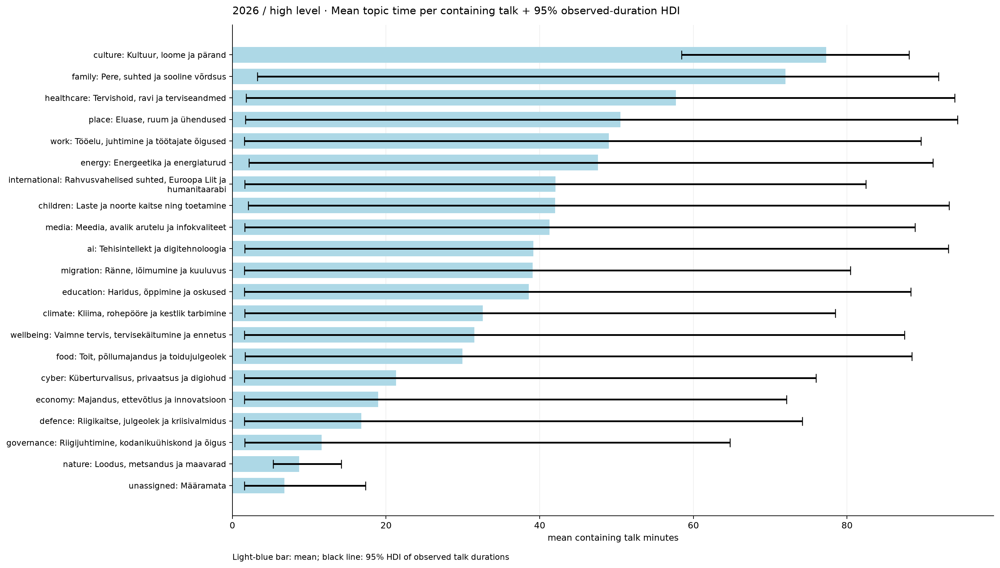

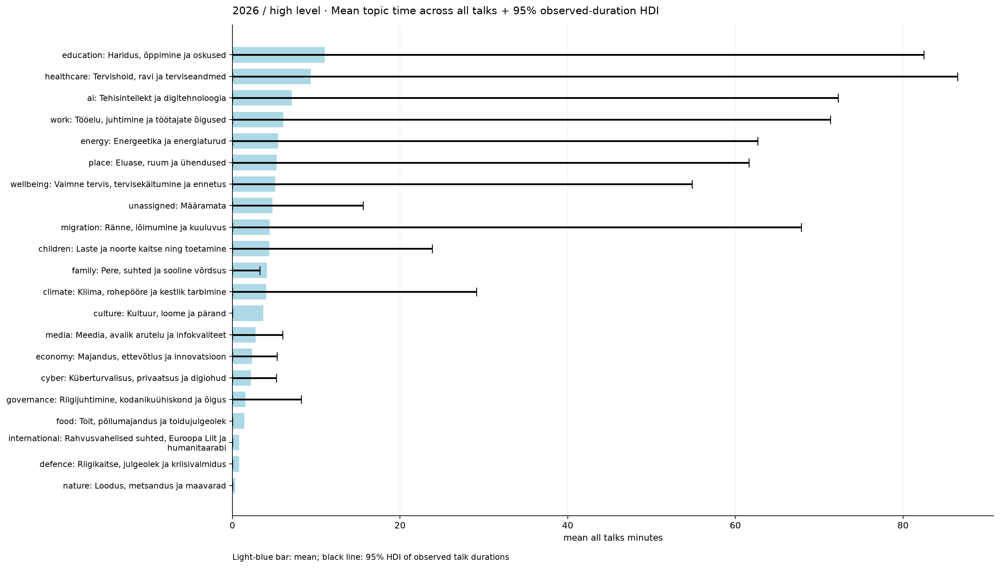

,topic_name,high_level_id,segments,talks,total_minutes,label,mean_all_talks_minutes,mean_containing_talk_minutes,all_hdi_low,all_hdi_high,containing_hdi_low,containing_hdi_high,min_containing_minutes,p25_containing_minutes,median_containing_minutes,p75_containing_minutes,max_containing_minutes
analysis_topic,,,,,,,,,,,,,,,,,
ai,Tehisintellekt ja digitehnoloogia,ai,159,19,744.479000,ai: Tehisintellekt ja digitehnoloogia,7.090276,39.183105,0.0,72.280000,1.613333,93.206700,1.613333,6.520667,16.553333,72.602250,93.206700
children,Laste ja noorte kaitse ning toetamine,children,104,11,462.229300,children: Laste ja noorte kaitse ning toetamine,4.402184,42.020845,0.0,23.832067,2.074000,93.306233,2.074000,5.369667,23.832067,77.990775,93.306233
climate,"Kliima, rohepööre ja kestlik tarbimine",climate,87,13,423.415283,"climate: Kliima, rohepööre ja kestlik tarbimine",4.032527,32.570406,0.0,29.123600,1.621333,78.464000,1.621333,7.192000,22.559333,59.962617,78.464000
culture,"Kultuur, loome ja pärand",culture,74,5,386.403267,"culture: Kultuur, loome ja pärand",3.680031,77.280653,0.0,0.000000,58.453333,88.078450,58.453333,78.752000,79.759033,81.360450,88.078450
cyber,"Küberturvalisus, privaatsus ja digiohud",cyber,40,11,234.233033,"cyber: Küberturvalisus, privaatsus ja digiohud",2.230791,21.293912,0.0,5.252000,1.562667,75.982717,1.562667,2.636667,5.252000,35.038408,75.982717
defence,"Riigikaitse, julgeolek ja kriisivalmidus",defence,19,5,83.915383,"defence: Riigikaitse, julgeolek ja kriisivalmidus",0.799194,16.783077,0.0,0.000000,1.570667,74.174717,1.570667,1.617333,3.164000,3.388667,74.174717
economy,"Majandus, ettevõtlus ja innovatsioon",economy,55,13,246.574483,"economy: Majandus, ettevõtlus ja innovatsioon",2.348328,18.967268,0.0,5.336000,1.562000,72.124667,1.562000,1.636667,3.440000,31.042667,72.124667
education,"Haridus, õppimine ja oskused",education,237,30,1157.797433,"education: Haridus, õppimine ja oskused",11.026642,38.593248,0.0,82.472833,1.560000,88.311550,1.560000,5.131833,18.007475,73.790367,95.653567
energy,Energeetika ja energiaturud,energy,115,12,571.085333,energy: Energeetika ja energiaturud,5.438908,47.590444,0.0,62.650783,2.170667,91.198733,2.170667,14.001000,56.719150,74.937971,91.198733


### Topic co-occurrence tables

,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,name_a,name_b
42,climate,energy,8,13,12,105,1.485714,5.384615,0.470588,0.653926,0.653926,0.635231,0.402416,"Kliima, rohepööre ja kestlik tarbimine",Energeetika ja energiaturud
3,ai,cyber,7,19,11,105,1.990476,3.516746,0.304348,0.464370,0.464370,0.454148,0.270882,Tehisintellekt ja digitehnoloogia,"Küberturvalisus, privaatsus ja digiohud"
131,energy,nature,3,12,4,105,0.457143,6.562500,0.230769,0.529167,0.529167,0.512038,0.198437,Energeetika ja energiaturud,"Loodus, metsandus ja maavarad"
50,climate,nature,3,13,4,105,0.495238,6.057692,0.214286,0.506653,0.506653,0.490370,0.189995,"Kliima, rohepööre ja kestlik tarbimine","Loodus, metsandus ja maavarad"
126,energy,governance,5,12,14,105,1.600000,3.125000,0.238095,0.374257,0.374257,0.372152,0.187129,Energeetika ja energiaturud,"Riigijuhtimine, kodanikuühiskond ja õigus"
44,climate,food,3,13,5,105,0.619048,4.846154,0.200000,0.443891,0.443891,0.437060,0.166459,"Kliima, rohepööre ja kestlik tarbimine","Toit, põllumajandus ja toidujulgeolek"
167,healthcare,wellbeing,6,17,17,105,2.752381,2.179931,0.214286,0.272271,0.272271,0.272717,0.148511,"Tervishoid, ravi ja terviseandmed","Vaimne tervis, tervisekäitumine ja ennetus"
159,governance,place,4,14,11,105,1.466667,2.727273,0.190476,0.307039,0.307039,0.310516,0.136462,"Riigijuhtimine, kodanikuühiskond ja õigus","Eluase, ruum ja ühendused"
5,ai,economy,5,19,13,105,2.352381,2.125506,0.185185,0.247661,0.247661,0.250258,0.123831,Tehisintellekt ja digitehnoloogia,"Majandus, ettevõtlus ja innovatsioon"
40,climate,economy,4,13,13,105,1.609524,2.485207,0.181818,0.278595,0.278595,0.283642,0.123820,"Kliima, rohepööre ja kestlik tarbimine","Majandus, ettevõtlus ja innovatsioon"


### Topic co-occurrence heatmap

### Topic–organizer associations and metadata coverage

...

Programme entries with missing organizer fields (other roles are retained separately):


,episode_id,title,programme_stage,programme_curator,programme_support_text


,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,topic_name
7,ai,eesti e-residentsuse programm,8,19,8,105,1.447619,5.526316,0.421053,0.664016,0.664016,0.639593,0.408625,Tehisintellekt ja digitehnoloogia
1386,work,eesti personalijuhtimise ühing pare ja tööinsp...,7,13,9,105,1.114286,6.282051,0.466667,0.678605,0.678605,0.656937,0.395853,"Tööelu, juhtimine ja töötajate õigused"
888,healthcare,eesti vähitõrje võrgustik (estcan),5,17,5,105,0.809524,6.176471,0.294118,0.598040,0.598040,0.571226,0.299020,"Tervishoid, ravi ja terviseandmed"
624,energy,mtü eesti taastuvenergia koda,3,12,4,105,0.457143,6.562500,0.230769,0.529167,0.529167,0.512038,0.198437,Energeetika ja energiaturud
192,climate,mtü eesti taastuvenergia koda,3,13,4,105,0.495238,6.057692,0.214286,0.506653,0.506653,0.490370,0.189995,"Kliima, rohepööre ja kestlik tarbimine"
666,family,eesti personalijuhtimise ühing pare ja tööinsp...,3,6,9,105,0.514286,5.833333,0.250000,0.496038,0.496038,0.490370,0.186014,"Pere, suhted ja sooline võrdsus"
295,cyber,eesti e-residentsuse programm,3,11,8,105,0.838095,3.579545,0.187500,0.358681,0.358681,0.363578,0.134505,"Küberturvalisus, privaatsus ja digiohud"
547,education,lasteklubi väike päike,3,30,3,105,0.857143,3.500000,0.100000,0.352360,0.352360,0.323184,0.132135,"Haridus, õppimine ja oskused"
439,economy,eesti e-residentsuse programm,3,13,8,105,0.990476,3.028846,0.166667,0.311694,0.311694,0.318506,0.116885,"Majandus, ettevõtlus ja innovatsioon"
1314,wellbeing,eesti personalijuhtimise ühing pare ja tööinsp...,3,17,9,105,1.457143,2.058824,0.130435,0.203112,0.203112,0.214217,0.076167,"Vaimne tervis, tervisekäitumine ja ennetus"


### Export manifest

Saved analysis to C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-topic-analysis\high_level\2026


In [7]:
if "high_level" in RUN_LEVELS and 2026 in RUN_YEARS:
    run_analysis(2026, "high_level")

## Combined: detailed charts

## All years / detailed
219 talks · 4,126 semantic segments. Year-specific plots use only this scope's talks; labels share the original vocabulary.

### Segments and talks per topic

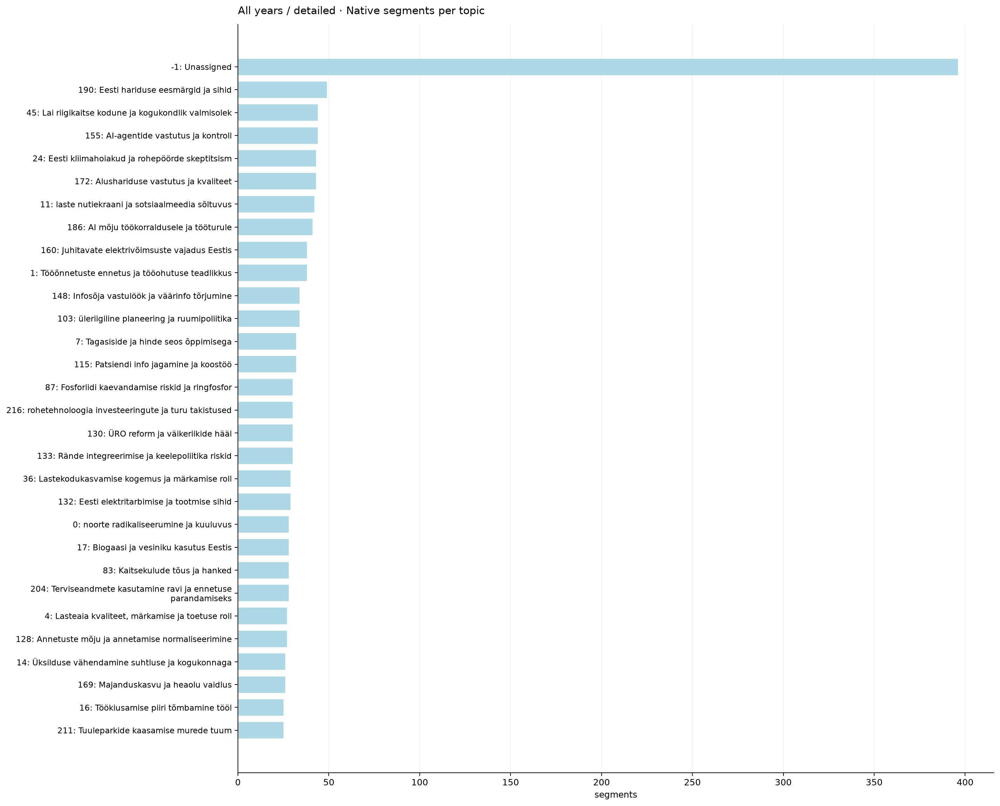

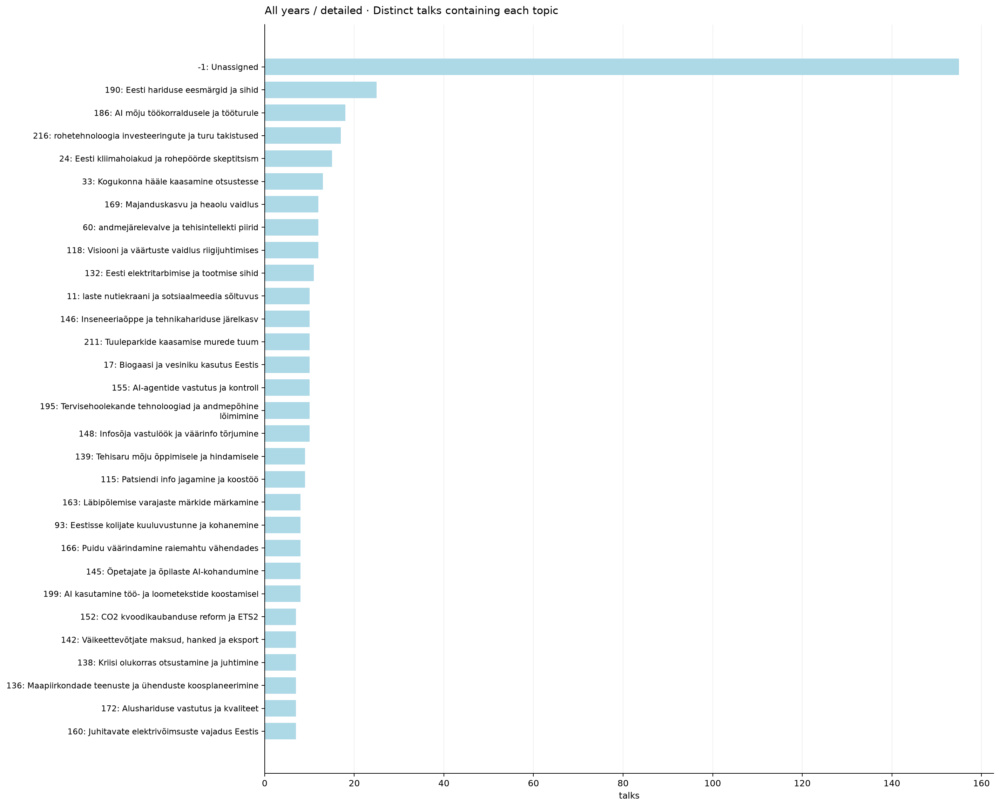

,topic_name,high_level_id,segments,talks,total_minutes,label
analysis_topic,,,,,,
-1,Unassigned,unassigned,396,155,1208.356633,-1: Unassigned
190,Eesti hariduse eesmärgid ja sihid,education,49,25,210.273083,190: Eesti hariduse eesmärgid ja sihid
155,AI-agentide vastutus ja kontroll,ai,44,10,191.878667,155: AI-agentide vastutus ja kontroll
45,Lai riigikaitse kodune ja kogukondlik valmisolek,defence,44,7,209.536483,45: Lai riigikaitse kodune ja kogukondlik valm...
172,Alushariduse vastutus ja kvaliteet,education,43,7,207.084867,172: Alushariduse vastutus ja kvaliteet
...,...,...,...,...,...,...
232,Noorte vanglast saatmine pärast rasket vägivalda,children,3,1,16.011333,232: Noorte vanglast saatmine pärast rasket vä...
69,Kohtla-Järve tuhamägede väetisetehas,nature,3,2,11.496000,69: Kohtla-Järve tuhamägede väetisetehas
228,ÜRO Julgeolekunõukogu reformiummik,international,2,1,9.858667,228: ÜRO Julgeolekunõukogu reformiummik


### Topic duration: totals, means and observed 95% HDIs

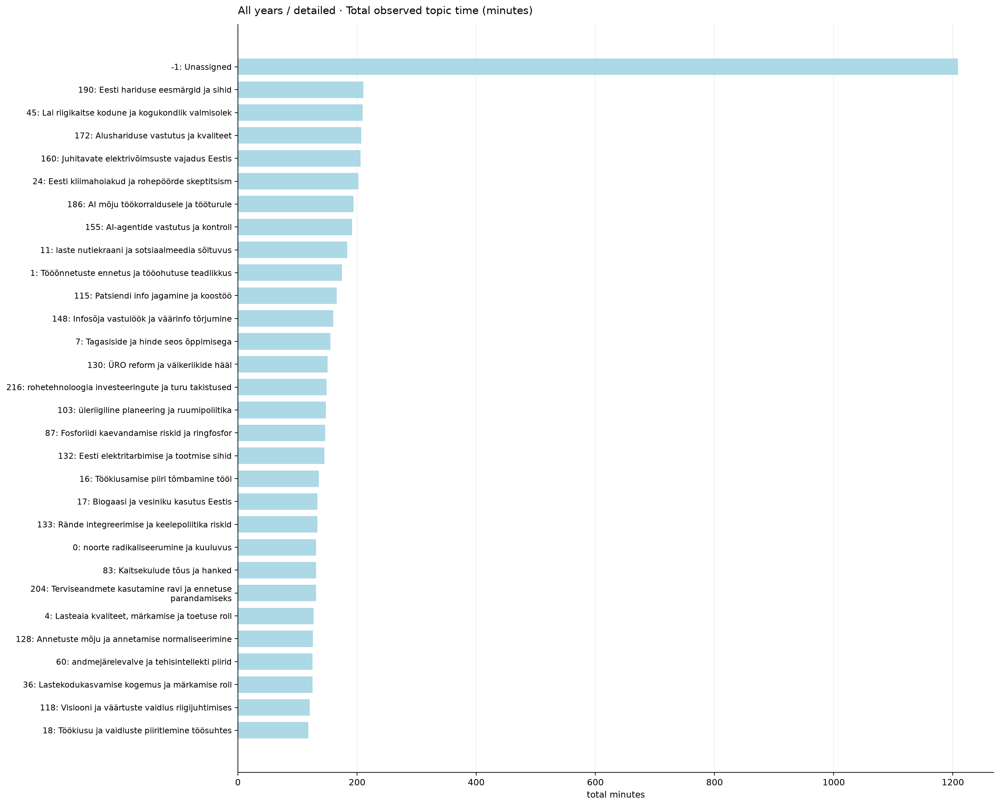

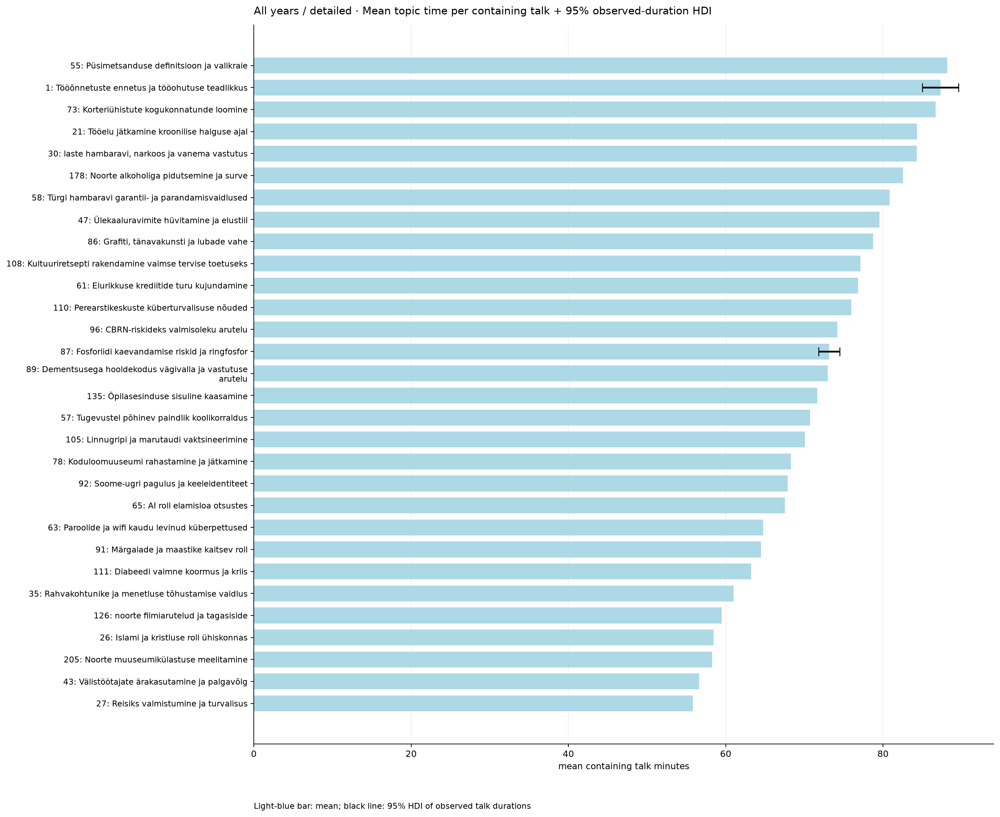

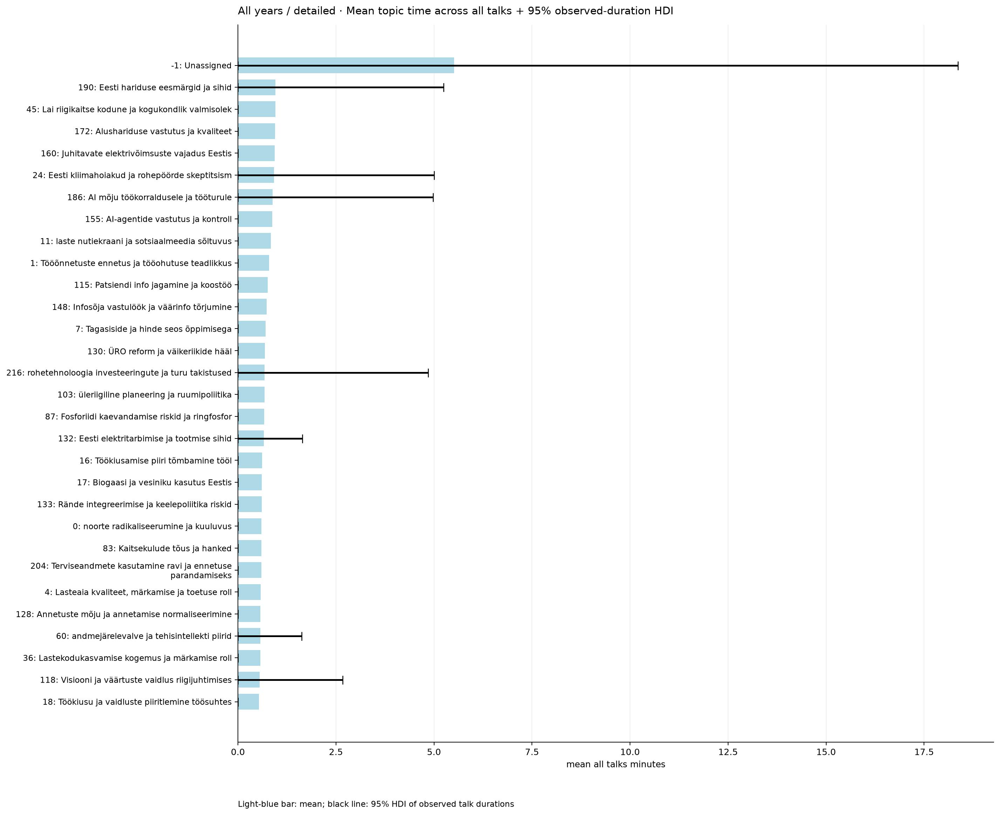

,topic_name,high_level_id,segments,talks,total_minutes,label,mean_all_talks_minutes,mean_containing_talk_minutes,all_hdi_low,all_hdi_high,containing_hdi_low,containing_hdi_high,min_containing_minutes,p25_containing_minutes,median_containing_minutes,p75_containing_minutes,max_containing_minutes
analysis_topic,,,,,,,,,,,,,,,,,
-1,Unassigned,unassigned,396,155,1208.356633,-1: Unassigned,5.517610,7.795849,0.0,18.36,1.510983,22.481800,1.510983,3.246083,5.472667,9.208000,65.249967
0,noorte radikaliseerumine ja kuuluvus,children,28,4,131.433550,0: noorte radikaliseerumine ja kuuluvus,0.600153,32.858387,0.0,0.00,2.074000,75.062217,2.074000,7.748000,27.148667,52.259054,75.062217
1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,38,2,174.633317,1: Tööõnnetuste ennetus ja tööohutuse teadlikkus,0.797412,87.316658,0.0,0.00,85.021350,89.611967,85.021350,86.169004,87.316658,88.464313,89.611967
10,Nõusolek paarisuhtes ja läheduses,family,20,2,100.182283,10: Nõusolek paarisuhtes ja läheduses,0.457453,50.091142,0.0,0.00,15.704667,84.477617,15.704667,32.897904,50.091142,67.284379,84.477617
100,naiste ajateenistuse laiendamine riigikaitses,defence,16,3,81.801917,100: naiste ajateenistuse laiendamine riigikai...,0.373525,27.267306,0.0,0.00,5.165417,68.453167,5.165417,6.674375,8.183333,38.318250,68.453167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Veebis lastega suhtlemise seksuaalriskid,children,24,4,99.542233,95: Veebis lastega suhtlemise seksuaalriskid,0.454531,24.885558,0.0,0.00,1.591333,83.271567,1.591333,4.478333,7.339667,27.746892,83.271567
96,CBRN-riskideks valmisoleku arutelu,defence,15,1,74.174717,96: CBRN-riskideks valmisoleku arutelu,0.338697,74.174717,0.0,0.00,NaN,NaN,74.174717,74.174717,74.174717,74.174717,74.174717
97,Armeenia ja humanitaarabi rahastuse kärped,international,6,1,36.576667,97: Armeenia ja humanitaarabi rahastuse kärped,0.167017,36.576667,0.0,0.00,NaN,NaN,36.576667,36.576667,36.576667,36.576667,36.576667


### Topic co-occurrence tables

,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,name_a,name_b
8267,132,17,7,11,10,219,0.502283,13.936364,0.500000,0.765140,0.765140,0.747878,0.446332,Eesti elektritarbimise ja tootmise sihid,Biogaasi ja vesiniku kasutus Eestis
8257,132,160,6,11,7,219,0.351598,17.064935,0.500000,0.788652,0.788652,0.767255,0.430174,Eesti elektritarbimise ja tootmise sihid,Juhitavate elektrivõimsuste vajadus Eestis
13723,16,18,4,4,5,219,0.091324,43.800000,0.800000,0.944253,0.944253,0.899067,0.419668,Töökiusamise piiri tõmbamine tööl,Töökiusu ja vaidluste piiritlemine töösuhtes
10567,143,182,4,5,5,219,0.114155,35.040000,0.666667,0.888506,0.888506,0.852247,0.394891,Terviseidu turuletoomise rahastus ja regulatsioon,terviseandmete kasutus ja eetikakomitee loa ta...
21761,211,24,7,10,15,219,0.684932,10.220000,0.388889,0.675062,0.675062,0.662846,0.393786,Tuuleparkide kaasamise murede tuum,Eesti kliimahoiakud ja rohepöörde skeptitsism
19484,195,204,5,10,6,219,0.273973,18.250000,0.454545,0.768372,0.768372,0.747034,0.384186,Tervisehoolekande tehnoloogiad ja andmepõhine ...,Terviseandmete kasutamine ravi ja ennetuse par...
13939,160,224,4,7,4,219,0.127854,31.285714,0.571429,0.860193,0.860193,0.825190,0.382308,Juhitavate elektrivõimsuste vajadus Eestis,Sagedusreservi hange ja liitumistingimused
13938,160,223,4,7,4,219,0.127854,31.285714,0.571429,0.860193,0.860193,0.825190,0.382308,Juhitavate elektrivõimsuste vajadus Eestis,Eleringi vähempakkumised uute elektrivõimsuste...
17601,182,204,4,5,6,219,0.136986,29.200000,0.571429,0.842957,0.842957,0.812661,0.374648,terviseandmete kasutus ja eetikakomitee loa ta...,Terviseandmete kasutamine ravi ja ennetuse par...
15317,168,90,4,6,5,219,0.136986,29.200000,0.571429,0.842957,0.842957,0.812661,0.374648,Paindlik tööaeg ja kokkulepitud piirid,kaugtöö ja töövälise aja piirid


### Topic co-occurrence heatmap

### Topic–organizer associations and metadata coverage

...

Programme entries with missing organizer fields (other roles are retained separately):


,episode_id,title,programme_stage,programme_curator,programme_support_text
82,2310594914,Õpetaja ajamasinas. Õpetaja missioon ja rollid...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
83,2310594917,Milline koolivõrk suudab kasvatada korraga tar...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
84,2310594920,Mul jäi isegi Tiigrihüpe tegemata.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
85,2310594923,Koolijuht on tippjuht,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
86,2310594926,Mis on Eesti hariduse eesmärk.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
92,2314163825,"Kriise rohkem, raha vähem",19 Välispoliitika,,Välispoliitika aruteluala toetab Eesti Välismi...


,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,topic_name
15052,2,eesti vähitõrje võrgustik (estcan),4,5,5,213,0.117371,34.080000,0.666667,0.887726,0.887726,0.851195,0.394545,Vähiravi patsiendikesksus ja palliatiivne tugi
10673,17,mtü eesti taastuvenergia koda,5,10,7,213,0.328638,15.214286,0.416667,0.725571,0.725571,0.708709,0.362785,Biogaasi ja vesiniku kasutus Eestis
9333,160,mtü eesti taastuvenergia koda,4,7,7,213,0.230047,17.387755,0.400000,0.718432,0.718432,0.702390,0.319303,Juhitavate elektrivõimsuste vajadus Eestis
11066,172,lasteklubi väike päike,3,7,3,213,0.098592,30.428571,0.428571,0.801229,0.801229,0.766819,0.300461,Alushariduse vastutus ja kvaliteet
25740,6,eesti e-residentsuse programm,3,3,8,213,0.112676,26.625000,0.375000,0.769903,0.769903,0.738216,0.288714,AI-agentide volitamine isikukoodi kaudu
10977,171,telia,3,5,5,213,0.117371,25.560000,0.428571,0.760327,0.760327,0.738216,0.285122,Tehisintellekti kasutus kooliõppes
18713,223,mtü eesti taastuvenergia koda,3,4,7,213,0.131455,22.821429,0.375000,0.733740,0.733740,0.712630,0.275153,Eleringi vähempakkumised uute elektrivõimsuste...
15808,203,välisministeerium,3,5,6,213,0.140845,21.300000,0.375000,0.717555,0.717555,0.700782,0.269083,Hiina mõju USA kaubandus- ja tarneahelatele
5179,132,mtü eesti taastuvenergia koda,4,11,7,213,0.361502,11.064935,0.285714,0.604725,0.604725,0.597525,0.268767,Eesti elektritarbimise ja tootmise sihid
8454,155,eesti e-residentsuse programm,4,10,8,213,0.375587,10.650000,0.285714,0.595110,0.595110,0.589567,0.264493,AI-agentide vastutus ja kontroll


### Export manifest

Saved analysis to C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-topic-analysis\detailed


In [8]:
if "detailed" in RUN_LEVELS and None in RUN_YEARS:
    run_analysis(None, "detailed")

## 2025: detailed charts

## 2025 / detailed
114 talks · 2,152 semantic segments. Year-specific plots use only this scope's talks; labels share the original vocabulary.

### Segments and talks per topic

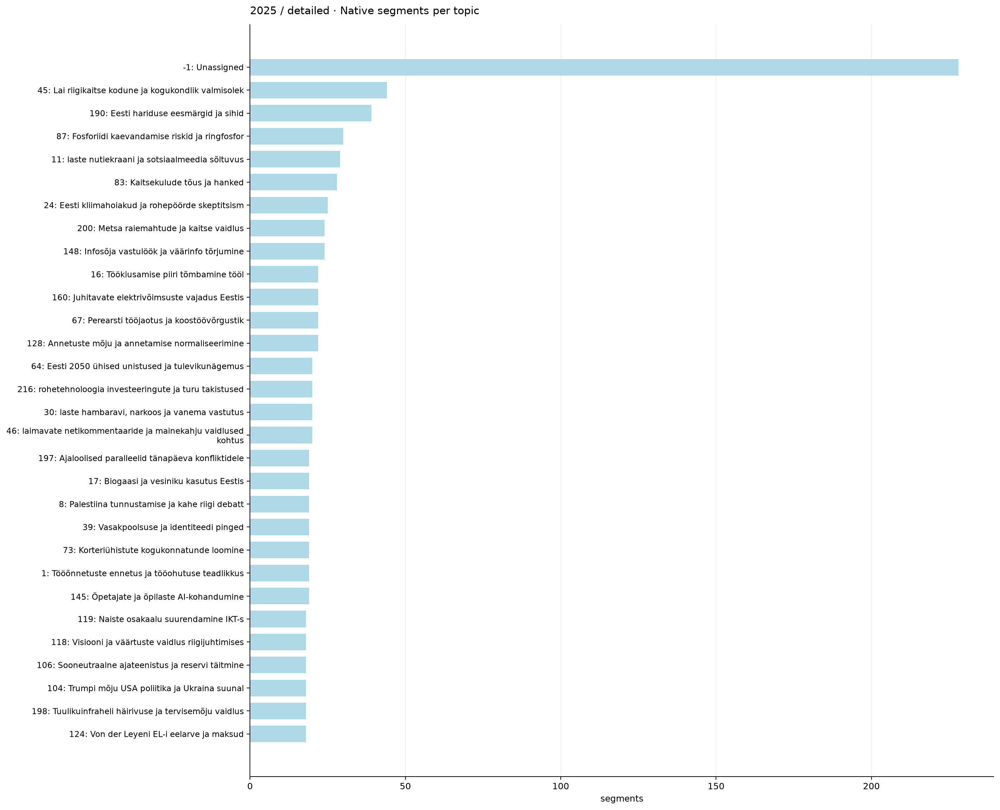

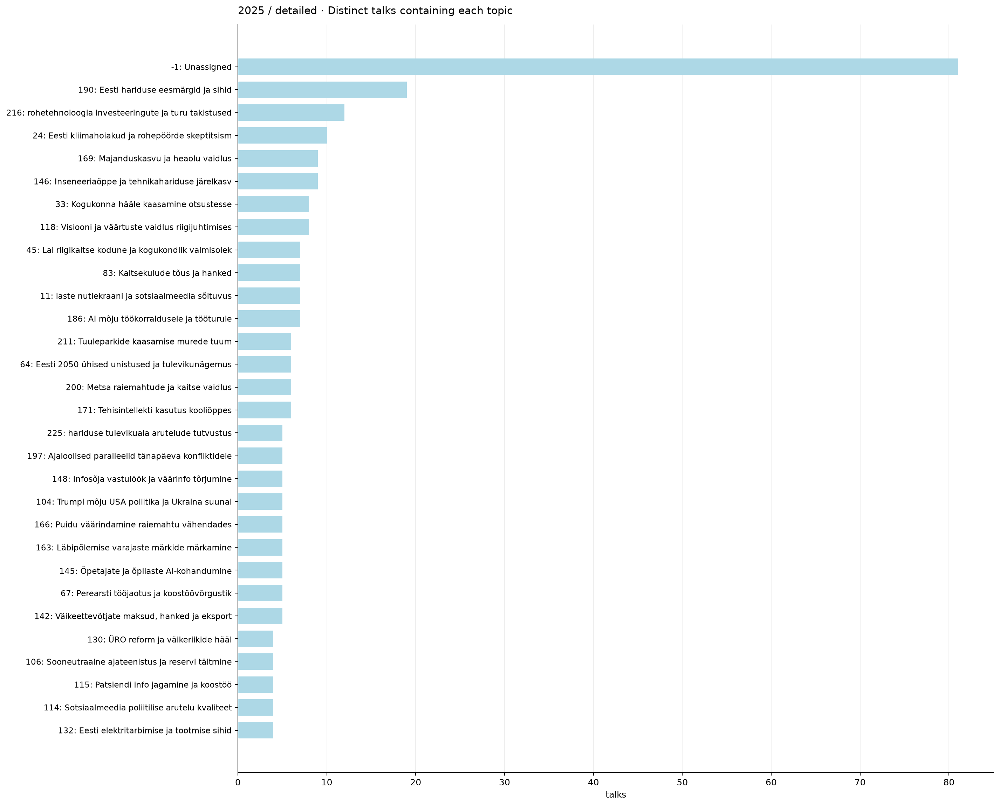

,topic_name,high_level_id,segments,talks,total_minutes,label
analysis_topic,,,,,,
-1,Unassigned,unassigned,228,81,706.944483,-1: Unassigned
45,Lai riigikaitse kodune ja kogukondlik valmisolek,defence,44,7,209.536483,45: Lai riigikaitse kodune ja kogukondlik valm...
190,Eesti hariduse eesmärgid ja sihid,education,39,19,178.508417,190: Eesti hariduse eesmärgid ja sihid
87,Fosforiidi kaevandamise riskid ja ringfosfor,nature,30,2,146.341433,87: Fosforiidi kaevandamise riskid ja ringfosfor
11,laste nutiekraani ja sotsiaalmeedia sõltuvus,wellbeing,29,7,125.046133,11: laste nutiekraani ja sotsiaalmeedia sõltuvus
...,...,...,...,...,...,...
4,"Lasteaia kvaliteet, märkamise ja toetuse roll",education,1,1,2.704667,"4: Lasteaia kvaliteet, märkamise ja toetuse roll"
56,Noorte koduostu ja üüri kättesaadavus,place,1,1,4.983333,56: Noorte koduostu ja üüri kättesaadavus
42,Idapiirialade eraldi regionaalpoliitika,place,1,1,3.308667,42: Idapiirialade eraldi regionaalpoliitika


### Topic duration: totals, means and observed 95% HDIs

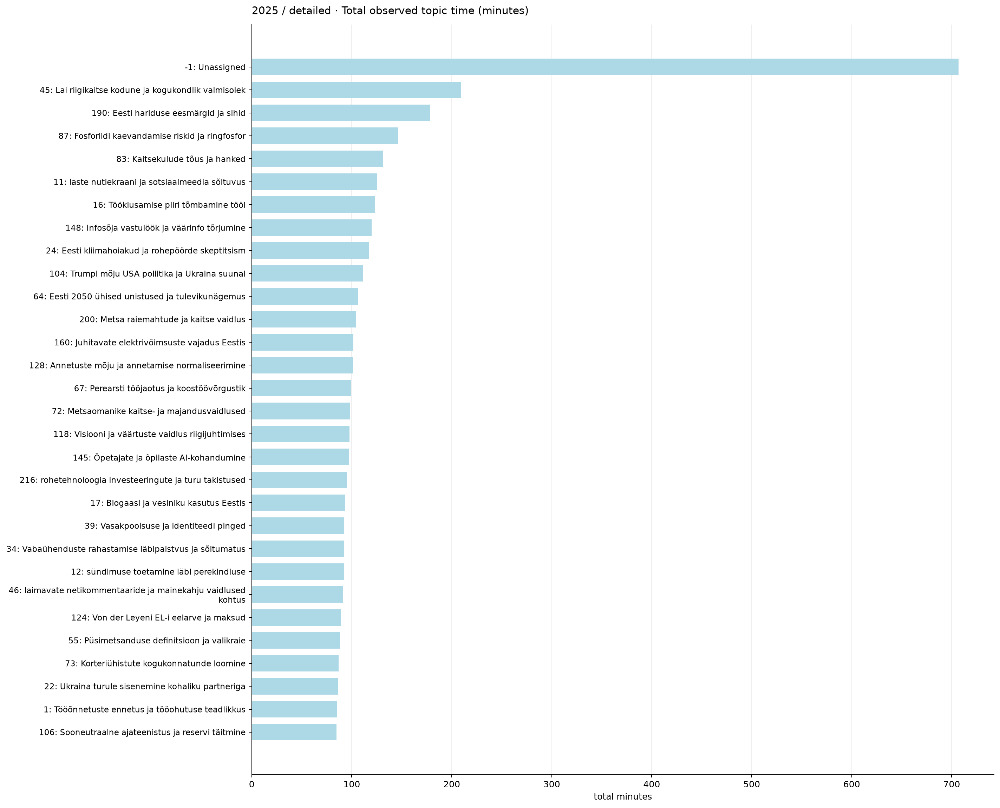

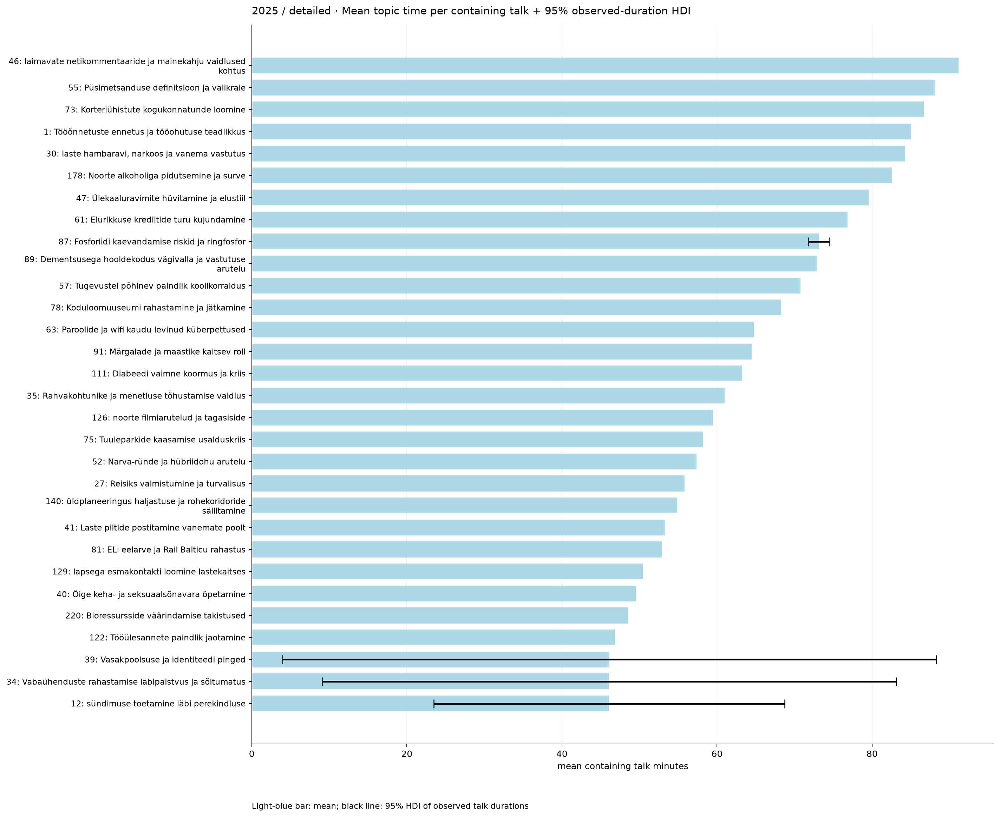

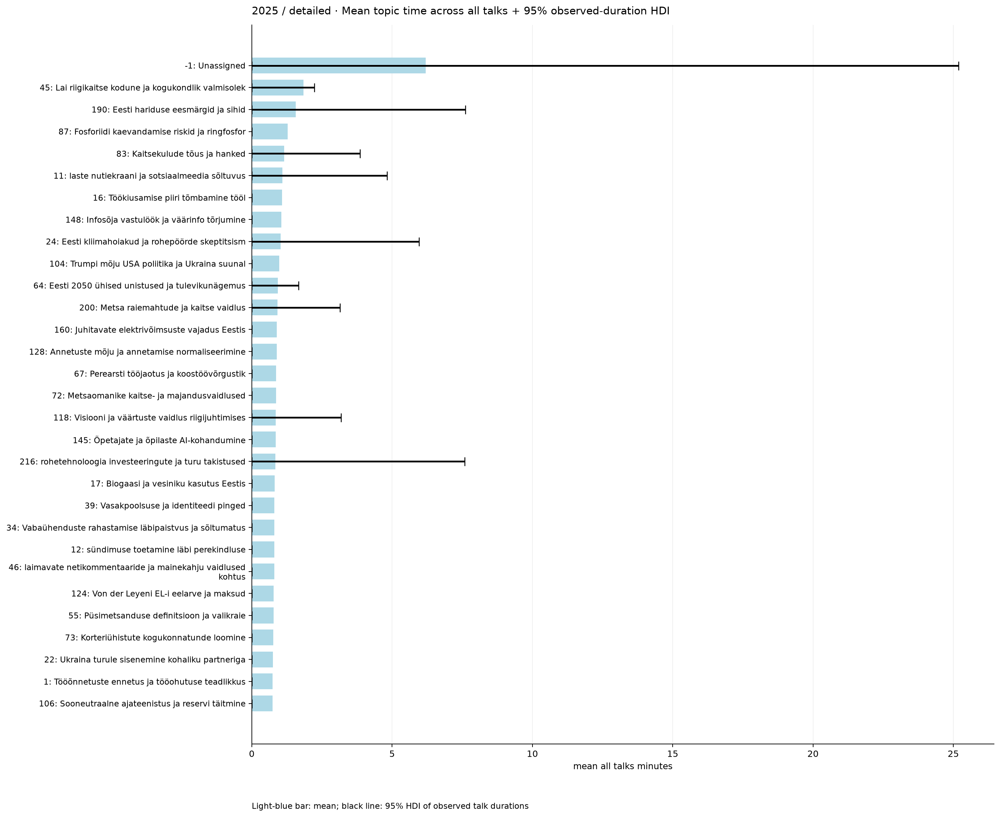

,topic_name,high_level_id,segments,talks,total_minutes,label,mean_all_talks_minutes,mean_containing_talk_minutes,all_hdi_low,all_hdi_high,containing_hdi_low,containing_hdi_high,min_containing_minutes,p25_containing_minutes,median_containing_minutes,p75_containing_minutes,max_containing_minutes
analysis_topic,,,,,,,,,,,,,,,,,
-1,Unassigned,unassigned,228,81,706.944483,-1: Unassigned,6.201267,8.727710,0.0,25.19,1.510983,25.530000,1.510983,3.218667,5.883333,10.196667,65.249967
0,noorte radikaliseerumine ja kuuluvus,children,8,1,44.658000,0: noorte radikaliseerumine ja kuuluvus,0.391737,44.658000,0.0,0.00,NaN,NaN,44.658000,44.658000,44.658000,44.658000,44.658000
1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,19,1,85.021350,1: Tööõnnetuste ennetus ja tööohutuse teadlikkus,0.745801,85.021350,0.0,0.00,NaN,NaN,85.021350,85.021350,85.021350,85.021350,85.021350
10,Nõusolek paarisuhtes ja läheduses,family,3,1,15.704667,10: Nõusolek paarisuhtes ja läheduses,0.137760,15.704667,0.0,0.00,NaN,NaN,15.704667,15.704667,15.704667,15.704667,15.704667
100,naiste ajateenistuse laiendamine riigikaitses,defence,16,3,81.801917,100: naiste ajateenistuse laiendamine riigikai...,0.717561,27.267306,0.0,0.00,5.165417,68.453167,5.165417,6.674375,8.183333,38.318250,68.453167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,Eestisse kolijate kuuluvustunne ja kohanemine,migration,6,2,31.436000,93: Eestisse kolijate kuuluvustunne ja kohanemine,0.275754,15.718000,0.0,0.00,4.336000,27.100000,4.336000,10.027000,15.718000,21.409000,27.100000
94,planeeringute ja kaasamise venimine,place,3,1,14.126000,94: planeeringute ja kaasamise venimine,0.123912,14.126000,0.0,0.00,NaN,NaN,14.126000,14.126000,14.126000,14.126000,14.126000
95,Veebis lastega suhtlemise seksuaalriskid,children,3,3,16.270667,95: Veebis lastega suhtlemise seksuaalriskid,0.142725,5.423556,0.0,0.00,1.591333,9.238667,1.591333,3.516000,5.440667,7.339667,9.238667


### Topic co-occurrence tables

,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,name_a,name_b
6313,139,171,4,4,6,114,0.210526,19.000000,0.666667,0.878962,0.878962,0.831608,0.390650,Tehisaru mõju õppimisele ja hindamisele,Tehisintellekti kasutus kooliõppes
9364,16,18,3,3,3,114,0.078947,38.000000,1.000000,1.000000,1.000000,0.923714,0.375000,Töökiusamise piiri tõmbamine tööl,Töökiusu ja vaidluste piiritlemine töösuhtes
7377,145,171,4,5,6,114,0.263158,15.200000,0.571429,0.812350,0.812350,0.775500,0.361045,Õpetajate ja õpilaste AI-kohandumine,Tehisintellekti kasutus kooliõppes
10172,166,200,4,5,6,114,0.263158,15.200000,0.571429,0.812350,0.812350,0.775500,0.361045,Puidu väärindamine raiemahtu vähendades,Metsa raiemahtude ja kaitse vaidlus
14365,211,24,5,6,10,114,0.526316,9.500000,0.454545,0.720008,0.720008,0.693553,0.360004,Tuuleparkide kaasamise murede tuum,Eesti kliimahoiakud ja rohepöörde skeptitsism
14339,209,95,3,4,3,114,0.105263,28.500000,0.750000,0.920914,0.920914,0.859974,0.345343,Laste internetikäitumine ja abiotsimine,Veebis lastega suhtlemise seksuaalriskid
7563,146,216,6,9,12,114,0.947368,6.333333,0.400000,0.626886,0.626886,0.609989,0.341938,Inseneeriaõppe ja tehnikahariduse järelkasv,rohetehnoloogia investeeringute ja turu takist...
5361,132,17,3,4,4,114,0.140351,21.375000,0.600000,0.841828,0.841828,0.796234,0.315686,Eesti elektritarbimise ja tootmise sihid,Biogaasi ja vesiniku kasutus Eestis
6288,139,145,3,4,5,114,0.175439,17.100000,0.500000,0.780484,0.780484,0.744154,0.292682,Tehisaru mõju õppimisele ja hindamisele,Õpetajate ja õpilaste AI-kohandumine
1774,11,20,3,7,3,114,0.184211,16.285714,0.428571,0.767071,0.767071,0.725719,0.287652,laste nutiekraani ja sotsiaalmeedia sõltuvus,Nutiseadmete kasutuse piiramine koolis


### Topic co-occurrence heatmap

### Topic–organizer associations and metadata coverage

...

Programme entries with missing organizer fields (other roles are retained separately):


,episode_id,title,programme_stage,programme_curator,programme_support_text
82,2310594914,Õpetaja ajamasinas. Õpetaja missioon ja rollid...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
83,2310594917,Milline koolivõrk suudab kasvatada korraga tar...,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
84,2310594920,Mul jäi isegi Tiigrihüpe tegemata.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
85,2310594923,Koolijuht on tippjuht,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
86,2310594926,Mis on Eesti hariduse eesmärk.alp,18 Hariduse tulevik — kureerib Annika Räim,Annika Räim,Hariduse tuleviku aruteluala toetab Swedbank
92,2314163825,"Kriise rohkem, raha vähem",19 Välispoliitika,,Välispoliitika aruteluala toetab Eesti Välismi...


,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,topic_name
5006,17,mtü eesti taastuvenergia koda,3,4,3,108,0.111111,27.000000,0.750000,0.919721,0.919721,0.857817,0.344895,Biogaasi ja vesiniku kasutus Eestis
3248,145,telia,3,4,5,108,0.185185,16.200000,0.500000,0.777172,0.777172,0.740213,0.291440,Õpetajate ja õpilaste AI-kohandumine
7176,203,välisministeerium,3,4,6,108,0.222222,13.500000,0.428571,0.726294,0.726294,0.695502,0.272360,Hiina mõju USA kaubandus- ja tarneahelatele
5098,171,telia,3,5,5,108,0.231481,12.960000,0.428571,0.714903,0.714903,0.687331,0.268089,Tehisintellekti kasutus kooliõppes
4236,16,eesti personalijuhtimise ühing pare,3,3,9,108,0.250000,12.000000,0.333333,0.693426,0.693426,0.656772,0.260035,Töökiusamise piiri tõmbamine tööl
5494,18,eesti personalijuhtimise ühing pare,3,3,9,108,0.250000,12.000000,0.333333,0.693426,0.693426,0.656772,0.260035,Töökiusu ja vaidluste piiritlemine töösuhtes
732,11,telia,3,7,5,108,0.324074,9.257143,0.333333,0.621008,0.621008,0.603890,0.232878,laste nutiekraani ja sotsiaalmeedia sõltuvus


### Export manifest

Saved analysis to C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-topic-analysis\detailed\2025


In [9]:
if "detailed" in RUN_LEVELS and 2025 in RUN_YEARS:
    run_analysis(2025, "detailed")

## 2026: detailed charts

## 2026 / detailed
105 talks · 1,974 semantic segments. Year-specific plots use only this scope's talks; labels share the original vocabulary.

### Segments and talks per topic

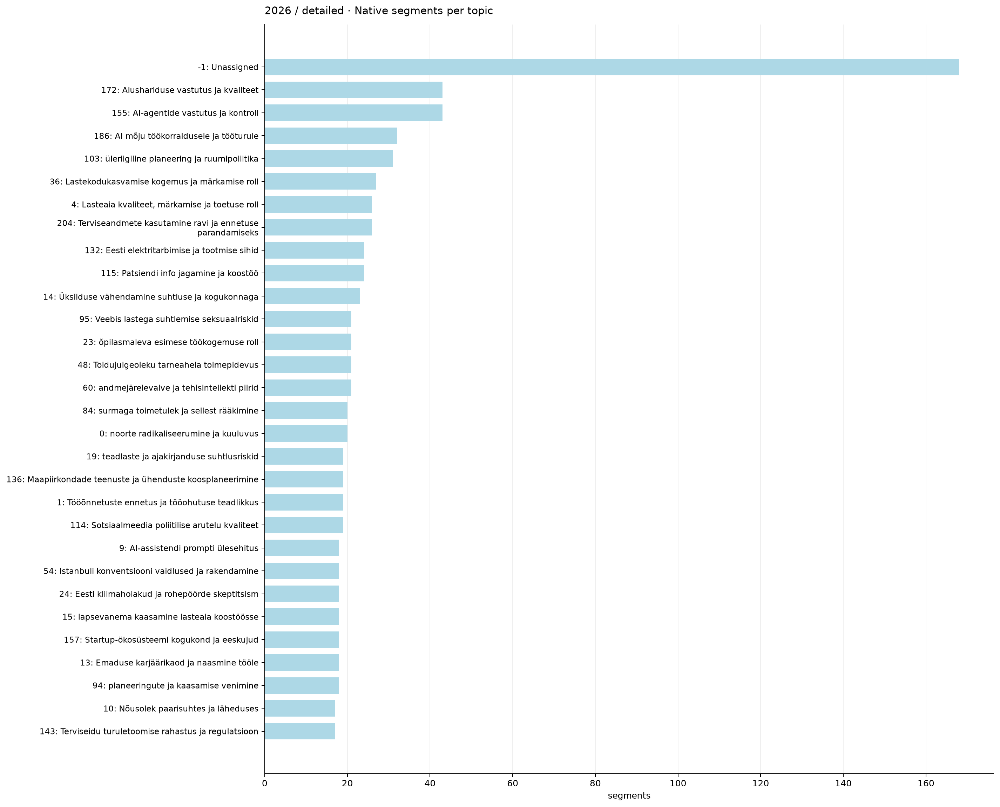

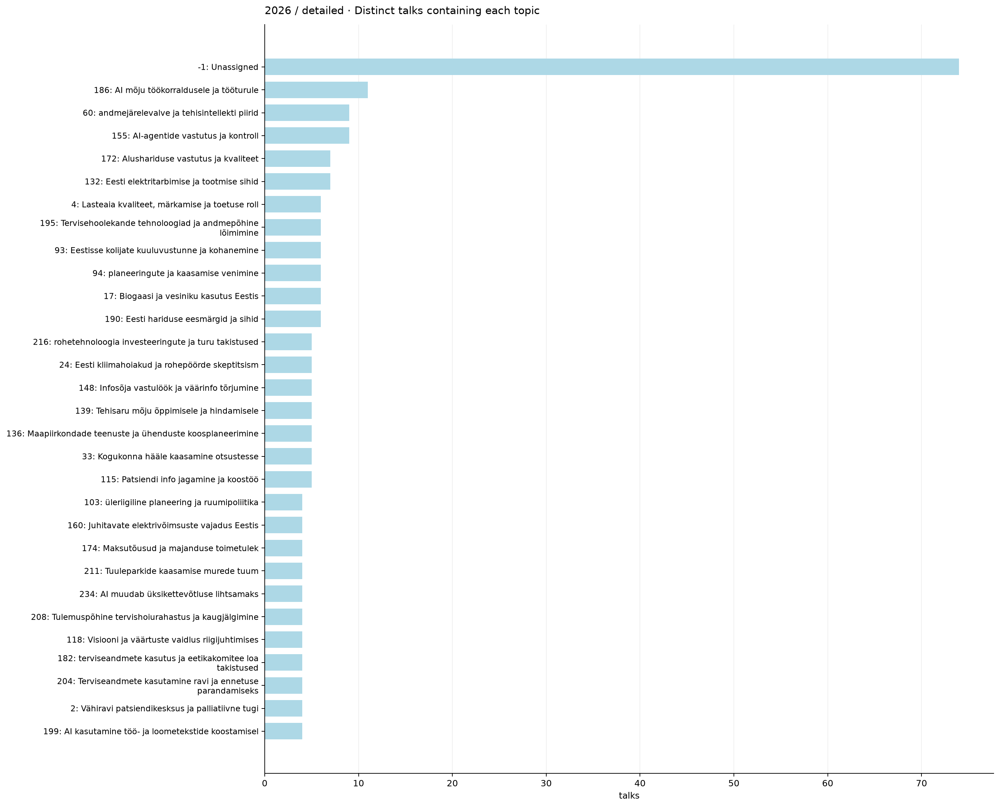

,topic_name,high_level_id,segments,talks,total_minutes,label
analysis_topic,,,,,,
-1,Unassigned,unassigned,168,74,501.412150,-1: Unassigned
172,Alushariduse vastutus ja kvaliteet,education,43,7,207.084867,172: Alushariduse vastutus ja kvaliteet
155,AI-agentide vastutus ja kontroll,ai,43,9,189.667333,155: AI-agentide vastutus ja kontroll
186,AI mõju töökorraldusele ja tööturule,ai,32,11,153.578333,186: AI mõju töökorraldusele ja tööturule
103,üleriigiline planeering ja ruumipoliitika,place,31,4,129.923467,103: üleriigiline planeering ja ruumipoliitika
...,...,...,...,...,...,...
74,eestikeelse suhtluse ja ühiskeele otsimine,migration,1,1,3.852667,74: eestikeelse suhtluse ja ühiskeele otsimine
64,Eesti 2050 ühised unistused ja tulevikunägemus,governance,1,1,3.363333,64: Eesti 2050 ühised unistused ja tulevikunäg...
68,Ettevõtliku hoiakuga kooli ja töö sidumine,education,1,1,5.337333,68: Ettevõtliku hoiakuga kooli ja töö sidumine


### Topic duration: totals, means and observed 95% HDIs

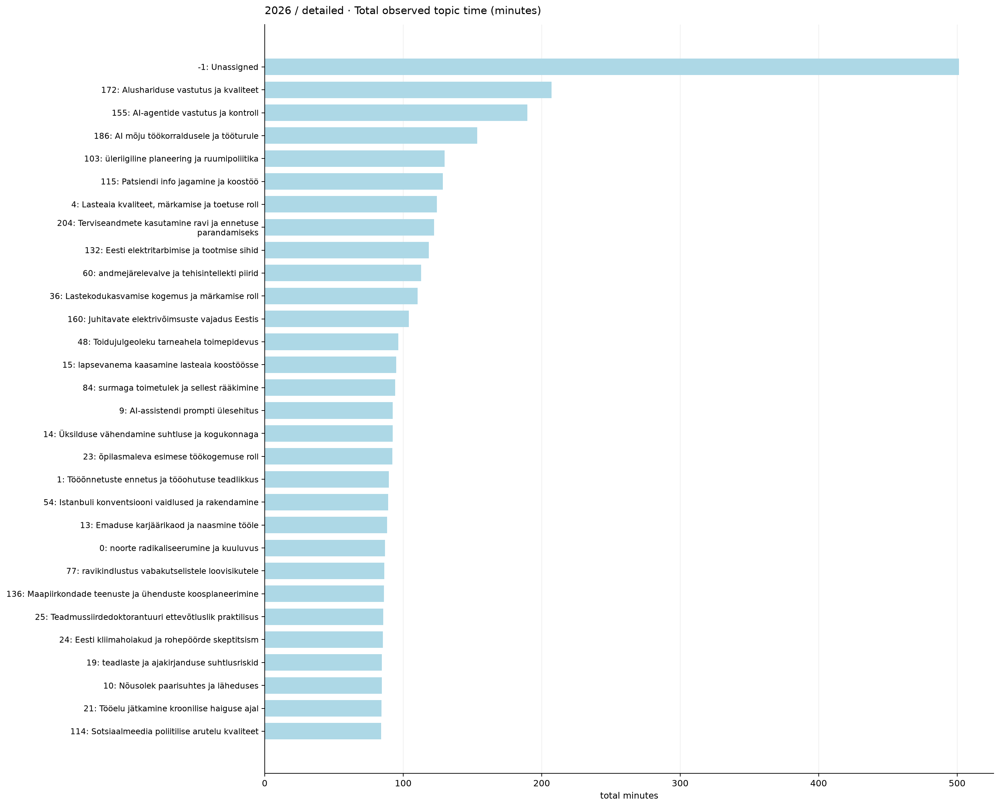

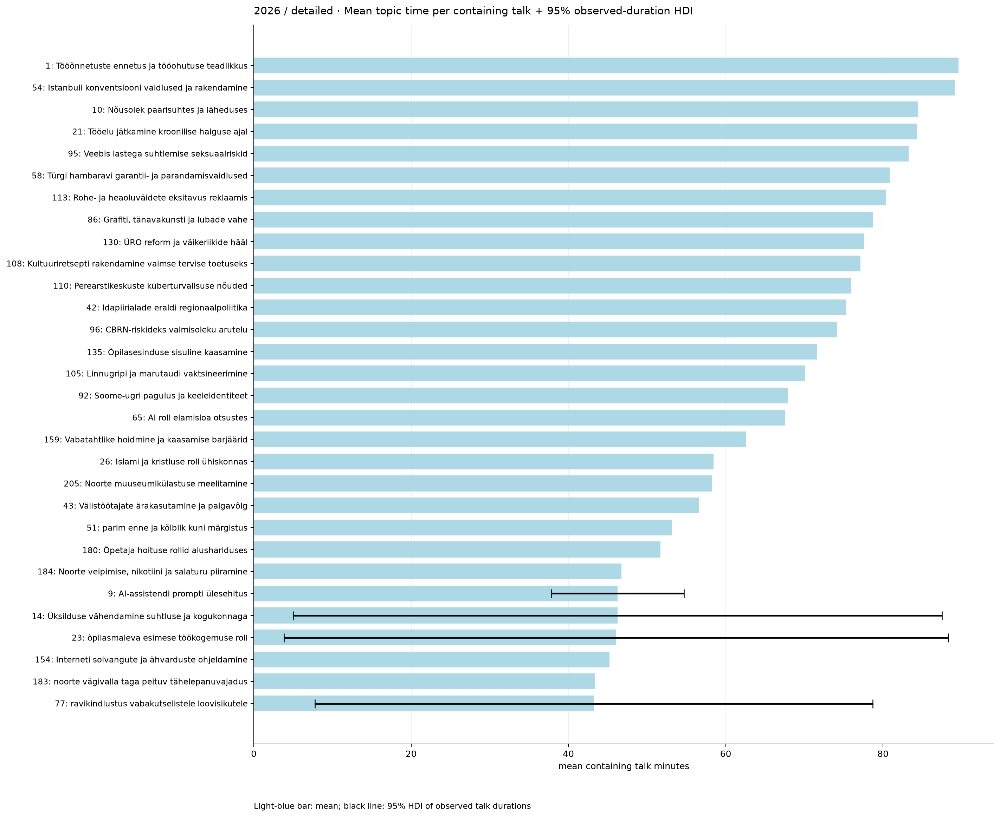

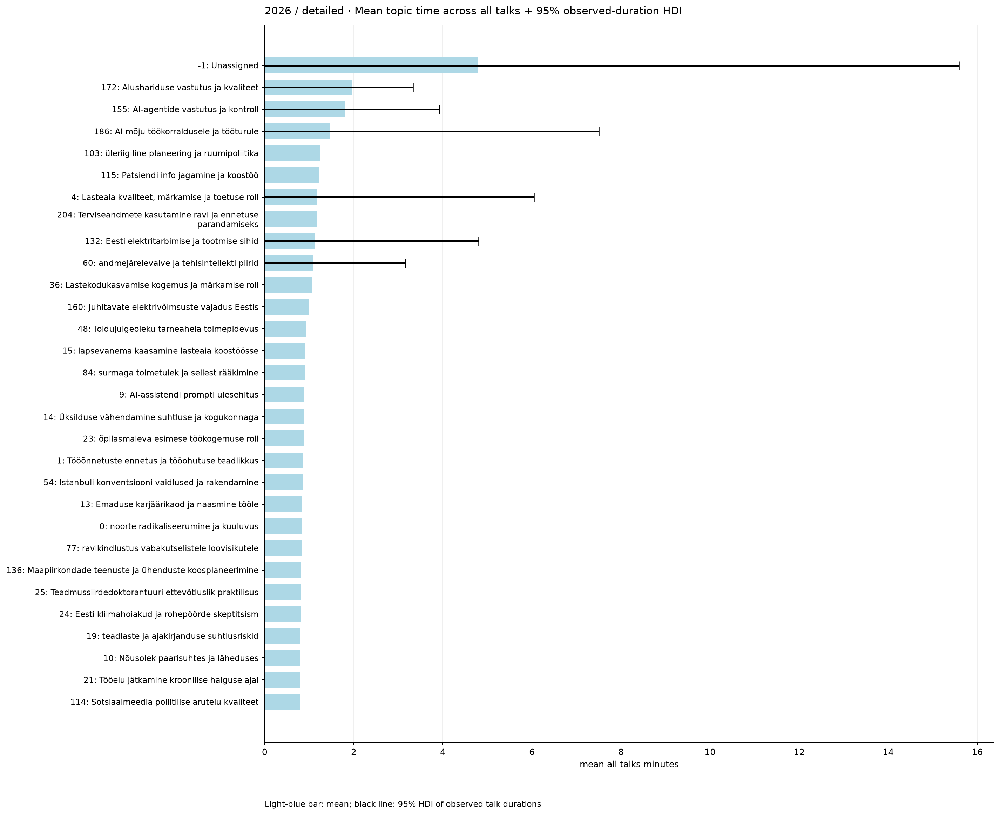

,topic_name,high_level_id,segments,talks,total_minutes,label,mean_all_talks_minutes,mean_containing_talk_minutes,all_hdi_low,all_hdi_high,containing_hdi_low,containing_hdi_high,min_containing_minutes,p25_containing_minutes,median_containing_minutes,p75_containing_minutes,max_containing_minutes
analysis_topic,,,,,,,,,,,,,,,,,
-1,Unassigned,unassigned,168,74,501.412150,-1: Unassigned,4.775354,6.775840,0.0,15.588667,1.583333,17.309333,1.583333,3.416667,5.366617,8.760321,22.578000
0,noorte radikaliseerumine ja kuuluvus,children,20,3,86.775550,0: noorte radikaliseerumine ja kuuluvus,0.826434,28.925183,0.0,0.000000,2.074000,75.062217,2.074000,5.856667,9.639333,42.350775,75.062217
1,Tööõnnetuste ennetus ja tööohutuse teadlikkus,work,19,1,89.611967,1: Tööõnnetuste ennetus ja tööohutuse teadlikkus,0.853447,89.611967,0.0,0.000000,NaN,NaN,89.611967,89.611967,89.611967,89.611967,89.611967
10,Nõusolek paarisuhtes ja läheduses,family,17,1,84.477617,10: Nõusolek paarisuhtes ja läheduses,0.804549,84.477617,0.0,0.000000,NaN,NaN,84.477617,84.477617,84.477617,84.477617,84.477617
101,Liikumisharjumuste kujundamine lastel,wellbeing,2,2,3.842000,101: Liikumisharjumuste kujundamine lastel,0.036590,1.921000,0.0,0.000000,1.573333,2.268667,1.573333,1.747167,1.921000,2.094833,2.268667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,planeeringute ja kaasamise venimine,place,18,6,76.788667,94: planeeringute ja kaasamise venimine,0.731321,12.798111,0.0,1.703333,1.703333,60.620667,1.703333,2.187833,2.814667,5.846000,60.620667
95,Veebis lastega suhtlemise seksuaalriskid,children,21,1,83.271567,95: Veebis lastega suhtlemise seksuaalriskid,0.793063,83.271567,0.0,0.000000,NaN,NaN,83.271567,83.271567,83.271567,83.271567,83.271567
96,CBRN-riskideks valmisoleku arutelu,defence,15,1,74.174717,96: CBRN-riskideks valmisoleku arutelu,0.706426,74.174717,0.0,0.000000,NaN,NaN,74.174717,74.174717,74.174717,74.174717,74.174717


### Topic co-occurrence tables

,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,name_a,name_b
4637,132,160,4,7,4,105,0.266667,15.000000,0.571429,0.828741,0.828741,0.785176,0.368330,Eesti elektritarbimise ja tootmise sihid,Juhitavate elektrivõimsuste vajadus Eestis
5905,143,182,3,3,4,105,0.114286,26.250000,0.750000,0.919085,0.919085,0.856668,0.344657,Terviseidu turuletoomise rahastus ja regulatsioon,terviseandmete kasutus ja eetikakomitee loa ta...
820,103,56,3,4,3,105,0.114286,26.250000,0.750000,0.919085,0.919085,0.856668,0.344657,üleriigiline planeering ja ruumipoliitika,Noorte koduostu ja üüri kättesaadavus
8197,160,223,3,4,3,105,0.114286,26.250000,0.750000,0.919085,0.919085,0.856668,0.344657,Juhitavate elektrivõimsuste vajadus Eestis,Eleringi vähempakkumised uute elektrivõimsuste...
8163,160,181,3,4,3,105,0.114286,26.250000,0.750000,0.919085,0.919085,0.856668,0.344657,Juhitavate elektrivõimsuste vajadus Eestis,Eesti elektritarbimise kasv ja puudujääk
10019,182,204,3,4,4,105,0.152381,19.687500,0.600000,0.838169,0.838169,0.791422,0.314314,terviseandmete kasutus ja eetikakomitee loa ta...,Terviseandmete kasutamine ravi ja ennetuse par...
4643,132,17,4,7,6,105,0.400000,10.000000,0.444444,0.704657,0.704657,0.678991,0.313181,Eesti elektritarbimise ja tootmise sihid,Biogaasi ja vesiniku kasutus Eestis
9117,172,4,4,7,6,105,0.400000,10.000000,0.444444,0.704657,0.704657,0.678991,0.313181,Alushariduse vastutus ja kvaliteet,"Lasteaia kvaliteet, märkamise ja toetuse roll"
7517,155,60,5,9,9,105,0.771429,6.481481,0.384615,0.613873,0.613873,0.597156,0.306936,AI-agentide vastutus ja kontroll,andmejärelevalve ja tehisintellekti piirid
8498,166,17,3,3,6,105,0.171429,17.500000,0.500000,0.805041,0.805041,0.758286,0.301890,Puidu väärindamine raiemahtu vähendades,Biogaasi ja vesiniku kasutus Eestis


### Topic co-occurrence heatmap

### Topic–organizer associations and metadata coverage

...

Programme entries with missing organizer fields (other roles are retained separately):


,episode_id,title,programme_stage,programme_curator,programme_support_text


,topic_a,topic_b,shared_talks,a_talks,b_talks,eligible_talks,expected_shared,lift,jaccard,npmi,positive_npmi,smoothed_npmi,discounted_npmi,topic_name
6432,2,eesti vähitõrje võrgustik (estcan),4,4,5,105,0.190476,21.000000,0.800000,0.931712,0.931712,0.875963,0.414094,Vähiravi patsiendikesksus ja palliatiivne tugi
4651,172,lasteklubi väike päike,3,7,3,105,0.200000,15.000000,0.428571,0.761684,0.761684,0.719242,0.285631,Alushariduse vastutus ja kvaliteet
10231,6,eesti e-residentsuse programm,3,3,8,105,0.228571,13.125000,0.375000,0.724126,0.724126,0.684803,0.271547,AI-agentide volitamine isikukoodi kaudu
1890,13,eesti personalijuhtimise ühing pare ja tööinsp...,3,3,9,105,0.257143,11.666667,0.333333,0.690997,0.690997,0.653997,0.259124,Emaduse karjäärikaod ja naasmine tööle
11970,90,eesti personalijuhtimise ühing pare ja tööinsp...,3,3,9,105,0.257143,11.666667,0.333333,0.690997,0.690997,0.653997,0.259124,kaugtöö ja töövälise aja piirid
3607,155,eesti e-residentsuse programm,4,9,8,105,0.685714,5.833333,0.307692,0.539709,0.539709,0.529261,0.239871,AI-agentide vastutus ja kontroll
5551,186,eesti e-residentsuse programm,4,11,8,105,0.838095,4.772727,0.266667,0.478298,0.478298,0.471724,0.212577,AI mõju töökorraldusele ja tööturule
10303,60,eesti e-residentsuse programm,3,9,8,105,0.685714,4.375000,0.214286,0.415123,0.415123,0.416887,0.155671,andmejärelevalve ja tehisintellekti piirid


### Export manifest

Saved analysis to C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-topic-analysis\detailed\2026


In [10]:
if "detailed" in RUN_LEVELS and 2026 in RUN_YEARS:
    run_analysis(2026, "detailed")

# How topic proportions changed from 2025 to 2026

The comparison below uses the **same Jev detailed topics and parent dictionary** across years. It shows main-category shares, within-category subtopic changes and subjects only observed in one year. These are descriptive changes in the available recording corpus, which may have unequal programme-area coverage. The report explains denominators, support flags and the difference between global and within-parent changes.

Regenerate the saved comparison from the project root with `uv run --group topic-analysis python scripts/compare_jev_year_topics.py`. No classification API calls or new model fits are made.

# Topic changes: 2025 vs 2026

This compares **available transcribed recordings**, not the complete festival programmes.
The corpus has 114 talks from 2025 and 105 from 2026. Podcast publication ends in
May 2026 for the 2025 subset and September 2026 for the 2026 subset; programme areas
may have been uploaded in batches. Apparent shifts can therefore reflect recording
availability and selected programme areas, not a change in society or festival-wide
priorities. No claim of significance or causal evolution is made.

The shared 236-topic Jev vocabulary and 20-category dictionary keep labels comparable.
Primary percentages use each year's **total segmented time, including unassigned**.
Talk coverage is the proportion of that year's talks containing a topic; it is
nonadditive. Segment-share and assigned-time-only alternatives are included in CSVs
(unassigned rows should not be interpreted as assigned-time shares).

Within-parent percentages divide each subtopic's time by its category's time in the
same year. A subtopic can gain global share just because its whole category grew;
within-parent changes show shifts in the category's composition. CSV decomposition
splits global change into parent expansion at the old mix, plus mix change at the
new parent size; it is an accounting identity whose components depend on ordering.

“Only observed in 2026/2025” means zero saved primary-label segments in the other
year, not that the subject was newly invented or disappeared. All such topics are
exported. A separate support flag requires at least 10 minutes across 2 talks in the
observed year; sparse examples remain visible. Categories/subtopics have no refit.

## What changed in these recordings

AI and digital technology expanded from 0.73% to 8.21% of discussion time (+7.47 percentage points); healthcare grew from 6.85% to 10.76% (+3.91 pp). Place/housing rose by 3.58 pp, migration by 3.04 pp and family by 2.87 pp. The largest decreases were governance (−7.58 pp), nature/forestry/resources (−7.56 pp), defence (−7.18 pp) and international affairs (−5.31 pp).

Inside AI, agent responsibility/control rose from 3.03% to 25.13% of AI time; prompt construction rose from 2.27% to 12.32%. AI impact on work fell from 55.19% to 20.90% of the category, while its share of ALL discussion time still increased by 1.31 pp. This is relative redistribution inside a much larger category, not disappearance of work-related AI.

Energy's overall share was almost stable (5.91% → 6.05%), yet its mix changed: electricity consumption/production targets rose from 4.51% to 21.45% of energy time, and exchange pricing from 0.82% to 13.47%. Biogas/hydrogen fell from 15.94% to 5.18%, and turbine infrasound from 11.47% to 0.40%.

Education slightly declined overall (13.73% → 12.45%), but early-childhood education responsibility/quality accounted for 17.71% of education in 2026 and had no primary-label segments in the 2025 sample. Within healthcare, health-data use grew from 1.29% to 12.43% of the category. These patterns can reflect the programme areas available in each recording subset.

## Main topic changes

| jev_high_level_name                                   |   time_share_2025 |   time_share_2026 |   time_share_delta_pp |   talk_coverage_2025 |   talk_coverage_2026 |
|:------------------------------------------------------|------------------:|------------------:|----------------------:|---------------------:|---------------------:|
| Tehisintellekt ja digitehnoloogia                     |              0.73 |              8.14 |                  7.41 |                 8.77 |                18.1  |
| Tervishoid, ravi ja terviseandmed                     |              6.84 |             10.74 |                  3.9  |                10.53 |                16.19 |
| Eluase, ruum ja ühendused                             |              2.64 |              6.08 |                  3.43 |                 7.02 |                10.48 |
| Pere, suhted ja sooline võrdsus                       |              1.81 |              4.72 |                  2.91 |                 3.51 |                 5.71 |
| Ränne, lõimumine ja kuuluvus                          |              2.23 |              5.13 |                  2.9  |                 7.02 |                11.43 |
| Laste ja noorte kaitse ning toetamine                 |              2.35 |              5.06 |                  2.71 |                 6.14 |                10.48 |
| Kultuur, loome ja pärand                              |              2.08 |              4.23 |                  2.15 |                 4.39 |                 4.76 |
| Toit, põllumajandus ja toidujulgeolek                 |              0.23 |              1.64 |                  1.41 |                 1.75 |                 4.76 |
| Vaimne tervis, tervisekäitumine ja ennetus            |              4.61 |              5.86 |                  1.25 |                14.91 |                16.19 |
| Küberturvalisus, privaatsus ja digiohud               |              1.39 |              2.56 |                  1.17 |                 5.26 |                10.48 |
| Meedia, avalik arutelu ja infokvaliteet               |              2.23 |              3.16 |                  0.93 |                 9.65 |                 6.67 |
| Kliima, rohepööre ja kestlik tarbimine                |              3.92 |              4.63 |                  0.71 |                20.18 |                12.38 |
| Energeetika ja energiaturud                           |              5.89 |              6.25 |                  0.35 |                13.16 |                11.43 |
| Majandus, ettevõtlus ja innovatsioon                  |              3.18 |              2.7  |                 -0.48 |                14.04 |                12.38 |
| Tööelu, juhtimine ja töötajate õigused                |              7.53 |              6.97 |                 -0.57 |                18.42 |                12.38 |
| Haridus, õppimine ja oskused                          |             13.6  |             12.66 |                 -0.94 |                36.84 |                28.57 |
| Määramata                                             |              7.12 |              5.48 |                 -1.64 |                71.05 |                70.48 |
| Rahvusvahelised suhted, Euroopa Liit ja humanitaarabi |              6.29 |              0.92 |                 -5.37 |                14.04 |                 1.9  |
| Riigikaitse, julgeolek ja kriisivalmidus              |              8.04 |              0.92 |                 -7.12 |                12.28 |                 4.76 |
| Loodus, metsandus ja maavarad                         |              7.88 |              0.38 |                 -7.5  |                11.4  |                 3.81 |
| Riigijuhtimine, kodanikuühiskond ja õigus             |              9.39 |              1.78 |                 -7.62 |                26.32 |                13.33 |

## Observed emergence and absence

43 detailed topics only observed in 2026 (17 meet the support flag); 62 only observed in 2025 (31 meet it).

### Only observed in 2026: largest by time share

| jev_topic_name                                        |   time_share_2026 |   minutes_2026 |   talks_2026 | supported_2026   |
|:------------------------------------------------------|------------------:|---------------:|-------------:|:-----------------|
| Alushariduse vastutus ja kvaliteet                    |              2.27 |         207.08 |            7 | True             |
| Toidujulgeoleku tarneahela toimepidevus               |              1.06 |          96.51 |            4 | True             |
| lapsevanema kaasamine lasteaia koostöösse             |              1.04 |          95    |            3 | True             |
| ravikindlustus vabakutselistele loovisikutele         |              0.95 |          86.47 |            2 | True             |
| teadlaste ja ajakirjanduse suhtlusriskid              |              0.92 |          84.56 |            2 | True             |
| Tööelu jätkamine kroonilise haiguse ajal              |              0.92 |          84.34 |            1 | False            |
| Türgi hambaravi garantii- ja parandamisvaidlused      |              0.88 |          80.82 |            1 | False            |
| Grafiti, tänavakunsti ja lubade vahe                  |              0.86 |          78.75 |            1 | False            |
| Eestisse kolinud pagulaste kuuluvus ja kohanemine     |              0.85 |          77.83 |            2 | True             |
| Kultuuriretsepti rakendamine vaimse tervise toetuseks |              0.84 |          77.15 |            1 | False            |
| AI päringute energiakulu läbipaistvus                 |              0.84 |          77.01 |            2 | True             |
| Perearstikeskuste küberturvalisuse nõuded             |              0.83 |          75.98 |            1 | False            |
| Autoriõigused ja AI treeningu läbipaistvus            |              0.82 |          75.37 |            3 | True             |
| AI-agentide volitamine isikukoodi kaudu               |              0.82 |          75.36 |            3 | True             |
| Käibemaksu ja toetuste mõju kultuurile                |              0.82 |          74.65 |            2 | True             |

### Only observed in 2025: largest by time share

| jev_topic_name                                       |   time_share_2025 |   minutes_2025 |   talks_2025 | supported_2025   |
|:-----------------------------------------------------|------------------:|---------------:|-------------:|:-----------------|
| Lai riigikaitse kodune ja kogukondlik valmisolek     |              2.11 |         209.54 |            7 | True             |
| Fosforiidi kaevandamise riskid ja ringfosfor         |              1.47 |         146.34 |            2 | True             |
| Kaitsekulude tõus ja hanked                          |              1.32 |         131.11 |            7 | True             |
| Metsa raiemahtude ja kaitse vaidlus                  |              1.05 |         104.1  |            6 | True             |
| Vasakpoolsuse ja identiteedi pinged                  |              0.93 |          92.21 |            2 | True             |
| Vabaühenduste rahastamise läbipaistvus ja sõltumatus |              0.93 |          92.2  |            2 | True             |
| Von der Leyeni EL-i eelarve ja maksud                |              0.9  |          89.11 |            3 | True             |
| Püsimetsanduse definitsioon ja valikraie             |              0.89 |          88.16 |            1 | False            |
| Korteriühistute kogukonnatunde loomine               |              0.87 |          86.7  |            1 | False            |
| Ukraina turule sisenemine kohaliku partneriga        |              0.87 |          86.43 |            3 | True             |
| Sooneutraalne ajateenistus ja reservi täitmine       |              0.85 |          84.6  |            4 | True             |
| Naiste osakaalu suurendamine IKT-s                   |              0.85 |          84.42 |            2 | True             |
| laste hambaravi, narkoos ja vanema vastutus          |              0.85 |          84.28 |            1 | False            |
| Ajaloolised paralleelid tänapäeva konfliktidele      |              0.85 |          84.13 |            5 | True             |
| Noorte alkoholiga pidutsemine ja surve               |              0.83 |          82.56 |            1 | False            |

## Inside each main topic

### Tehisintellekt ja digitehnoloogia

| jev_topic_name                                  |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| AI mõju töökorraldusele ja tööturule            |                      55.19 |                      20.63 |                   -34.56 |                  1.27 |            7 |           11 |
| AI kasutamine töö- ja loometekstide koostamisel |                      31.25 |                       1.92 |                   -29.33 |                 -0.07 |            4 |            4 |
| AI-agentide vastutus ja kontroll                |                       3.03 |                      25.48 |                    22.44 |                  2.05 |            1 |            9 |
| AI-assistendi prompti ülesehitus                |                       2.27 |                      12.43 |                    10.16 |                  1    |            1 |            2 |
| Autoriõigused ja AI treeningu läbipaistvus      |                       0    |                      10.12 |                    10.12 |                  0.82 |            0 |            3 |

### Laste ja noorte kaitse ning toetamine

| jev_topic_name                               |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:---------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| lapsega esmakontakti loomine lastekaitses    |                      21.65 |                       1.21 |                   -20.44 |                 -0.45 |            1 |            2 |
| Laste internetikäitumine ja abiotsimine      |                      20.27 |                       1.15 |                   -19.12 |                 -0.42 |            4 |            1 |
| Lastekodukasvamise kogemus ja märkamise roll |                       6.4  |                      23.9  |                    17.5  |                  1.06 |            1 |            3 |
| Laste ja AI-petuste internetiohud            |                      18.09 |                       3.21 |                   -14.88 |                 -0.26 |            1 |            2 |
| Veebis lastega suhtlemise seksuaalriskid     |                       6.99 |                      18.02 |                    11.03 |                  0.75 |            3 |            1 |

### Kliima, rohepööre ja kestlik tarbimine

| jev_topic_name                                     |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:---------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| AI päringute energiakulu läbipaistvus              |                       0    |                      18.19 |                    18.19 |                  0.84 |            0 |            2 |
| kliimariski mõju vee- ja soojusvarustusele         |                       2.93 |                      17.68 |                    14.75 |                  0.7  |            2 |            4 |
| Minimalistlik ökoeluviis ja piisavus               |                      15.35 |                       1.16 |                   -14.19 |                 -0.55 |            2 |            1 |
| Rohetehnoloogia rahastus ja laenuotsused           |                      13.91 |                       0.81 |                   -13.1  |                 -0.51 |            4 |            1 |
| rohetehnoloogia investeeringute ja turu takistused |                      24.5  |                      12.61 |                   -11.89 |                 -0.38 |           12 |            5 |

### Kultuur, loome ja pärand

| jev_topic_name                                |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:----------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Koduloomuuseumi rahastamine ja jätkamine      |                      33.13 |                       0    |                   -33.13 |                 -0.69 |            1 |            0 |
| noorte filmiarutelud ja tagasiside            |                      28.86 |                       0    |                   -28.86 |                 -0.6  |            1 |            0 |
| Emadus ja koolikultuur kultuuri kandjana      |                      24.32 |                       0    |                   -24.32 |                 -0.51 |            2 |            0 |
| ravikindlustus vabakutselistele loovisikutele |                       0    |                      22.38 |                    22.38 |                  0.95 |            0 |            2 |
| Grafiti, tänavakunsti ja lubade vahe          |                       0    |                      20.38 |                    20.38 |                  0.86 |            0 |            1 |

### Küberturvalisus, privaatsus ja digiohud

| jev_topic_name                                 |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:-----------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Paroolide ja wifi kaudu levinud küberpettused  |                      46.88 |                       0    |                   -46.88 |                 -0.65 |            1 |            0 |
| andmejärelevalve ja tehisintellekti piirid     |                       9.02 |                      48.26 |                    39.24 |                  1.11 |            3 |            9 |
| Laste piltide postitamine vanemate poolt       |                      38.62 |                       0    |                   -38.62 |                 -0.54 |            1 |            0 |
| Perearstikeskuste küberturvalisuse nõuded      |                       0    |                      32.44 |                    32.44 |                  0.83 |            0 |            1 |
| Interneti solvangute ja ähvarduste ohjeldamine |                       5.49 |                      19.3  |                    13.82 |                  0.42 |            2 |            1 |

### Riigikaitse, julgeolek ja kriisivalmidus

| jev_topic_name                                   |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:-------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| CBRN-riskideks valmisoleku arutelu               |                       0    |                      88.39 |                    88.39 |                  0.81 |            0 |            1 |
| Lai riigikaitse kodune ja kogukondlik valmisolek |                      26.26 |                       0    |                   -26.26 |                 -2.11 |            7 |            0 |
| Kaitsekulude tõus ja hanked                      |                      16.43 |                       0    |                   -16.43 |                 -1.32 |            7 |            0 |
| Sooneutraalne ajateenistus ja reservi täitmine   |                      10.6  |                       0    |                   -10.6  |                 -0.85 |            4 |            0 |
| naiste ajateenistuse laiendamine riigikaitses    |                      10.25 |                       0    |                   -10.25 |                 -0.82 |            3 |            0 |

### Majandus, ettevõtlus ja innovatsioon

| jev_topic_name                                           |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:---------------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Ukraina turule sisenemine kohaliku partneriga            |                      27.38 |                       0    |                   -27.38 |                 -0.87 |            3 |            0 |
| Startup-ökosüsteemi kogukond ja eeskujud                 |                       2.92 |                      30.26 |                    27.35 |                  0.72 |            2 |            3 |
| Startupide registreerimise ja fondi-õiguse lihtsustamine |                       0    |                      23.74 |                    23.74 |                  0.64 |            0 |            2 |
| Väikeettevõtjate maksud, hanked ja eksport               |                      23.66 |                       1.32 |                   -22.33 |                 -0.72 |            5 |            2 |
| Majanduskasvu ja heaolu vaidlus                          |                      16.56 |                      23.21 |                     6.64 |                  0.1  |            9 |            3 |

### Haridus, õppimine ja oskused

| jev_topic_name                                |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:----------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Alushariduse vastutus ja kvaliteet            |                       0    |                      17.89 |                    17.89 |                  2.27 |            0 |            7 |
| Lasteaia kvaliteet, märkamise ja toetuse roll |                       0.2  |                      10.74 |                    10.54 |                  1.33 |            1 |            6 |
| Eesti hariduse eesmärgid ja sihid             |                      13.22 |                       2.74 |                   -10.48 |                 -1.45 |           19 |            6 |
| lapsevanema kaasamine lasteaia koostöösse     |                       0    |                       8.2  |                     8.2  |                  1.04 |            0 |            3 |
| õpilasmaleva esimese töökogemuse roll         |                       0.77 |                       7.96 |                     7.19 |                  0.9  |            1 |            2 |

### Energeetika ja energiaturud

| jev_topic_name                                    |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:--------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Eesti elektritarbimise ja tootmise sihid          |                       4.52 |                      20.77 |                    16.25 |                  1.03 |            4 |            7 |
| Elektribörsi hinnakujunduse jaotumine             |                       0.82 |                      13.05 |                    12.23 |                  0.77 |            1 |            3 |
| Tuulikuinfraheli häirivuse ja tervisemõju vaidlus |                      11.51 |                       0.39 |                   -11.12 |                 -0.65 |            2 |            1 |
| Biogaasi ja vesiniku kasutus Eestis               |                      15.99 |                       7.04 |                    -8.95 |                 -0.5  |            4 |            6 |
| Tuuleparkide kaasamise usalduskriis               |                       9.95 |                       1.23 |                    -8.73 |                 -0.51 |            1 |            2 |

### Pere, suhted ja sooline võrdsus

| jev_topic_name                                   |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:-------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| sündimuse toetamine läbi perekindluse            |                      51.33 |                       0.76 |                   -50.57 |                 -0.89 |            2 |            1 |
| Õige keha- ja seksuaalsõnavara õpetamine         |                      27.58 |                       0.38 |                   -27.2  |                 -0.48 |            1 |            1 |
| Emaduse karjäärikaod ja naasmine tööle           |                       1.47 |                      20.45 |                    18.98 |                  0.94 |            1 |            3 |
| Naiste juhtide ja isade rolliootused             |                       0.89 |                      17.64 |                    16.75 |                  0.82 |            1 |            3 |
| Istanbuli konventsiooni vaidlused ja rakendamine |                       6.35 |                      20.63 |                    14.28 |                  0.86 |            1 |            1 |

### Toit, põllumajandus ja toidujulgeolek

| jev_topic_name                           |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:-----------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Valgu tootmine kohalike biojääkide pealt |                        100 |                       0    |                  -100    |                 -0.23 |            2 |            0 |
| Toidujulgeoleku tarneahela toimepidevus  |                          0 |                      64.47 |                    64.47 |                  1.06 |            0 |            4 |
| parim enne ja kõlblik kuni märgistus     |                          0 |                      35.53 |                    35.53 |                  0.58 |            0 |            1 |

### Riigijuhtimine, kodanikuühiskond ja õigus

| jev_topic_name                                       |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:-----------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Vabatahtlike hoidmine ja kaasamise barjäärid         |                       0.77 |                      38.53 |                    37.76 |                  0.61 |            2 |            1 |
| Kogukonna hääle kaasamine otsustesse                 |                       6.35 |                      17.87 |                    11.52 |                 -0.28 |            8 |            5 |
| Vasakpoolsuse ja identiteedi pinged                  |                       9.89 |                       0    |                    -9.89 |                 -0.93 |            2 |            0 |
| Vabaühenduste rahastamise läbipaistvus ja sõltumatus |                       9.89 |                       0    |                    -9.89 |                 -0.93 |            2 |            0 |
| Eesti 2050 ühised unistused ja tulevikunägemus       |                      11.42 |                       2.07 |                    -9.35 |                 -1.04 |            6 |            1 |

### Tervishoid, ravi ja terviseandmed

| jev_topic_name                                           |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:---------------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Perearsti tööjaotus ja koostöövõrgustik                  |                      14.6  |                       1.39 |                   -13.21 |                 -0.85 |            5 |            1 |
| laste hambaravi, narkoos ja vanema vastutus              |                      12.43 |                       0    |                   -12.43 |                 -0.85 |            1 |            0 |
| Ülekaaluravimite hüvitamine ja elustiil                  |                      11.73 |                       0    |                   -11.73 |                 -0.8  |            1 |            0 |
| Terviseandmete kasutamine ravi ja ennetuse parandamiseks |                       1.29 |                      12.46 |                    11.16 |                  1.25 |            2 |            4 |
| Haigekassa rahastusmudeli ümbermõtestamine               |                      12.3  |                       1.33 |                   -10.98 |                 -0.7  |            3 |            3 |

### Rahvusvahelised suhted, Euroopa Liit ja humanitaarabi

| jev_topic_name                                  |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| ÜRO reform ja väikeriikide hääl                 |                      11.64 |                      92.35 |                    80.71 |                  0.12 |            4 |            1 |
| Von der Leyeni EL-i eelarve ja maksud           |                      14.28 |                       0    |                   -14.28 |                 -0.9  |            3 |            0 |
| Ajaloolised paralleelid tänapäeva konfliktidele |                      13.48 |                       0    |                   -13.48 |                 -0.85 |            5 |            0 |
| Trumpi mõju USA poliitika ja Ukraina suunal     |                      17.86 |                       5.71 |                   -12.14 |                 -1.07 |            5 |            1 |
| Palestiina tunnustamise ja kahe riigi debatt    |                      10.88 |                       0    |                   -10.88 |                 -0.68 |            2 |            0 |

### Meedia, avalik arutelu ja infokvaliteet

| jev_topic_name                                            |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:----------------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Infosõja vastulöök ja väärinfo tõrjumine                  |                      54.13 |                      13.88 |                   -40.26 |                 -0.77 |            5 |            5 |
| teadlaste ja ajakirjanduse suhtlusriskid                  |                       0    |                      29.25 |                    29.25 |                  0.92 |            0 |            2 |
| Rohe- ja heaolu­väidete eksitavus reklaamis               |                       1.29 |                      27.79 |                    26.5  |                  0.85 |            1 |            1 |
| Palestiina ja progressiivsete teemade kallutatud kajastus |                      21.14 |                       0    |                   -21.14 |                 -0.47 |            2 |            0 |
| Sotsiaalmeedia poliitilise arutelu kvaliteet              |                       9.17 |                      29.08 |                    19.92 |                  0.72 |            4 |            2 |

### Ränne, lõimumine ja kuuluvus

| jev_topic_name                                    |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:--------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Sisserände juhtimine ja talendivajadus            |                      28.55 |                       0.69 |                   -27.86 |                 -0.6  |            4 |            1 |
| eestikeelse suhtluse ja ühiskeele otsimine        |                      18.42 |                       0.82 |                   -17.6  |                 -0.37 |            4 |            1 |
| Eestisse kolinud pagulaste kuuluvus ja kohanemine |                       0    |                      16.6  |                    16.6  |                  0.85 |            0 |            2 |
| Soome-ugri pagulus ja keeleidentiteet             |                       0    |                      14.47 |                    14.47 |                  0.74 |            0 |            1 |
| AI roll elamisloa otsustes                        |                       0    |                      14.4  |                    14.4  |                  0.74 |            0 |            1 |

### Loodus, metsandus ja maavarad

| jev_topic_name                               |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:---------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Puidu väärindamine raiemahtu vähendades      |                       8.35 |                      73.61 |                    65.26 |                 -0.38 |            5 |            3 |
| Fosforiidi kaevandamise riskid ja ringfosfor |                      18.72 |                       0    |                   -18.72 |                 -1.47 |            2 |            0 |
| Kohtla-Järve tuhamägede väetisetehas         |                       0.77 |                      15.62 |                    14.84 |                 -0    |            1 |            1 |
| Metsa raiemahtude ja kaitse vaidlus          |                      13.32 |                       0    |                   -13.32 |                 -1.05 |            6 |            0 |
| Püsimetsanduse definitsioon ja valikraie     |                      11.28 |                       0    |                   -11.28 |                 -0.89 |            1 |            0 |

### Eluase, ruum ja ühendused

| jev_topic_name                                           |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:---------------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Korteriühistute kogukonnatunde loomine                   |                      33.05 |                       0    |                   -33.05 |                 -0.87 |            1 |            0 |
| Reisiks valmistumine ja turvalisus                       |                      21.28 |                       0    |                   -21.28 |                 -0.56 |            1 |            0 |
| üldplaneeringus haljastuse ja rohekoridoride säilitamine |                      20.91 |                       0    |                   -20.91 |                 -0.55 |            1 |            0 |
| üleriigiline planeering ja ruumipoliitika                |                       6.85 |                      23.39 |                    16.54 |                  1.24 |            2 |            4 |
| Idapiirialade eraldi regionaalpoliitika                  |                       1.26 |                      13.55 |                    12.29 |                  0.79 |            1 |            1 |

### Vaimne tervis, tervisekäitumine ja ennetus

| jev_topic_name                                        |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:------------------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Noorte alkoholiga pidutsemine ja surve                |                      18.05 |                       0    |                   -18.05 |                 -0.83 |            1 |            0 |
| laste nutiekraani ja sotsiaalmeedia sõltuvus          |                      27.34 |                      10.86 |                   -16.47 |                 -0.62 |            7 |            3 |
| Üksilduse vähendamine suhtluse ja kogukonnaga         |                       1.45 |                      17.27 |                    15.82 |                  0.95 |            3 |            2 |
| Liikumisharjumuste kujundamine lastel                 |                      16.51 |                       0.72 |                   -15.79 |                 -0.72 |            2 |            2 |
| Kultuuriretsepti rakendamine vaimse tervise toetuseks |                       0    |                      14.4  |                    14.4  |                  0.84 |            0 |            1 |

### Tööelu, juhtimine ja töötajate õigused

| jev_topic_name                                 |   within_parent_share_2025 |   within_parent_share_2026 |   within_parent_delta_pp |   time_share_delta_pp |   talks_2025 |   talks_2026 |
|:-----------------------------------------------|---------------------------:|---------------------------:|-------------------------:|----------------------:|-------------:|-------------:|
| Töökiusamise piiri tõmbamine tööl              |                      16.48 |                       1.97 |                   -14.51 |                 -1.1  |            3 |            1 |
| Tööelu jätkamine kroonilise haiguse ajal       |                       0    |                      13.24 |                    13.24 |                  0.92 |            0 |            1 |
| Miinimumpalga tõstmise mõju tööle ja vaesusele |                       0.52 |                      11.98 |                    11.45 |                  0.79 |            1 |            2 |
| Naiste osakaalu suurendamine IKT-s             |                      11.29 |                       0    |                   -11.29 |                 -0.85 |            2 |            0 |
| Juhi ja töötaja äärmused organisatsioonis      |                      10.96 |                       1.03 |                    -9.93 |                 -0.75 |            2 |            3 |



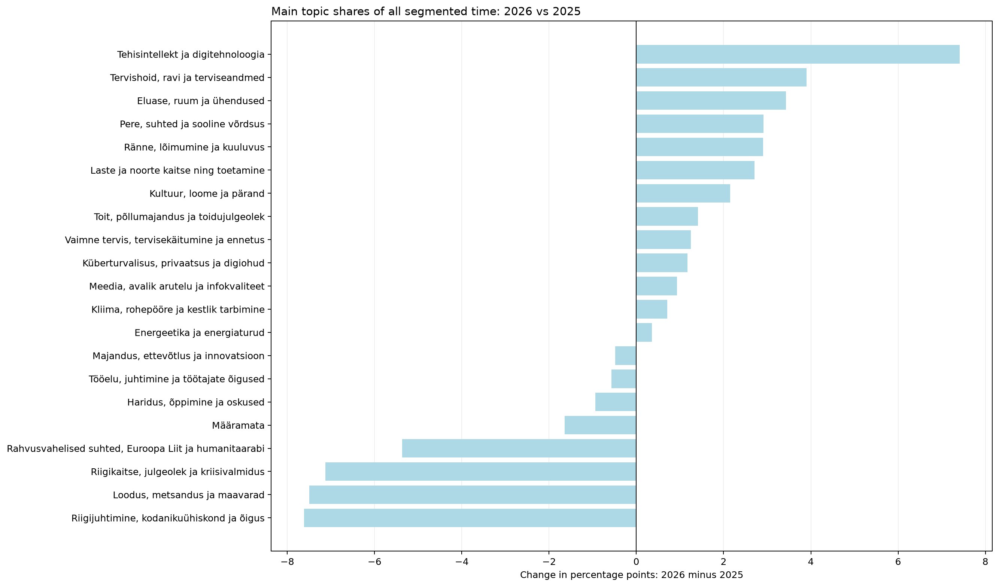

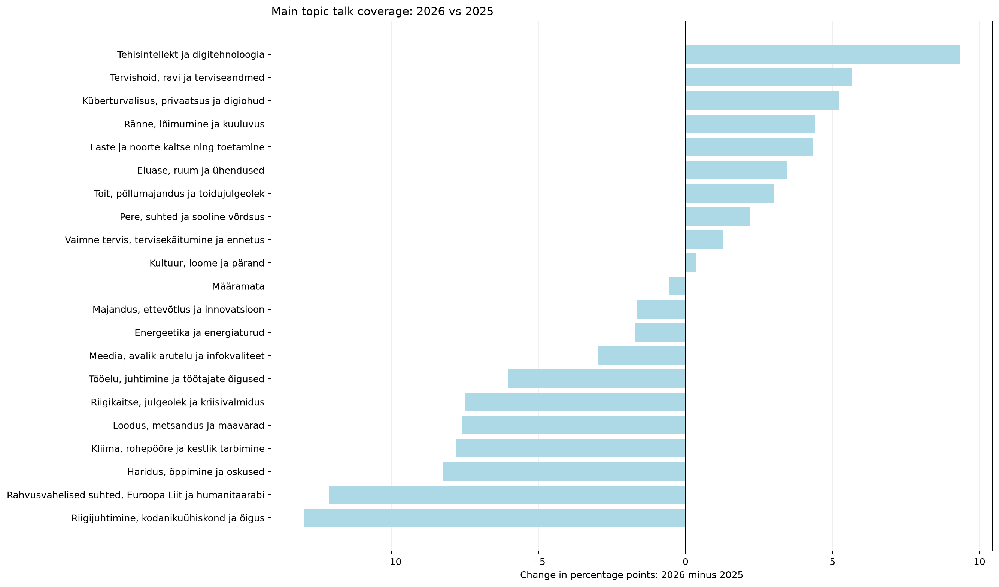

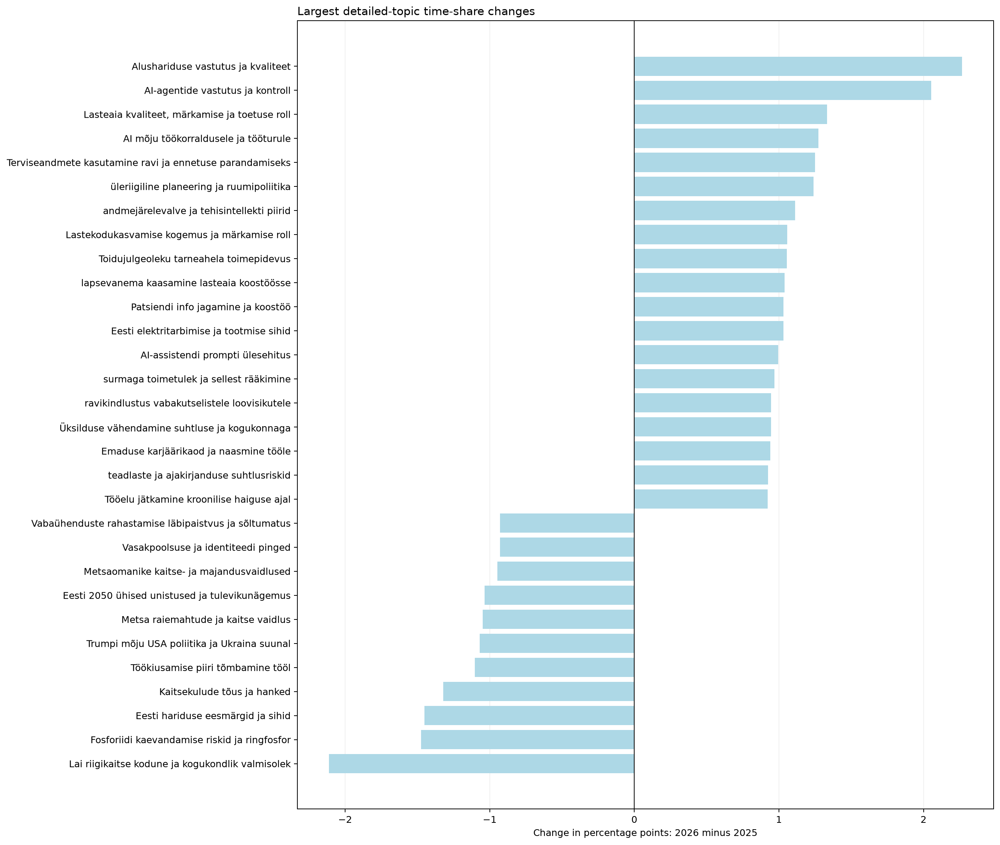

## Topics only observed in 2026 — complete list

,jev_topic_id,jev_topic_name,jev_high_level_id,jev_high_level_name,minutes_2025,minutes_2026,segments_2025,segments_2026,talks_2025,talks_2026,...,talk_coverage_delta_pp,assigned_time_share_delta_pp,status,supported_2026,supported_2025,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,parent_scale_component_pp,within_parent_mix_component_pp
0,172,Alushariduse vastutus ja kvaliteet,education,"Haridus, õppimine ja oskused",0.0,207.08,0.0,43.0,0.0,7.0,...,6.67,2.40,only_observed_2026,True,False,0.0,17.89,17.89,-0.0,2.27
1,48,Toidujulgeoleku tarneahela toimepidevus,food,"Toit, põllumajandus ja toidujulgeolek",0.0,96.51,0.0,21.0,0.0,4.0,...,3.81,1.12,only_observed_2026,True,False,0.0,64.47,64.47,0.0,1.06
2,15,lapsevanema kaasamine lasteaia koostöösse,education,"Haridus, õppimine ja oskused",0.0,95.00,0.0,18.0,0.0,3.0,...,2.86,1.10,only_observed_2026,True,False,0.0,8.20,8.20,-0.0,1.04
3,77,ravikindlustus vabakutselistele loovisikutele,culture,"Kultuur, loome ja pärand",0.0,86.47,0.0,15.0,0.0,2.0,...,1.90,1.00,only_observed_2026,True,False,0.0,22.38,22.38,0.0,0.95
4,19,teadlaste ja ajakirjanduse suhtlusriskid,media,"Meedia, avalik arutelu ja infokvaliteet",0.0,84.56,0.0,19.0,0.0,2.0,...,1.90,0.98,only_observed_2026,True,False,0.0,29.25,29.25,0.0,0.92
5,21,Tööelu jätkamine kroonilise haiguse ajal,work,"Tööelu, juhtimine ja töötajate õigused",0.0,84.34,0.0,17.0,0.0,1.0,...,0.95,0.98,only_observed_2026,False,False,0.0,13.24,13.24,-0.0,0.92
6,58,Türgi hambaravi garantii- ja parandamisvaidlused,healthcare,"Tervishoid, ravi ja terviseandmed",0.0,80.82,0.0,17.0,0.0,1.0,...,0.95,0.94,only_observed_2026,False,False,0.0,8.23,8.23,0.0,0.88
7,86,"Grafiti, tänavakunsti ja lubade vahe",culture,"Kultuur, loome ja pärand",0.0,78.75,0.0,16.0,0.0,1.0,...,0.95,0.91,only_observed_2026,False,False,0.0,20.38,20.38,0.0,0.86
8,121,Eestisse kolinud pagulaste kuuluvus ja kohanemine,migration,"Ränne, lõimumine ja kuuluvus",0.0,77.83,0.0,14.0,0.0,2.0,...,1.90,0.90,only_observed_2026,True,False,0.0,16.60,16.60,0.0,0.85
9,108,Kultuuriretsepti rakendamine vaimse tervise to...,wellbeing,"Vaimne tervis, tervisekäitumine ja ennetus",0.0,77.15,0.0,14.0,0.0,1.0,...,0.95,0.89,only_observed_2026,False,False,0.0,14.40,14.40,0.0,0.84


## Topics only observed in 2025 — complete list

,jev_topic_id,jev_topic_name,jev_high_level_id,jev_high_level_name,minutes_2025,minutes_2026,segments_2025,segments_2026,talks_2025,talks_2026,...,talk_coverage_delta_pp,assigned_time_share_delta_pp,status,supported_2026,supported_2025,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,parent_scale_component_pp,within_parent_mix_component_pp
0,45,Lai riigikaitse kodune ja kogukondlik valmisolek,defence,"Riigikaitse, julgeolek ja kriisivalmidus",209.54,0.0,44.0,0.0,7.0,0.0,...,-6.14,-2.27,only_observed_2025,False,True,26.26,0.0,-26.26,-1.87,-0.24
1,87,Fosforiidi kaevandamise riskid ja ringfosfor,nature,"Loodus, metsandus ja maavarad",146.34,0.0,30.0,0.0,2.0,0.0,...,-1.75,-1.59,only_observed_2025,False,True,18.72,0.0,-18.72,-1.40,-0.07
2,83,Kaitsekulude tõus ja hanked,defence,"Riigikaitse, julgeolek ja kriisivalmidus",131.11,0.0,28.0,0.0,7.0,0.0,...,-6.14,-1.42,only_observed_2025,False,True,16.43,0.0,-16.43,-1.17,-0.15
3,200,Metsa raiemahtude ja kaitse vaidlus,nature,"Loodus, metsandus ja maavarad",104.10,0.0,24.0,0.0,6.0,0.0,...,-5.26,-1.13,only_observed_2025,False,True,13.32,0.0,-13.32,-1.00,-0.05
4,39,Vasakpoolsuse ja identiteedi pinged,governance,"Riigijuhtimine, kodanikuühiskond ja õigus",92.21,0.0,19.0,0.0,2.0,0.0,...,-1.75,-1.00,only_observed_2025,False,True,9.89,0.0,-9.89,-0.75,-0.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,227,Põlevkivile õigustava teadlase valimine,media,"Meedia, avalik arutelu ja infokvaliteet",18.02,0.0,5.0,0.0,1.0,0.0,...,-0.88,-0.20,only_observed_2025,False,False,8.13,0.0,-8.13,0.08,-0.26
58,221,Metsa istandike rajamine ja regulatsioon,nature,"Loodus, metsandus ja maavarad",16.95,0.0,4.0,0.0,1.0,0.0,...,-0.88,-0.18,only_observed_2025,False,False,2.17,0.0,-2.17,-0.16,-0.01
59,192,Rahapõhine abi humanitaarkriisides,international,"Rahvusvahelised suhted, Euroopa Liit ja humani...",14.19,0.0,5.0,0.0,1.0,0.0,...,-0.88,-0.15,only_observed_2025,False,False,2.27,0.0,-2.27,-0.12,-0.02
60,215,Laulupeo ja Pätsi ümber käiv väärinfo,media,"Meedia, avalik arutelu ja infokvaliteet",13.60,0.0,4.0,0.0,1.0,0.0,...,-0.88,-0.15,only_observed_2025,False,False,6.14,0.0,-6.14,0.06,-0.19


## Within Tehisintellekt ja digitehnoloogia

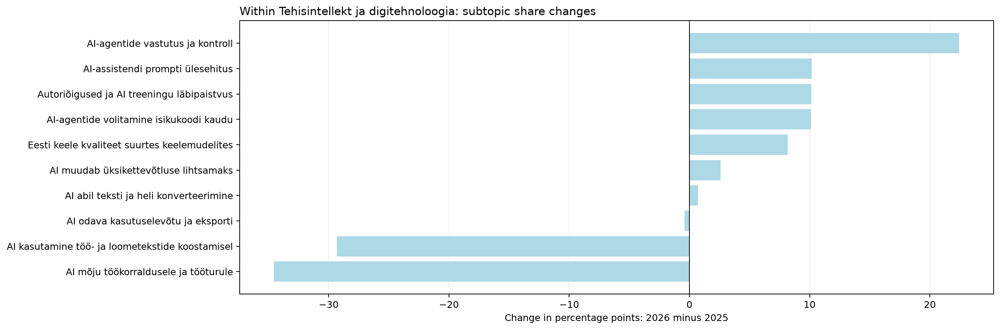

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
156,AI-agentide vastutus ja kontroll,2.21,189.67,1.0,9.0,0.02,2.07,2.05,3.03,25.48,22.44,both_years,False,True
10,AI-assistendi prompti ülesehitus,1.66,92.51,1.0,2.0,0.02,1.01,1.00,2.27,12.43,10.16,both_years,False,True
113,Autoriõigused ja AI treeningu läbipaistvus,0.00,75.37,0.0,3.0,0.00,0.82,0.82,0.00,10.12,10.12,only_observed_2026,False,True
7,AI-agentide volitamine isikukoodi kaudu,0.00,75.36,0.0,3.0,0.00,0.82,0.82,0.00,10.12,10.12,only_observed_2026,False,True
50,Eesti keele kvaliteet suurtes keelemudelites,0.00,60.74,0.0,4.0,0.00,0.66,0.66,0.00,8.16,8.16,only_observed_2026,False,True
235,AI muudab üksikettevõtluse lihtsamaks,2.69,46.73,1.0,4.0,0.03,0.51,0.48,3.68,6.28,2.59,both_years,False,True
171,AI abil teksti ja heli konverteerimine,0.00,5.39,0.0,1.0,0.00,0.06,0.06,0.00,0.72,0.72,only_observed_2026,False,False
121,AI odava kasutuselevõtu ja eksporti,3.33,30.86,1.0,2.0,0.03,0.34,0.30,4.57,4.15,-0.42,both_years,False,True
200,AI kasutamine töö- ja loometekstide koostamisel,22.79,14.28,4.0,4.0,0.23,0.16,-0.07,31.25,1.92,-29.33,both_years,True,True
187,AI mõju töökorraldusele ja tööturule,40.24,153.58,7.0,11.0,0.41,1.68,1.27,55.19,20.63,-34.56,both_years,True,True


## Within Laste ja noorte kaitse ning toetamine

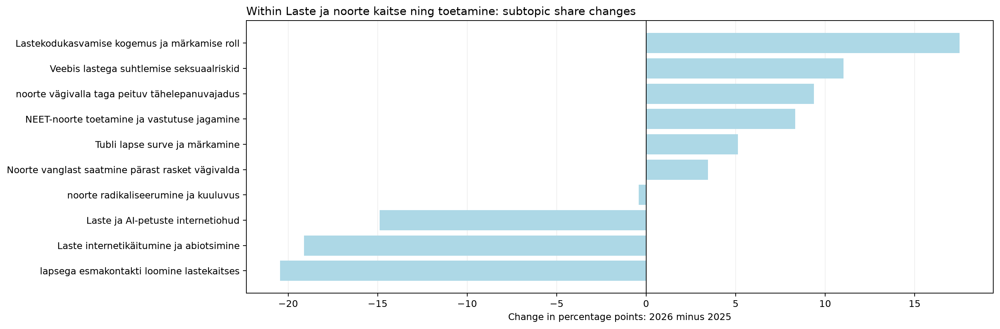

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
37,Lastekodukasvamise kogemus ja märkamise roll,14.89,110.47,1.0,3.0,0.15,1.21,1.06,6.40,23.90,17.50,both_years,False,True
96,Veebis lastega suhtlemise seksuaalriskid,16.27,83.27,3.0,1.0,0.16,0.91,0.75,6.99,18.02,11.03,both_years,True,False
184,noorte vägivalla taga peituv tähelepanuvajadus,0.00,43.38,0.0,1.0,0.00,0.47,0.47,0.00,9.38,9.38,only_observed_2026,False,False
67,NEET-noorte toetamine ja vastutuse jagamine,15.34,69.00,3.0,2.0,0.15,0.75,0.60,6.59,14.93,8.34,both_years,True,True
126,Tubli lapse surve ja märkamine,1.95,27.58,1.0,2.0,0.02,0.30,0.28,0.84,5.97,5.13,both_years,False,True
233,Noorte vanglast saatmine pärast rasket vägivalda,0.00,16.01,0.0,1.0,0.00,0.18,0.18,0.00,3.46,3.46,only_observed_2026,False,False
1,noorte radikaliseerumine ja kuuluvus,44.66,86.78,1.0,3.0,0.45,0.95,0.50,19.18,18.77,-0.41,both_years,False,True
77,Laste ja AI-petuste internetiohud,42.11,14.83,1.0,2.0,0.42,0.16,-0.26,18.09,3.21,-14.88,both_years,False,True
210,Laste internetikäitumine ja abiotsimine,47.19,5.34,4.0,1.0,0.48,0.06,-0.42,20.27,1.15,-19.12,both_years,True,False
130,lapsega esmakontakti loomine lastekaitses,50.41,5.58,1.0,2.0,0.51,0.06,-0.45,21.65,1.21,-20.44,both_years,False,False


## Within Kliima, rohepööre ja kestlik tarbimine

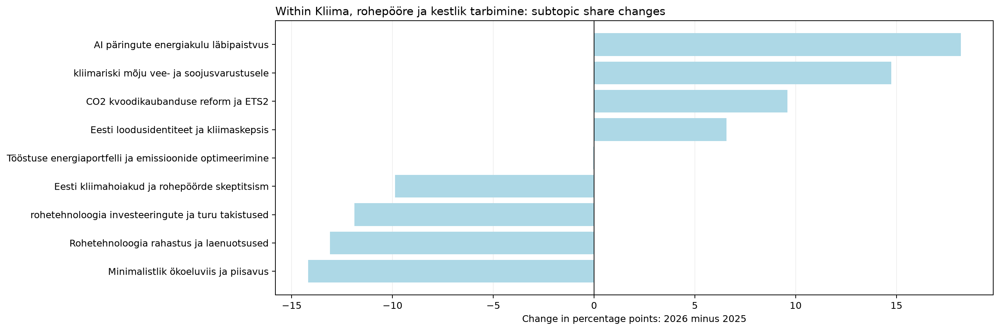

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
110,AI päringute energiakulu läbipaistvus,0.00,77.01,0.0,2.0,0.00,0.84,0.84,0.00,18.19,18.19,only_observed_2026,False,True
38,kliimariski mõju vee- ja soojusvarustusele,11.40,74.86,2.0,4.0,0.11,0.82,0.70,2.93,17.68,14.75,both_years,True,True
153,CO2 kvoodikaubanduse reform ja ETS2,23.94,66.67,4.0,3.0,0.24,0.73,0.49,6.15,15.75,9.60,both_years,True,True
177,Eesti loodusidentiteet ja kliimaskepsis,3.24,31.30,2.0,1.0,0.03,0.34,0.31,0.83,7.39,6.56,both_years,False,False
45,Tööstuse energiaportfelli ja emissioonide opti...,24.46,26.46,3.0,2.0,0.25,0.29,0.04,6.28,6.25,-0.03,both_years,True,True
25,Eesti kliimahoiakud ja rohepöörde skeptitsism,116.98,85.40,10.0,5.0,1.18,0.93,-0.24,30.05,20.17,-9.88,both_years,True,True
217,rohetehnoloogia investeeringute ja turu takist...,95.36,53.38,12.0,5.0,0.96,0.58,-0.38,24.50,12.61,-11.89,both_years,True,True
6,Rohetehnoloogia rahastus ja laenuotsused,54.14,3.44,4.0,1.0,0.55,0.04,-0.51,13.91,0.81,-13.10,both_years,True,False
145,Minimalistlik ökoeluviis ja piisavus,59.76,4.90,2.0,1.0,0.60,0.05,-0.55,15.35,1.16,-14.19,both_years,True,False


## Within Kultuur, loome ja pärand

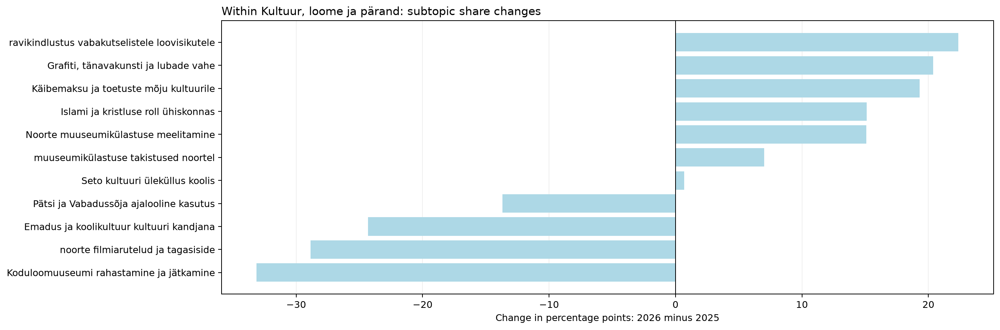

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
78,ravikindlustus vabakutselistele loovisikutele,0.00,86.47,0.0,2.0,0.00,0.95,0.95,0.00,22.38,22.38,only_observed_2026,False,True
87,"Grafiti, tänavakunsti ja lubade vahe",0.00,78.75,0.0,1.0,0.00,0.86,0.86,0.00,20.38,20.38,only_observed_2026,False,False
60,Käibemaksu ja toetuste mõju kultuurile,0.00,74.65,0.0,2.0,0.00,0.82,0.82,0.00,19.32,19.32,only_observed_2026,False,True
27,Islami ja kristluse roll ühiskonnas,0.00,58.45,0.0,1.0,0.00,0.64,0.64,0.00,15.13,15.13,only_observed_2026,False,False
206,Noorte muuseumikülastuse meelitamine,0.00,58.28,0.0,1.0,0.00,0.64,0.64,0.00,15.08,15.08,only_observed_2026,False,False
178,muuseumikülastuse takistused noortel,0.00,27.15,0.0,1.0,0.00,0.30,0.30,0.00,7.03,7.03,only_observed_2026,False,False
163,Seto kultuuri üleküllus koolis,0.00,2.65,0.0,1.0,0.00,0.03,0.03,0.00,0.69,0.69,only_observed_2026,False,False
166,Pätsi ja Vabadussõja ajalooline kasutus,28.23,0.00,1.0,0.0,0.28,0.00,-0.28,13.70,0.00,-13.70,only_observed_2025,False,False
165,Emadus ja koolikultuur kultuuri kandjana,50.12,0.00,2.0,0.0,0.51,0.00,-0.51,24.32,0.00,-24.32,only_observed_2025,True,False
127,noorte filmiarutelud ja tagasiside,59.49,0.00,1.0,0.0,0.60,0.00,-0.60,28.86,0.00,-28.86,only_observed_2025,False,False


## Within Küberturvalisus, privaatsus ja digiohud

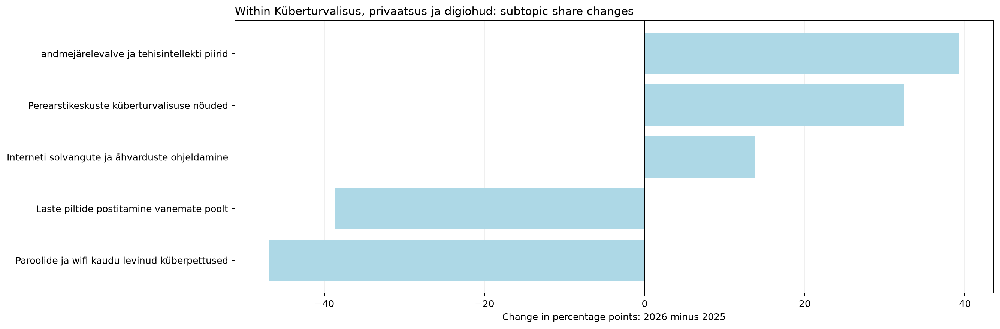

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
61,andmejärelevalve ja tehisintellekti piirid,12.45,113.04,3.0,9.0,0.13,1.24,1.11,9.02,48.26,39.24,both_years,True,True
111,Perearstikeskuste küberturvalisuse nõuded,0.00,75.98,0.0,1.0,0.00,0.83,0.83,0.00,32.44,32.44,only_observed_2026,False,False
155,Interneti solvangute ja ähvarduste ohjeldamine,7.58,45.21,2.0,1.0,0.08,0.49,0.42,5.49,19.30,13.82,both_years,False,False
42,Laste piltide postitamine vanemate poolt,53.33,0.00,1.0,0.0,0.54,0.00,-0.54,38.62,0.00,-38.62,only_observed_2025,False,False
64,Paroolide ja wifi kaudu levinud küberpettused,64.75,0.00,1.0,0.0,0.65,0.00,-0.65,46.88,0.00,-46.88,only_observed_2025,False,False


## Within Riigikaitse, julgeolek ja kriisivalmidus

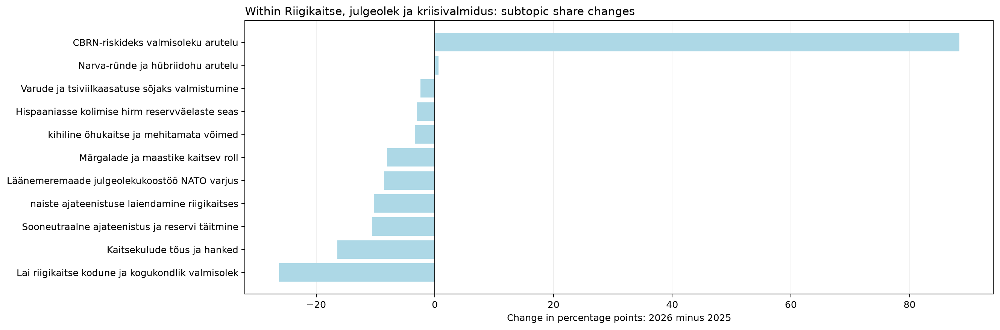

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
97,CBRN-riskideks valmisoleku arutelu,0.00,74.17,0.0,1.0,0.00,0.81,0.81,0.00,88.39,88.39,only_observed_2026,False,False
53,Narva-ründe ja hübriidohu arutelu,57.36,6.55,1.0,2.0,0.58,0.07,-0.51,7.19,7.81,0.62,both_years,False,False
81,Varude ja tsiviilkaasatuse sõjaks valmistumine,49.53,3.19,2.0,2.0,0.50,0.03,-0.46,6.21,3.80,-2.41,both_years,True,False
103,Hispaaniasse kolimise hirm reservväelaste seas,24.47,0.00,1.0,0.0,0.25,0.00,-0.25,3.07,0.00,-3.07,only_observed_2025,False,False
190,kihiline õhukaitse ja mehitamata võimed,26.86,0.00,2.0,0.0,0.27,0.00,-0.27,3.37,0.00,-3.37,only_observed_2025,True,False
92,Märgalade ja maastike kaitsev roll,64.47,0.00,1.0,0.0,0.65,0.00,-0.65,8.08,0.00,-8.08,only_observed_2025,False,False
30,Läänemeremaade julgeolekukoostöö NATO varjus,68.18,0.00,2.0,0.0,0.69,0.00,-0.69,8.54,0.00,-8.54,only_observed_2025,True,False
101,naiste ajateenistuse laiendamine riigikaitses,81.80,0.00,3.0,0.0,0.82,0.00,-0.82,10.25,0.00,-10.25,only_observed_2025,True,False
107,Sooneutraalne ajateenistus ja reservi täitmine,84.60,0.00,4.0,0.0,0.85,0.00,-0.85,10.60,0.00,-10.60,only_observed_2025,True,False
84,Kaitsekulude tõus ja hanked,131.11,0.00,7.0,0.0,1.32,0.00,-1.32,16.43,0.00,-16.43,only_observed_2025,True,False


## Within Majandus, ettevõtlus ja innovatsioon

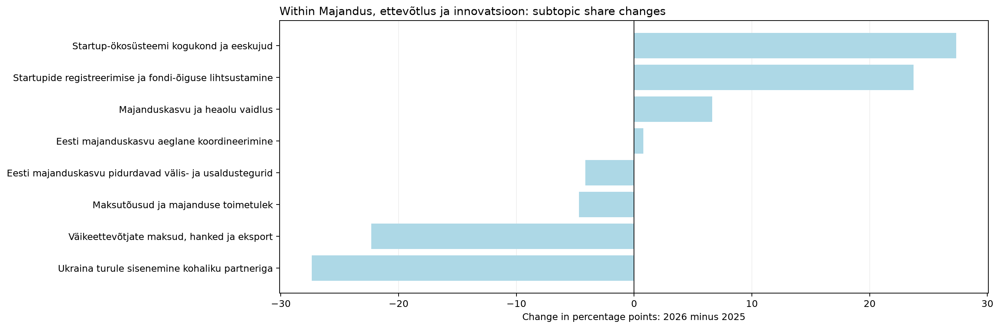

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
158,Startup-ökosüsteemi kogukond ja eeskujud,9.21,74.62,2.0,3.0,0.09,0.82,0.72,2.92,30.26,27.35,both_years,False,True
124,Startupide registreerimise ja fondi-õiguse lih...,0.00,58.54,0.0,2.0,0.00,0.64,0.64,0.00,23.74,23.74,only_observed_2026,False,True
170,Majanduskasvu ja heaolu vaidlus,52.27,57.22,9.0,3.0,0.53,0.63,0.10,16.56,23.21,6.64,both_years,True,True
202,Eesti majanduskasvu aeglane koordineerimine,34.54,28.94,2.0,1.0,0.35,0.32,-0.03,10.94,11.74,0.79,both_years,True,False
231,Eesti majanduskasvu pidurdavad välis- ja usald...,15.74,2.10,3.0,1.0,0.16,0.02,-0.14,4.99,0.85,-4.14,both_years,True,False
175,Maksutõusud ja majanduse toimetulek,42.77,21.89,2.0,4.0,0.43,0.24,-0.19,13.55,8.88,-4.67,both_years,True,True
143,"Väikeettevõtjate maksud, hanked ja eksport",74.66,3.26,5.0,2.0,0.75,0.04,-0.72,23.66,1.32,-22.33,both_years,True,False
23,Ukraina turule sisenemine kohaliku partneriga,86.43,0.00,3.0,0.0,0.87,0.00,-0.87,27.38,0.00,-27.38,only_observed_2025,True,False


## Within Haridus, õppimine ja oskused

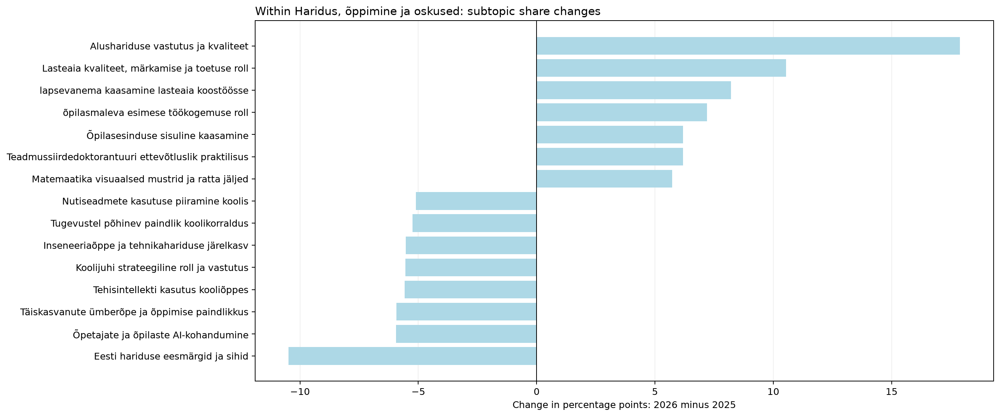

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
173,Alushariduse vastutus ja kvaliteet,0.00,207.08,0.0,7.0,0.00,2.27,2.27,0.00,17.89,17.89,only_observed_2026,False,True
5,"Lasteaia kvaliteet, märkamise ja toetuse roll",2.70,124.38,1.0,6.0,0.03,1.36,1.33,0.20,10.74,10.54,both_years,False,True
16,lapsevanema kaasamine lasteaia koostöösse,0.00,95.00,0.0,3.0,0.00,1.04,1.04,0.00,8.20,8.20,only_observed_2026,False,True
24,õpilasmaleva esimese töökogemuse roll,10.36,92.15,1.0,2.0,0.10,1.01,0.90,0.77,7.96,7.19,both_years,False,True
136,Õpilasesinduse sisuline kaasamine,0.00,71.63,0.0,1.0,0.00,0.78,0.78,0.00,6.19,6.19,only_observed_2026,False,False
26,Teadmussiirdedoktorantuuri ettevõtluslik prakt...,16.40,85.67,2.0,2.0,0.17,0.94,0.77,1.21,7.40,6.19,both_years,True,True
176,Matemaatika visuaalsed mustrid ja ratta jäljed,1.62,67.76,1.0,2.0,0.02,0.74,0.72,0.12,5.85,5.73,both_years,False,True
181,Õpetaja hoituse rollid alushariduses,0.00,51.70,0.0,1.0,0.00,0.57,0.57,0.00,4.47,4.47,only_observed_2026,False,False
89,AI kasutamise reeglid ja hindamine ülikoolis,0.00,39.77,0.0,1.0,0.00,0.44,0.44,0.00,3.44,3.44,only_observed_2026,False,False
108,Fookuse hoidmise liikumismängud,0.00,39.54,0.0,1.0,0.00,0.43,0.43,0.00,3.42,3.42,only_observed_2026,False,False


## Within Energeetika ja energiaturud

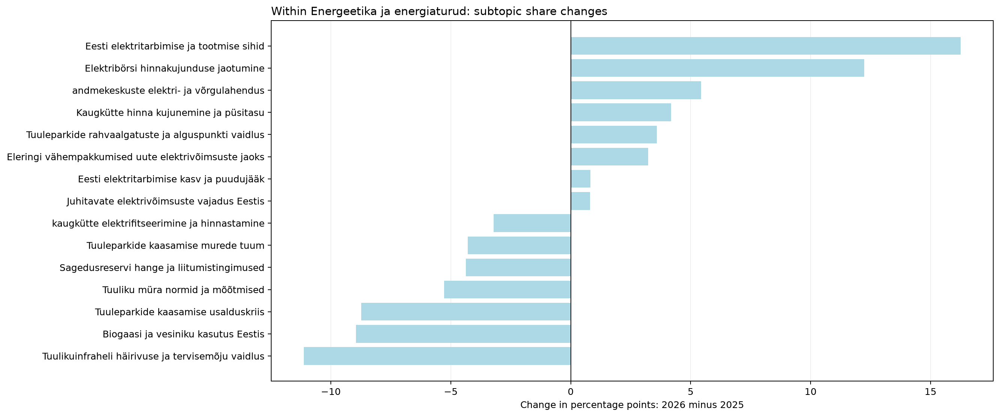

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
133,Eesti elektritarbimise ja tootmise sihid,26.45,118.64,4.0,7.0,0.27,1.30,1.03,4.52,20.77,16.25,both_years,True,True
128,Elektribörsi hinnakujunduse jaotumine,4.79,74.51,1.0,3.0,0.05,0.82,0.77,0.82,13.05,12.23,both_years,False,True
195,andmekeskuste elektri- ja võrgulahendus,0.00,31.06,0.0,3.0,0.00,0.34,0.34,0.00,5.44,5.44,only_observed_2026,False,True
118,Kaugkütte hinna kujunemine ja püsitasu,16.31,39.82,1.0,1.0,0.16,0.44,0.27,2.79,6.97,4.18,both_years,False,False
236,Tuuleparkide rahvaalgatuste ja alguspunkti vai...,0.00,20.46,0.0,1.0,0.00,0.22,0.22,0.00,3.58,3.58,only_observed_2026,False,False
224,Eleringi vähempakkumised uute elektrivõimsuste...,3.84,22.16,1.0,3.0,0.04,0.24,0.20,0.66,3.88,3.22,both_years,False,True
182,Eesti elektritarbimise kasv ja puudujääk,12.01,16.39,2.0,3.0,0.12,0.18,0.06,2.05,2.87,0.82,both_years,True,True
161,Juhitavate elektrivõimsuste vajadus Eestis,101.73,103.98,3.0,4.0,1.03,1.14,0.11,17.40,18.21,0.81,both_years,True,True
157,Meretuuleparkide arendamise kindlustamine,14.19,10.61,1.0,1.0,0.14,0.12,-0.03,2.43,1.86,-0.57,both_years,False,False
213,kaugkütte elektrifitseerimine ja hinnastamine,55.69,36.03,2.0,2.0,0.56,0.39,-0.17,9.53,6.31,-3.22,both_years,True,True


## Within Pere, suhted ja sooline võrdsus

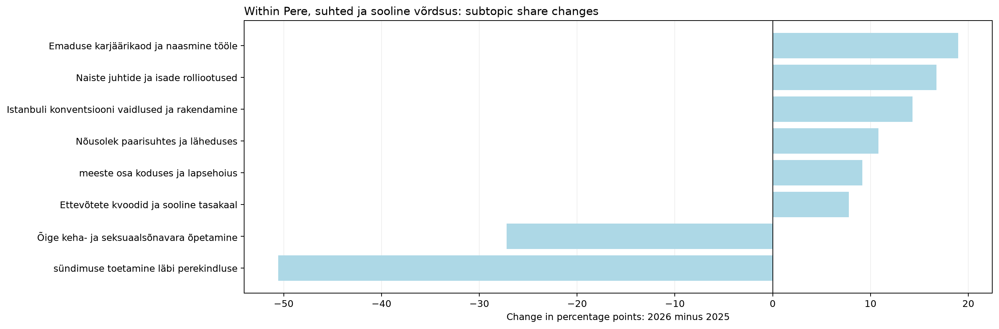

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
14,Emaduse karjäärikaod ja naasmine tööle,2.64,88.32,1.0,3.0,0.03,0.97,0.94,1.47,20.45,18.98,both_years,False,True
151,Naiste juhtide ja isade rolliootused,1.60,76.21,1.0,3.0,0.02,0.83,0.82,0.89,17.64,16.75,both_years,False,True
55,Istanbuli konventsiooni vaidlused ja rakendamine,11.41,89.12,1.0,1.0,0.12,0.97,0.86,6.35,20.63,14.28,both_years,False,False
11,Nõusolek paarisuhtes ja läheduses,15.70,84.48,1.0,1.0,0.16,0.92,0.77,8.74,19.56,10.81,both_years,False,False
186,meeste osa koduses ja lapsehoius,6.52,55.25,1.0,2.0,0.07,0.60,0.54,3.63,12.79,9.16,both_years,False,True
174,Ettevõtete kvoodid ja sooline tasakaal,0.00,33.67,0.0,2.0,0.00,0.37,0.37,0.00,7.80,7.80,only_observed_2026,False,True
41,Õige keha- ja seksuaalsõnavara õpetamine,49.54,1.63,1.0,1.0,0.50,0.02,-0.48,27.58,0.38,-27.20,both_years,False,False
13,sündimuse toetamine läbi perekindluse,92.18,3.26,2.0,1.0,0.93,0.04,-0.89,51.33,0.76,-50.57,both_years,True,False


## Within Toit, põllumajandus ja toidujulgeolek

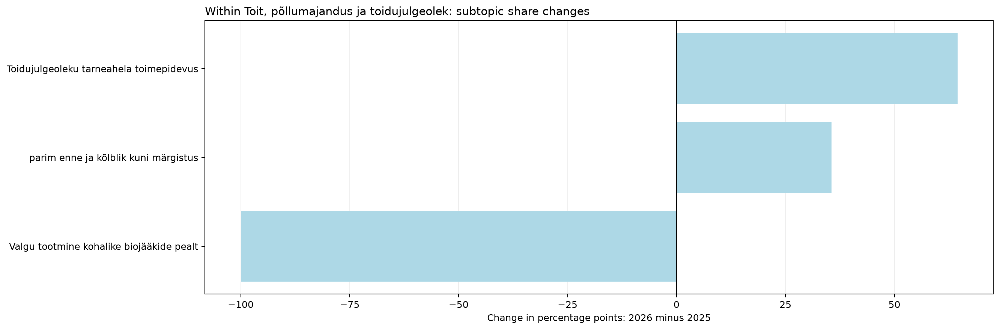

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
49,Toidujulgeoleku tarneahela toimepidevus,0.00,96.51,0.0,4.0,0.00,1.06,1.06,0.0,64.47,64.47,only_observed_2026,False,True
52,parim enne ja kõlblik kuni märgistus,0.00,53.19,0.0,1.0,0.00,0.58,0.58,0.0,35.53,35.53,only_observed_2026,False,False
223,Valgu tootmine kohalike biojääkide pealt,22.76,0.00,2.0,0.0,0.23,0.00,-0.23,100.0,0.00,-100.00,only_observed_2025,True,False


## Within Riigijuhtimine, kodanikuühiskond ja õigus

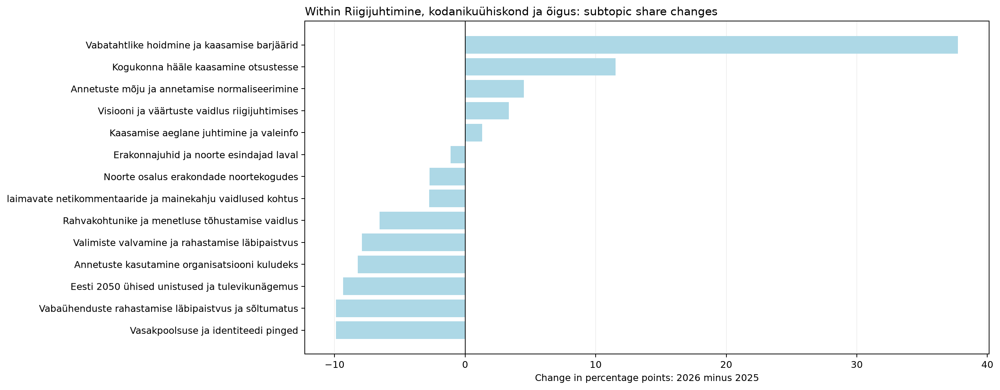

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
160,Vabatahtlike hoidmine ja kaasamise barjäärid,7.18,62.62,2.0,1.0,0.07,0.68,0.61,0.77,38.53,37.76,both_years,False,False
34,Kogukonna hääle kaasamine otsustesse,59.20,29.05,8.0,5.0,0.60,0.32,-0.28,6.35,17.87,11.52,both_years,True,True
129,Annetuste mõju ja annetamise normaliseerimine,101.08,24.93,3.0,3.0,1.02,0.27,-0.75,10.84,15.34,4.49,both_years,True,True
119,Visiooni ja väärtuste vaidlus riigijuhtimises,97.89,22.50,8.0,4.0,0.99,0.25,-0.74,10.50,13.84,3.34,both_years,True,True
234,Kaasamise aeglane juhtimine ja valeinfo,28.32,7.04,2.0,1.0,0.29,0.08,-0.21,3.04,4.33,1.29,both_years,True,False
218,Erakonnajuhid ja noorte esindajad laval,19.71,1.62,3.0,1.0,0.20,0.02,-0.18,2.11,1.00,-1.12,both_years,True,False
148,Noorte osalus erakondade noortekogudes,25.55,0.00,2.0,0.0,0.26,0.00,-0.26,2.74,0.00,-2.74,only_observed_2025,True,False
47,laimavate netikommentaaride ja mainekahju vaid...,91.16,11.41,1.0,1.0,0.92,0.12,-0.79,9.78,7.02,-2.76,both_years,False,False
36,Rahvakohtunike ja menetluse tõhustamise vaidlus,61.00,0.00,1.0,0.0,0.61,0.00,-0.61,6.54,0.00,-6.54,only_observed_2025,False,False
32,Valimiste valvamine ja rahastamise läbipaistvus,73.62,0.00,2.0,0.0,0.74,0.00,-0.74,7.90,0.00,-7.90,only_observed_2025,True,False


## Within Tervishoid, ravi ja terviseandmed

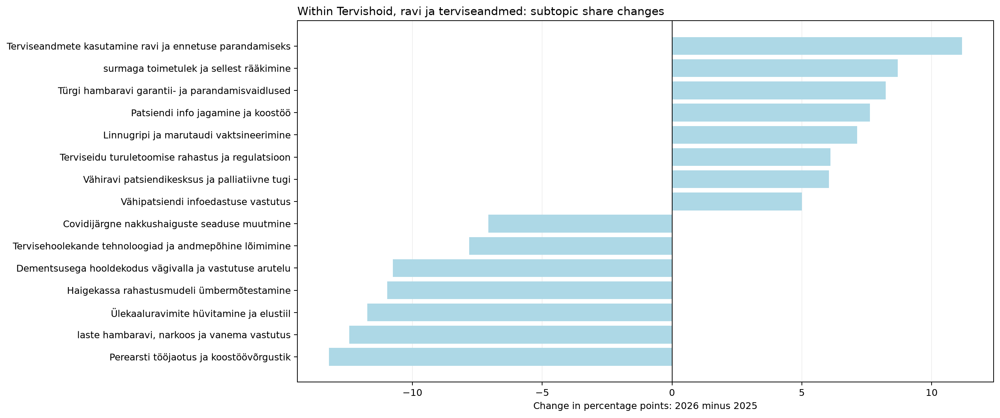

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
205,Terviseandmete kasutamine ravi ja ennetuse par...,8.76,122.28,2.0,4.0,0.09,1.34,1.25,1.29,12.46,11.16,both_years,False,True
85,surmaga toimetulek ja sellest rääkimine,6.21,94.31,1.0,3.0,0.06,1.03,0.97,0.91,9.61,8.69,both_years,False,True
59,Türgi hambaravi garantii- ja parandamisvaidlused,0.00,80.82,0.0,1.0,0.00,0.88,0.88,0.00,8.23,8.23,only_observed_2026,False,False
116,Patsiendi info jagamine ja koostöö,37.20,128.64,4.0,5.0,0.37,1.41,1.03,5.48,13.10,7.62,both_years,True,True
106,Linnugripi ja marutaudi vaktsineerimine,0.00,70.06,0.0,1.0,0.00,0.77,0.77,0.00,7.14,7.14,only_observed_2026,False,False
144,Terviseidu turuletoomise rahastus ja regulatsioon,13.68,79.73,2.0,3.0,0.14,0.87,0.73,2.02,8.12,6.11,both_years,True,True
3,Vähiravi patsiendikesksus ja palliatiivne tugi,16.00,82.55,1.0,4.0,0.16,0.90,0.74,2.36,8.41,6.05,both_years,False,True
154,Vähipatsiendi infoedastuse vastutus,3.18,53.75,1.0,2.0,0.03,0.59,0.56,0.47,5.47,5.01,both_years,False,True
138,AI roll arstide suhtluses ja vähiravis,7.53,58.14,1.0,3.0,0.08,0.64,0.56,1.11,5.92,4.81,both_years,False,True
152,Tervishoiu konkurentsi tasakaal,14.30,58.48,2.0,2.0,0.14,0.64,0.50,2.11,5.96,3.85,both_years,True,True


## Within Rahvusvahelised suhted, Euroopa Liit ja humanitaarabi

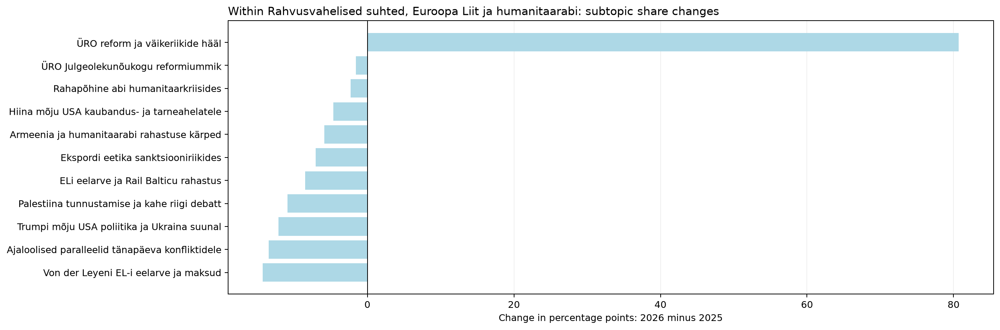

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
131,ÜRO reform ja väikeriikide hääl,72.66,77.64,4.0,1.0,0.73,0.85,0.12,11.64,92.35,80.71,both_years,True,False
229,ÜRO Julgeolekunõukogu reformiummik,9.86,0.00,1.0,0.0,0.10,0.00,-0.10,1.58,0.00,-1.58,only_observed_2025,False,False
193,Rahapõhine abi humanitaarkriisides,14.19,0.00,1.0,0.0,0.14,0.00,-0.14,2.27,0.00,-2.27,only_observed_2025,False,False
204,Hiina mõju USA kaubandus- ja tarneahelatele,41.23,1.63,4.0,1.0,0.42,0.02,-0.40,6.61,1.94,-4.67,both_years,True,False
98,Armeenia ja humanitaarabi rahastuse kärped,36.58,0.00,1.0,0.0,0.37,0.00,-0.37,5.86,0.00,-5.86,only_observed_2025,False,False
162,Ekspordi eetika sanktsiooniriikides,44.03,0.00,1.0,0.0,0.44,0.00,-0.44,7.06,0.00,-7.06,only_observed_2025,False,False
82,ELi eelarve ja Rail Balticu rahastus,52.90,0.00,1.0,0.0,0.53,0.00,-0.53,8.48,0.00,-8.48,only_observed_2025,False,False
9,Palestiina tunnustamise ja kahe riigi debatt,67.90,0.00,2.0,0.0,0.68,0.00,-0.68,10.88,0.00,-10.88,only_observed_2025,True,False
105,Trumpi mõju USA poliitika ja Ukraina suunal,111.43,4.80,5.0,1.0,1.12,0.05,-1.07,17.86,5.71,-12.14,both_years,True,False
198,Ajaloolised paralleelid tänapäeva konfliktidele,84.13,0.00,5.0,0.0,0.85,0.00,-0.85,13.48,0.00,-13.48,only_observed_2025,True,False


## Within Meedia, avalik arutelu ja infokvaliteet

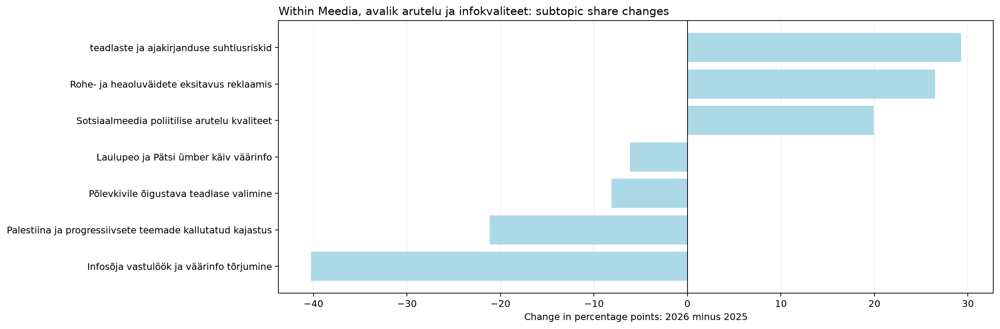

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
20,teadlaste ja ajakirjanduse suhtlusriskid,0.00,84.56,0.0,2.0,0.00,0.92,0.92,0.00,29.25,29.25,only_observed_2026,False,True
114,Rohe- ja heaolu­väidete eksitavus reklaamis,2.85,80.34,1.0,1.0,0.03,0.88,0.85,1.29,27.79,26.50,both_years,False,False
115,Sotsiaalmeedia poliitilise arutelu kvaliteet,20.30,84.07,4.0,2.0,0.20,0.92,0.72,9.17,29.08,19.92,both_years,True,True
216,Laulupeo ja Pätsi ümber käiv väärinfo,13.60,0.00,1.0,0.0,0.14,0.00,-0.14,6.14,0.00,-6.14,only_observed_2025,False,False
228,Põlevkivile õigustava teadlase valimine,18.02,0.00,1.0,0.0,0.18,0.00,-0.18,8.13,0.00,-8.13,only_observed_2025,False,False
220,Palestiina ja progressiivsete teemade kallutat...,46.82,0.00,2.0,0.0,0.47,0.00,-0.47,21.14,0.00,-21.14,only_observed_2025,True,False
149,Infosõja vastulöök ja väärinfo tõrjumine,119.89,40.12,5.0,5.0,1.21,0.44,-0.77,54.13,13.88,-40.26,both_years,True,True


## Within Ränne, lõimumine ja kuuluvus

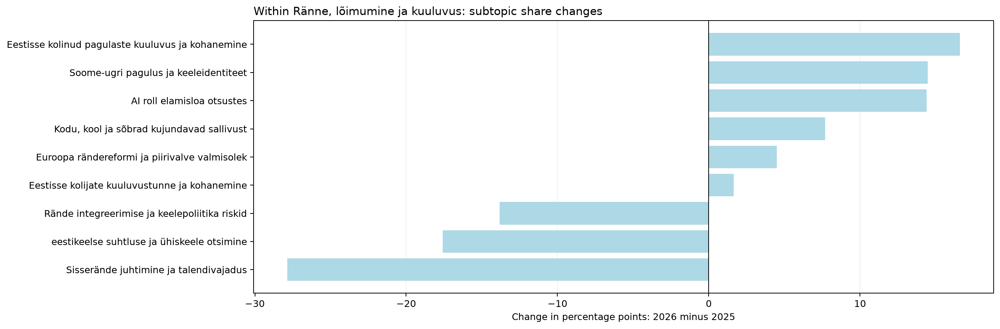

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
122,Eestisse kolinud pagulaste kuuluvus ja kohanemine,0.00,77.83,0.0,2.0,0.00,0.85,0.85,0.00,16.60,16.60,only_observed_2026,False,True
93,Soome-ugri pagulus ja keeleidentiteet,0.00,67.87,0.0,1.0,0.00,0.74,0.74,0.00,14.47,14.47,only_observed_2026,False,False
66,AI roll elamisloa otsustes,0.00,67.53,0.0,1.0,0.00,0.74,0.74,0.00,14.40,14.40,only_observed_2026,False,False
80,"Kodu, kool ja sõbrad kujundavad sallivust",22.21,83.15,2.0,4.0,0.22,0.91,0.69,10.05,17.73,7.68,both_years,True,True
207,Euroopa rändereformi ja piirivalve valmisolek,0.00,21.08,0.0,2.0,0.00,0.23,0.23,0.00,4.50,4.50,only_observed_2026,False,True
94,Eestisse kolijate kuuluvustunne ja kohanemine,31.44,74.41,2.0,6.0,0.32,0.81,0.50,14.22,15.87,1.65,both_years,True,True
134,Rände integreerimise ja keelepoliitika riskid,63.55,69.97,2.0,3.0,0.64,0.77,0.12,28.76,14.92,-13.83,both_years,True,True
75,eestikeelse suhtluse ja ühiskeele otsimine,40.71,3.85,4.0,1.0,0.41,0.04,-0.37,18.42,0.82,-17.60,both_years,True,False
188,Sisserände juhtimine ja talendivajadus,63.10,3.21,4.0,1.0,0.64,0.04,-0.60,28.55,0.69,-27.86,both_years,True,False


## Within Loodus, metsandus ja maavarad

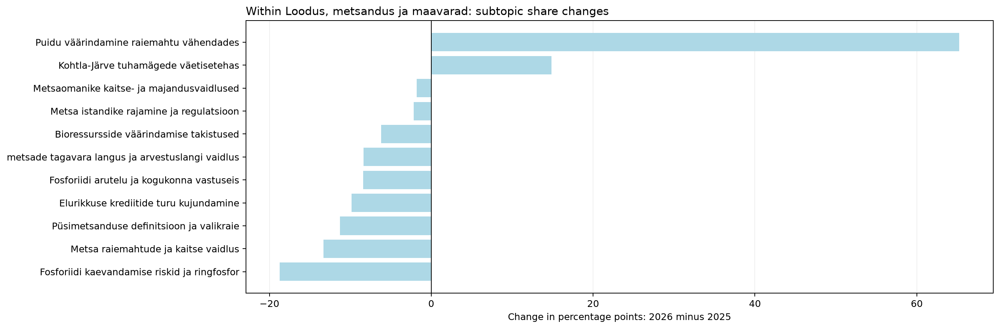

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
167,Puidu väärindamine raiemahtu vähendades,65.29,25.63,5.0,3.0,0.66,0.28,-0.38,8.35,73.61,65.26,both_years,True,True
70,Kohtla-Järve tuhamägede väetisetehas,6.06,5.44,1.0,1.0,0.06,0.06,-0.00,0.77,15.62,14.84,both_years,False,False
73,Metsaomanike kaitse- ja majandusvaidlused,98.17,3.75,4.0,1.0,0.99,0.04,-0.95,12.56,10.77,-1.78,both_years,True,False
222,Metsa istandike rajamine ja regulatsioon,16.95,0.00,1.0,0.0,0.17,0.00,-0.17,2.17,0.00,-2.17,only_observed_2025,False,False
221,Bioressursside väärindamise takistused,48.50,0.00,1.0,0.0,0.49,0.00,-0.49,6.20,0.00,-6.20,only_observed_2025,False,False
168,metsade tagavara langus ja arvestuslangi vaidlus,65.57,0.00,2.0,0.0,0.66,0.00,-0.66,8.39,0.00,-8.39,only_observed_2025,True,False
232,Fosforiidi arutelu ja kogukonna vastuseis,65.81,0.00,4.0,0.0,0.66,0.00,-0.66,8.42,0.00,-8.42,only_observed_2025,True,False
62,Elurikkuse krediitide turu kujundamine,76.84,0.00,1.0,0.0,0.77,0.00,-0.77,9.83,0.00,-9.83,only_observed_2025,False,False
56,Püsimetsanduse definitsioon ja valikraie,88.16,0.00,1.0,0.0,0.89,0.00,-0.89,11.28,0.00,-11.28,only_observed_2025,False,False
201,Metsa raiemahtude ja kaitse vaidlus,104.10,0.00,6.0,0.0,1.05,0.00,-1.05,13.32,0.00,-13.32,only_observed_2025,True,False


## Within Eluase, ruum ja ühendused

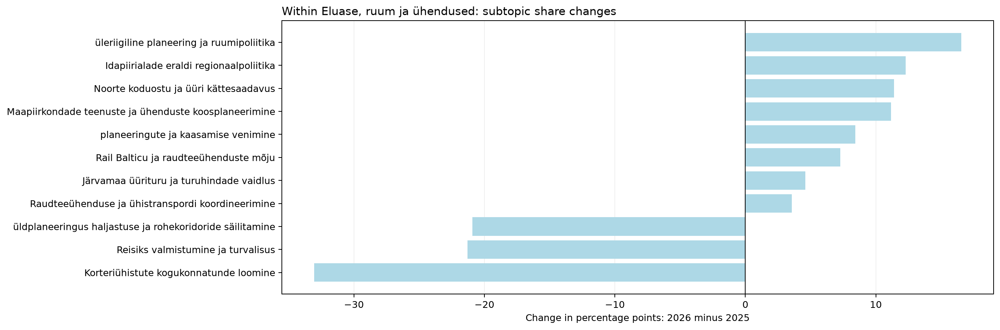

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
104,üleriigiline planeering ja ruumipoliitika,17.97,129.92,2.0,4.0,0.18,1.42,1.24,6.85,23.39,16.54,both_years,True,True
43,Idapiirialade eraldi regionaalpoliitika,3.31,75.28,1.0,1.0,0.03,0.82,0.79,1.26,13.55,12.29,both_years,False,False
57,Noorte koduostu ja üüri kättesaadavus,4.98,73.80,1.0,3.0,0.05,0.81,0.76,1.90,13.29,11.39,both_years,False,True
137,Maapiirkondade teenuste ja ühenduste koosplane...,11.44,86.22,2.0,5.0,0.12,0.94,0.83,4.36,15.52,11.16,both_years,True,True
95,planeeringute ja kaasamise venimine,14.13,76.79,1.0,6.0,0.14,0.84,0.70,5.39,13.82,8.44,both_years,False,True
63,Rail Balticu ja raudteeühenduste mõju,10.41,62.50,1.0,3.0,0.10,0.68,0.58,3.97,11.25,7.28,both_years,False,True
211,Järvamaa üürituru ja turuhindade vaidlus,0.00,25.45,0.0,1.0,0.00,0.28,0.28,0.00,4.58,4.58,only_observed_2026,False,False
194,Raudteeühenduse ja ühistranspordi koordineerimine,2.68,25.48,1.0,2.0,0.03,0.28,0.25,1.02,4.59,3.56,both_years,False,True
141,üldplaneeringus haljastuse ja rohekoridoride s...,54.86,0.00,1.0,0.0,0.55,0.00,-0.55,20.91,0.00,-20.91,only_observed_2025,False,False
28,Reisiks valmistumine ja turvalisus,55.83,0.00,1.0,0.0,0.56,0.00,-0.56,21.28,0.00,-21.28,only_observed_2025,False,False


## Within Vaimne tervis, tervisekäitumine ja ennetus

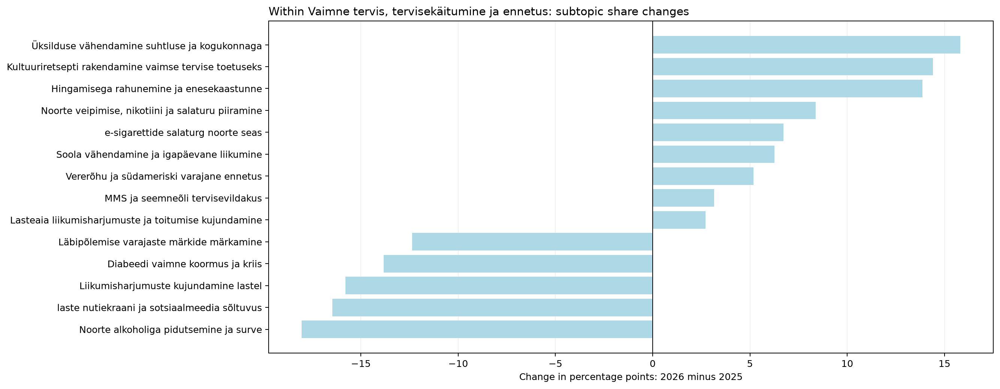

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
15,Üksilduse vähendamine suhtluse ja kogukonnaga,6.62,92.49,3.0,2.0,0.07,1.01,0.95,1.45,17.27,15.82,both_years,False,True
109,Kultuuriretsepti rakendamine vaimse tervise to...,0.00,77.15,0.0,1.0,0.00,0.84,0.84,0.00,14.40,14.40,only_observed_2026,False,False
100,Hingamisega rahunemine ja enesekaastunne,0.00,74.29,0.0,2.0,0.00,0.81,0.81,0.00,13.87,13.87,only_observed_2026,False,True
185,"Noorte veipimise, nikotiini ja salaturu piiramine",1.58,46.74,1.0,1.0,0.02,0.51,0.50,0.35,8.73,8.38,both_years,False,False
159,e-sigarettide salaturg noorte seas,0.00,35.96,0.0,1.0,0.00,0.39,0.39,0.00,6.71,6.71,only_observed_2026,False,False
192,Soola vähendamine ja igapäevane liikumine,13.53,49.40,1.0,3.0,0.14,0.54,0.40,2.96,9.22,6.26,both_years,False,True
33,Vererõhu ja südameriski varajane ennetus,8.13,37.30,1.0,3.0,0.08,0.41,0.33,1.78,6.96,5.19,both_years,False,True
208,MMS ja seemneõli tervisevildakus,7.17,25.32,1.0,2.0,0.07,0.28,0.20,1.57,4.73,3.16,both_years,False,True
197,Lasteaia liikumisharjumuste ja toitumise kujun...,0.00,14.59,0.0,1.0,0.00,0.16,0.16,0.00,2.72,2.72,only_observed_2026,False,False
164,Läbipõlemise varajaste märkide märkamine,73.99,20.37,5.0,3.0,0.75,0.22,-0.52,16.18,3.80,-12.37,both_years,True,True


## Within Tööelu, juhtimine ja töötajate õigused

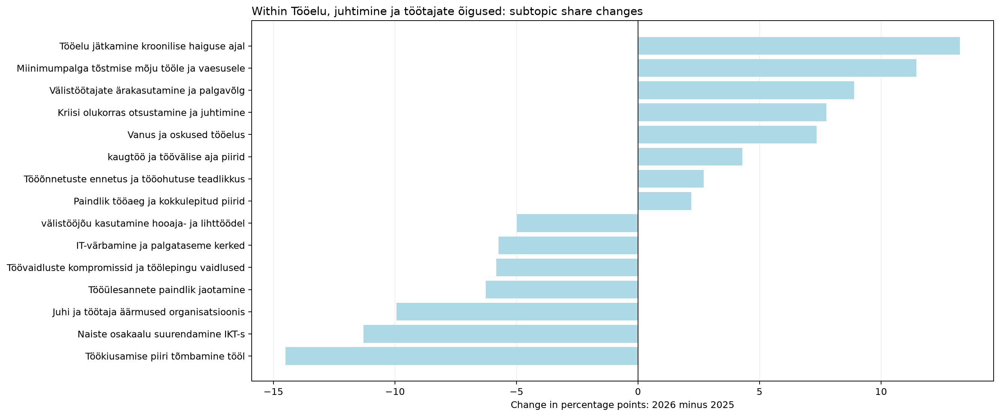

,jev_topic_name,minutes_2025,minutes_2026,talks_2025,talks_2026,time_share_2025,time_share_2026,time_share_delta_pp,within_parent_share_2025,within_parent_share_2026,within_parent_delta_pp,status,supported_2025,supported_2026
22,Tööelu jätkamine kroonilise haiguse ajal,0.00,84.34,0.0,1.0,0.00,0.92,0.92,0.00,13.24,13.24,only_observed_2026,False,False
72,Miinimumpalga tõstmise mõju tööle ja vaesusele,3.92,76.30,1.0,2.0,0.04,0.83,0.79,0.52,11.98,11.45,both_years,False,True
44,Välistöötajate ärakasutamine ja palgavõlg,0.00,56.62,0.0,1.0,0.00,0.62,0.62,0.00,8.89,8.89,only_observed_2026,False,False
139,Kriisi olukorras otsustamine ja juhtimine,13.56,60.89,4.0,3.0,0.14,0.67,0.53,1.81,9.56,7.75,both_years,True,True
83,Vanus ja oskused tööelus,37.92,79.08,4.0,3.0,0.38,0.86,0.48,5.07,12.42,7.34,both_years,True,True
91,kaugtöö ja töövälise aja piirid,12.15,37.70,2.0,3.0,0.12,0.41,0.29,1.63,5.92,4.29,both_years,True,True
2,Tööõnnetuste ennetus ja tööohutuse teadlikkus,85.02,89.61,1.0,1.0,0.86,0.98,0.12,11.37,14.07,2.70,both_years,False,False
169,Paindlik tööaeg ja kokkulepitud piirid,45.61,52.86,4.0,2.0,0.46,0.58,0.12,6.10,8.30,2.20,both_years,True,True
19,Töökiusu ja vaidluste piiritlemine töösuhtes,61.37,56.61,3.0,2.0,0.62,0.62,0.00,8.21,8.89,0.68,both_years,True,True
215,välistööjõu kasutamine hooaja- ja lihttöödel,45.37,6.93,1.0,1.0,0.46,0.08,-0.38,6.07,1.09,-4.98,both_years,False,False


In [11]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
comparison_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
comparison = comparison_root / "data/topic-analysis/results/jev-topic-analysis/year-comparison"
display(Markdown((comparison / "COMPARISON.md").read_text(encoding="utf-8")))
for chart in ["main-time-share-changes", "main-talk-coverage-changes", "detailed-time-share-changes"]:
    display(Image(filename=str(comparison / (chart + ".png"))))
for label, file in [("Topics only observed in 2026 — complete list", "only-observed-2026.csv"),
                    ("Topics only observed in 2025 — complete list", "only-observed-2025.csv")]:
    display(Markdown("## " + label))
    display(pd.read_csv(comparison / file).round(2))
subtopics = pd.read_csv(comparison / "detailed-topic-changes.csv")
for category, group in subtopics.query("jev_topic_id != -1").groupby("jev_high_level_id"):
    display(Markdown("## Within " + group.jev_high_level_name.iloc[0]))
    display(Image(filename=str(comparison / ("subtopics-" + category + ".png"))))
    display(group.sort_values("within_parent_delta_pp", ascending=False)[
        ["jev_topic_name", "minutes_2025", "minutes_2026", "talks_2025", "talks_2026",
         "time_share_2025", "time_share_2026", "time_share_delta_pp",
         "within_parent_share_2025", "within_parent_share_2026", "within_parent_delta_pp",
         "status", "supported_2025", "supported_2026"]].round(2))


## Individual semantic segments in 2D

Each equal-sized point is **one native semantic segment**, not a topic centroid. Color shows the high-level category mapped from the segment's Jev primary topic; gray points are unassigned. The combined view has 4,132 points; the 2025 and 2026 views have 2,154 and 1,978. All three share coordinates and axes, allowing comparison without separately fitting each year.

Positions come from one UMAP projection of the saved 1,024-dimensional BGE **segment embeddings**, with cosine distance, 15 neighbors, minimum distance 0.15 and seed 42. Topic labels are only used for color, not as projection inputs. Nearby points can have similar text, but 2D distances and apparent clusters are approximate and are not a new clustering result.

The interactive plots support zooming, category filtering via the legend and hover with talk title, year, timestamps, detailed topic and a text excerpt. Static PNGs are embedded immediately below each interactive view. Regenerate with `uv run --group topic-analysis python scripts/export_jev_segment_maps.py`; it reuses cached vectors and projection coordinates without classifier API calls.

### Combined: 4,132 segments

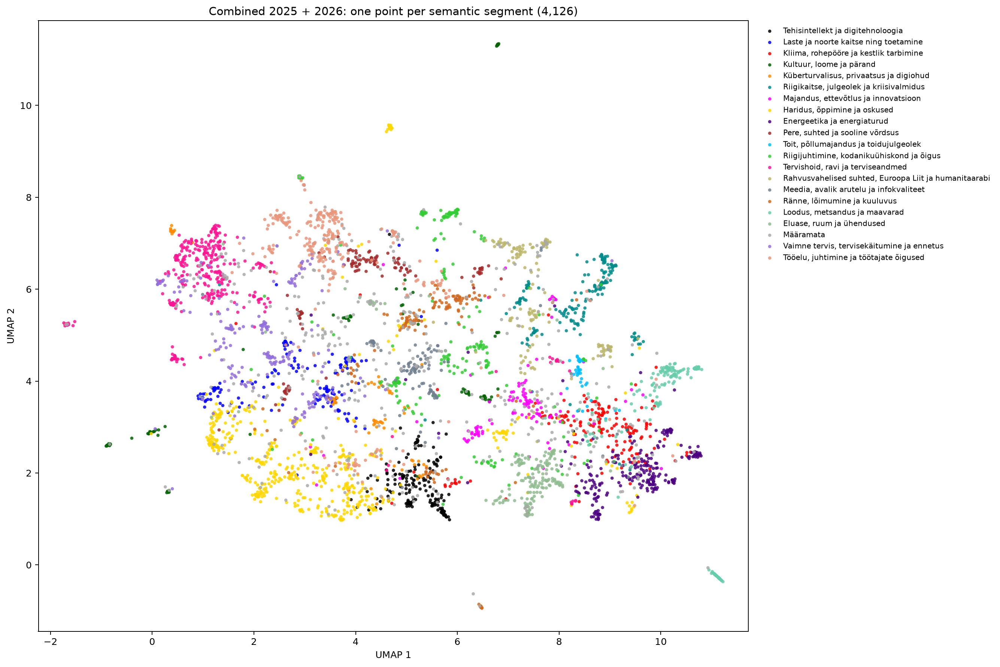

### 2025: 2,154 segments

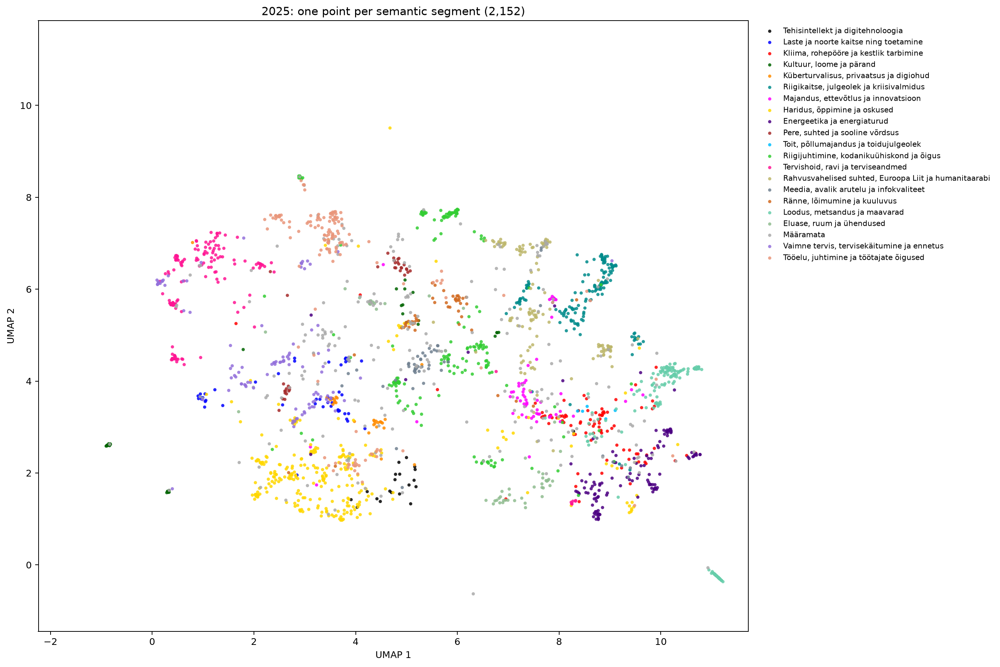

### 2026: 1,978 segments

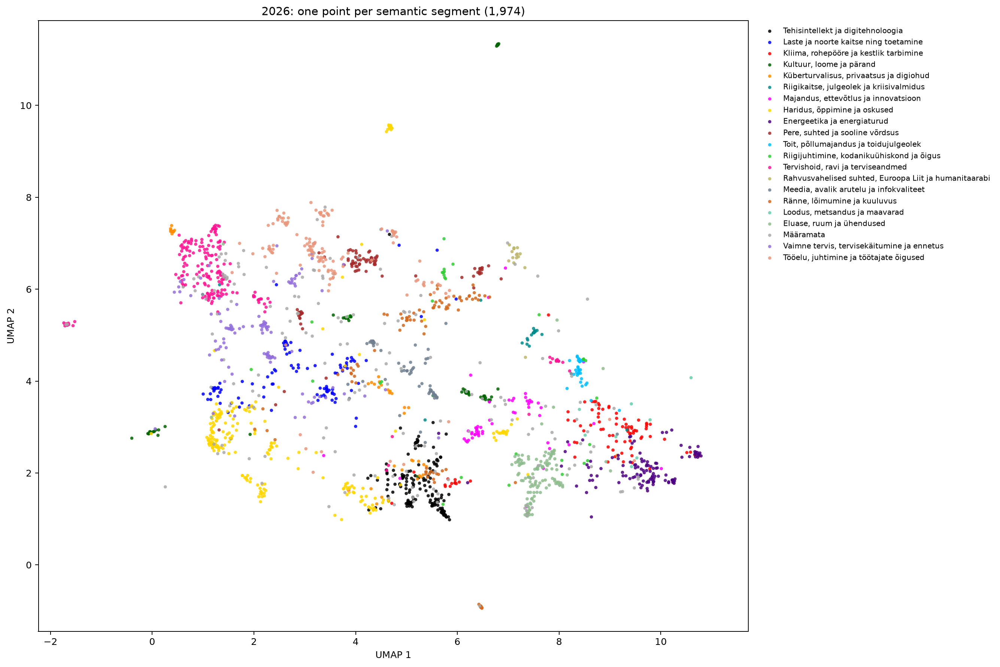

In [12]:
from pathlib import Path
import plotly.io as pio
from IPython.display import Image, Markdown, display
segment_map_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
segment_maps = segment_map_root / "data/topic-analysis/results/jev-semantic-all/segment-maps"
for scope, label in [("all", "Combined: 4,132 segments"), ("2025", "2025: 2,154 segments"),
                     ("2026", "2026: 1,978 segments")]:
    display(Markdown("### " + label))
    figure = pio.from_json((segment_maps / (scope + ".plotly.json")).read_text(encoding="utf-8"))
    display(figure)
    display(Image(filename=str(segment_maps / (scope + ".png"))))
